# val 0.99 vs Kaggle 0.61 원인 분석 EDA (2차 실험)

## EDA의 목적
- 2차 실험의 세 모델(Faster R-CNN, YOLO26, RT-DETR) × 세 방법(v2, v3, v4) × epoch 5/10/20이 모두 val mAP@[0.75:0.95] 0.98~0.997인데, Kaggle public은 0.59~0.62에 멈춘 원인을 찾는다.
    - 리더보드 최고 점수도 0.6306이다. 모든 팀이 같은 상한에 걸려 있다.
- train, val, test를 이전 EDA 노트북에서 가져오지 않고, `src/pill_detection`이 지금 만드는 그대로(`data/datasets/images.csv`, `classes.csv`, `eval/val_gt.json`) 다시 구성해 본다.
- 사용자 가설 네 가지(val이 test를 대표하지 못함, AI Hub category_id 오류, 클래스별 bbox 크기 차이, train·val 누수)를 차례로 검증하고, 로컬 가중치 3개로 val 점수를 재현한 뒤 정답 쪽 손실의 상한을 추정한다.
- 각 섹션의 결과를 2차 val 사용 여부, 3차 비교 지표, category_id 매핑, box 보정, 누수, 채점 방식, 손실 위치에 대한 결정으로 연결하고, 7번 EDA 결론에서 결정 사항 표로 정리한다.

## 용어
- **1차 / 2차**: 실험 차수다.
    - 1차는 대회 Kaggle train 사진만으로 학습했다. 1차 RT-DETR의 Kaggle public 점수는 0.41~0.42다.
    - 2차는 AI Hub 외부 데이터를 더하고 val 1,000장을 따로 뗐다. 세 모델 × v2~v4로 학습했다.
    - "2차 제출"은 2차 RT-DETR-l로 만든 제출 CSV 2개다.
- **자체 파악**: test 사진 842장에 있는 알약 3,229개를 우리가 직접 정리한 목록이다. (`notebooks/eda/02_test_crops.csv`)
    - box는 1차 RT-DETR 모델의 예측 그대로이고, 클래스는 사람이 사진을 보고 하나씩 확인했다.
    - 대회 정답은 공개되지 않는다. 자체 파악은 대회 정답이 아니고, test의 알약 수·클래스·위치를 볼 때 정답 대신 쓴다.

## 알려진 사실 (이 노트북이 다시 재지 않는 값)
| 항목 | 값 | 출처 |
| --- | --- | --- |
| 2차 YOLO26s v2~v4 e5·e10 val / Kaggle | 0.983~0.990 / 0.591~0.613 | `origin/exp/cy-yolo26-exp2` 03 노트북 cell 41 |
| 2차 F-RCNN v3 e10 val / kaggle 47장 / test_only | 0.9949 / 0.9969 / 0.9950 | `runs/models/exp2_v3_frcnn_e10_s0_best.pt`의 `scores` |
| 1차 RT-DETR(Kaggle train만 학습) kaggle 47장 / Kaggle public / 2차 val test_only | 0.96 / 0.41~0.42 / 0.0000 | 03 노트북 cell 47, `origin/exp/rt-detr` exp1 8절 |
| 제출 `exp2_v2_rtdetr-l_e10.csv` | 0.61516 | Kaggle 2026-11-02 |
| 제출 `exp2_v4_rtdetr-l_e5.csv` / score≥0.5만 남김 | 0.61558 / 0.61545 | Kaggle 2026-11-03 (팀원) |
| 진단 제출 scale1.02 / scale0.98 (v2 rtdetr-l e10의 box 너비·높이만 ±2%) | 0.60500 / 0.54908 | Kaggle 2026-11-03 |
| 진단 제출 kaggle_only(56종만) / test_only(18종만) | 0.45344 / 0.16171 | Kaggle 2026-11-03 |
| test 자체 파악 대리 채점(IoU 0.5 AP, 클래스 일치) | 0.996, 99.8% (고치기 전 자체 파악 기준. 5-4에서 고친 자체 파악으로 다시 잰다) | Notion "val과 test 점수가 큰 차이가 나는 이유에 대한 분석" 2-1 |
| 00 8-2 box 오차 민감도(1차 Kaggle train 라벨) | 4px 이동 → 0.87, 8px → 0.64 | `eda/raewoo-external-eda` 00 노트북 cell 95 |

## EDA 목차
> 각 분석 결과 아래에는 **인사이트 / 결론** 마크다운 셀을 두어, 분석 결과와 그에 따른 결정을 기록한다.

0. 사전 설정
    - seed, 경로, 도우미 함수를 정의하고 목록 CSV, val 정답, test 자체 파악, 제출 CSV를 읽는다.
    - 로컬 가중치 3개(2차 v3 e10)로 val 1,000장을 추론한다. (2-2b와 5절에서 쓴다)
1. 분할 재구성과 누수
    - **전처리 후 전체 데이터 구성**
        - 출처별 train·val·test 이미지 수와 split별 출처 구성(이미지·객체 수)을 로그 눈금 막대로 본다.
            - 목적: test와 같은 출처(Kaggle)의 학습·평가 사진이 얼마나 되는지 보고, val을 출처별로 나눠 읽을지 정한다.
    - **목록 재현과 split 구성**
        - `scripts/make_dataset_lists.py --check`로 지금 코드가 `images.csv`를 그대로 만드는지 확인하고, 출처×split×방법별 이미지·객체 수를 센다.
    - **번호 묶음 규칙 검증**
        - Kaggle train id와 test 파일 번호가 한 체계인지, `(번호-1)//3` 묶음이 한 조합을 각도만 바꿔 찍은 사진인지 전수로 확인한다.
    - **자체 파악 K-012778·K-019552 오류 확인**
        - 같은 묶음인데 자체 파악 클래스가 엇갈린 짝을 학습 crop과 나란히 놓고 각인으로 고친다.
            - 목적: 1-2c와 5-4가 쓰는 번호 묶음 규칙과 test 클래스를 확정한다.
    - **조합 단위 누수**
        - train과 val의 조합 겹침, test 842장이 train·val 조합과 같은 장면인지(번호 묶음, 자체 파악 조합)를 센다.
    - **조합 수로 본 train·val·test 겹침**
        - split별 조합 수와 조합당 사진 수, test 조합 중 train·val과 겹치는 조합과 test에만 있는 조합을 한 표로 센다.
            - 목적: 2차 val을 믿고 쓸지 정한다. (가설 4)
    - **육안 확인**
        - val(Kaggle, AI Hub)과 test 사진에 box를 겹쳐 라벨 형태를 눈으로 본다.
2. 클래스 분포
    - **대회 클래스 74개의 split별 객체 수**
        - train·val을 출처(Kaggle, AI Hub)로 나누고 test는 자체 파악으로 센다. train과 val을 한 막대에 쌓은 train+val도 같은 순서로 보고, 클래스별 수는 그림 아래 표에 적는다.
    - **val 비율 vs test 비율**
        - 클래스별 val 비율과 test 비율을 산점도로 비교하고, 상한(`VAL_CLASS_CAP`)에 잘린 클래스를 찾는다.
    - **비율이 어긋난 클래스의 IoU 기준별 val AP**
        - 2-2에서 이름을 적은 10종의 AP@0.75~0.95를 2차 모델 3개로 꺾은선으로 본다.
    - **클래스별 val 근거의 출처**
        - 클래스마다 val AP의 근거가 Kaggle 라벨인지 AI Hub 라벨인지 나눈다.
            - 목적: val이 test 클래스 분포를 대표하는지, 대표하지 못하는 클래스가 무엇인지 정한다. (가설 1)
3. category_id 매핑
    - **dl_idx, drug_N, Kaggle category_id 규칙**
        - AI Hub 원본의 알약 번호 두 가지와 Kaggle 번호의 관계를 클래스 그룹별로 센다.
    - **AI Hub 정제 사본의 번호 전수 확인**
        - 정제 사본 JSON을 모두 읽어 `category_id`, `dl_idx`, `drug_N`이 약 폴더의 K-코드와 같은지 센다.
    - **test 전용 18종의 외형 대조**
        - AI Hub 학습 crop과 test 자체 파악 crop을 나란히 놓아 번호가 아닌 생김새로 매핑을 확인한다.
            - 목적: AI Hub → K-코드 매핑을 계속 믿을지 정한다. (가설 2)
4. bbox 크기와 입력 분포
    - **클래스별 box 크기**
        - 대회 클래스 74개의 box 짧은 변을 Kaggle, AI Hub, test(자체 파악 box)로 나눠 상자 그림으로 본다.
    - **중앙값이 출처마다 다른 클래스의 사진**
        - 출처별 중앙값이 다른 클래스의 box를 사진 위에 겹쳐, 차이가 알약에서 오는지 box를 그린 방식에서 오는지 본다.
    - **출처 간 box 여백 차이**
        - 같은 클래스의 Kaggle·AI Hub 중앙값 너비·높이를 비교한다.
            - 목적: 출처 간 box 스타일 차이가 있어 보정이 필요한지 정한다. (가설 3)
    - **이미지당 알약 수와 밝기**
        - train, val, test의 알약 수 분포와 평균 밝기를 비교한다.
            - 목적: test 입력이 val과 다른 점이 있는지 확인한다.
5. 2차 모델 재현
    - **val 점수 재현**
        - 로컬 가중치 3개(v3 e10)로 val 1,000장을 추론해 점수 3개를 다시 잰다.
    - **IoU 기준별·출처별 AP**
        - IoU 기준 0.75~0.95 각각의 AP를 Kaggle 47장과 AI Hub 953장으로 나눠 본다.
    - **클래스별 val AP**
        - 클래스별 AP와 val 객체 수를 산점도로 본다.
    - **val AP 0.95 이하 클래스의 train·val 객체 수**
        - AP가 낮은 클래스마다 약 이름, 사진, train·val 객체 수를 막대로 보고 학습량이 원인인지 확인한다.
    - **제출 CSV의 자체 파악 대리 채점**
        - 제출 파일 2개를 test 자체 파악으로 채점해 클래스 일치율과 box 일치도를 잰다.
            - 목적: 손실이 모델 쪽에 있는지 val과 자체 파악으로 볼 수 있는 한계까지 확인한다.
6. 정답 쪽 손실 추정 (평가 기준선)
    - **채점 코드 검증**
        - 정답을 예측으로 넣은 점수, 제출 CSV 왕복, 독립 구현과의 일치, 무시 규칙의 영향을 확인한다.
    - **box 오차 민감도**
        - val 정답 box를 이동·배율·무작위 흔들림으로 바꿔 mAP 곡선을 그린다.
    - **Kaggle 실측 적합**
        - "정답 = 우리 box + 이동(또는 흔들림)" 가정에서 배율 0.98/1.00/1.02의 점수 3개를 계산해 Kaggle 실측과 맞는 크기를 찾는다.
    - **라벨 오류 상한 시뮬레이션**
        - 대회 측 가공 규칙을 적용한 원본 라벨을 정답, 우리 정제 라벨을 예측으로 넣어 mAP를 계산한다.
    - **진단 제출 결과 정리**
        - 진단 제출 5개의 점수에서 클래스 그룹별 AP를 역산하고 가설별 판정을 적는다.
            - 목적: test 정답이 우리 라벨과 다를 때 점수가 얼마나 떨어지는지 상한을 잡고, 진단 제출을 해석하는 기준을 만든다.
7. EDA 결론
    - 1~6번의 결과를 2차 val, 3차 비교 지표, category_id, box 보정, 누수, 채점 방식, 손실 위치 항목별 결정 사항 표로 정리한다.

## 0. 사전 설정

In [ ]:
import collections
import csv
import io
import contextlib
import json
import subprocess
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib import font_manager
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image

# 목록·라벨 읽기, 채점, 제출 변환은 공용 모듈의 함수를 그대로 쓴다 (2차 실험과 같은 코드)
from pill_detection.data import combo_name, load_annotations, pill_codes
from pill_detection.datasets import IMAGE_DIRS, TEST_ONLY_CLASSES, VAL_CLASS_CAP, VAL_CLASS_FLOOR, load_images, read_class_table, read_rows
from pill_detection.evaluate import IOU_THRESHOLDS, box_iou, coco_map, competition_from_classes, drop_ignored, evaluate_val, load_gt, predictions_from_ultralytics, write_submission
from pill_detection.utils import xyxy_to_xywh

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"torch        : {torch.__version__}")

In [ ]:
# 랜덤 샘플 시각화 등의 재현성을 위한 seed 고정
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# 노트북을 어디서 실행해도 레포 최상위(pyproject.toml이 있는 폴더)를 기준으로 경로를 잡는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
DATA_DIR = PROJECT_ROOT / 'data'
IMAGES_CSV = DATA_DIR / 'datasets' / 'images.csv'     # 2차 실험 목록 (val 고정)
CLASSES_CSV = DATA_DIR / 'datasets' / 'classes.csv'
DATASET_DIR = DATA_DIR / 'processed' / 'exp2' / 'v3'   # scripts/build_dataset.py가 만든 v3 학습 폴더. val과 eval/val_gt.json은 모든 방법에서 같다
VAL_GT_JSON = DATASET_DIR / 'eval' / 'val_gt.json'
VAL_IMG_DIR = DATASET_DIR / 'images' / 'val'
TEST_IMG_DIR = DATA_DIR / 'raw' / 'test_images'
TEST_CROPS_CSV = PROJECT_ROOT / 'notebooks' / 'eda' / '02_test_crops.csv'  # test 알약 자체 파악 (클래스는 사람이 확인, box는 1차 RT-DETR 예측)
# 자체 파악 클래스는 1-2b에서 고친 corrected_category_id 열을 쓴다. final_category_id는 2차 val을 정할 때 읽은 값이라 그대로 둔다
KAGGLE_RAW_ANN = DATA_DIR / 'raw' / 'train_annotations'                 # 대회 측 가공 결과 그대로
KAGGLE_FIXED_ANN = DATA_DIR / 'processed' / 'train_annotations'         # 우리 정제 라벨
AIHUB_RAW_ANN = DATA_DIR / 'external' / 'aihub' / 'raw' / 'train_annotations'
AIHUB_FIXED_ANN = DATA_DIR / 'processed' / 'ai_hub' / 'train_annotations'
WEIGHTS = {name: PROJECT_ROOT / 'runs' / 'models' / f'exp2_v3_{name}_e10_s0_best.pt' for name in ('yolo26s', 'rtdetr-l', 'frcnn')}
SUBMISSIONS = {'v2 rtdetr-l e10': (PROJECT_ROOT / 'submissions' / 'exp2_v2_rtdetr-l_e10.csv', 0.61516),
               'v4 rtdetr-l e5': (PROJECT_ROOT / 'submissions' / 'exp2_v4_rtdetr-l_e5.csv', 0.61558)}
# 그림과 계산 결과 저장 경로 (runs/는 git에서 제외됨)
FIG_DIR = PROJECT_ROOT / 'runs' / 'eda_raewoo' / 'figures_03'
CACHE_DIR = PROJECT_ROOT / 'runs' / 'eda_raewoo' / 'cache'
for folder in (FIG_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

IMG_W, IMG_H = 976, 1280  # 대회 사진 크기 (너비, 높이). train, AI Hub, test 모두 같다
KAGGLE_SCORES = {'원본': 0.61516, 'scale1.02': 0.60500, 'scale0.98': 0.54908, 'kaggle_only': 0.45344, 'test_only': 0.16171}  # 2026-11-03 진단 제출

# 그래프의 한글이 깨지지 않도록 설치된 한글 폰트 사용 (macOS, Windows, Linux 순)
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if font_name in installed_fonts:
        plt.rcParams['font.family'] = font_name
        break
plt.rcParams['axes.unicode_minus'] = False  # 한글 폰트에서 마이너스 기호가 깨지는 문제 방지


def save_fig(fig, name):
    """그림을 FIG_DIR에 png 파일로 저장한다."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=120, bbox_inches='tight')


def show_table(header, rows):
    """열 이름 리스트와 행 리스트를 마크다운 표로 출력한다."""
    lines = ['| ' + ' | '.join(header) + ' |', '|' + ' --- |' * len(header)]
    lines += ['| ' + ' | '.join(str(value).replace('|', r'\|') for value in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def k_code(category_id):
    """category_id를 K-코드 글자로 바꾼다. (3351 → K-003351)"""
    return f'K-{category_id:06d}'


def crop_square(image, box, pad=0.1, size=128):
    """box 중심에서 긴 변보다 pad만큼 큰 정사각형을 잘라 size×size로 줄인다. 알약 모양이 늘어나지 않는다."""
    x, y, w, h = box
    side = max(w, h) * (1 + pad)
    cx, cy = x + w / 2, y + h / 2
    return image.crop((int(cx - side / 2), int(cy - side / 2), int(cx + side / 2), int(cy + side / 2))).resize((size, size))


def coco_precision(gt, predictions, image_ids=None, category_ids=None, iou_thresholds=IOU_THRESHOLDS):
    """pill_detection.evaluate.coco_map과 같은 설정으로 COCOeval을 돌리고 precision[IoU 기준, recall, 클래스]와 클래스 순서를 돌려준다.

    coco_map은 평균 하나만 돌려주므로, IoU 기준별 AP를 꺼내기 위해 같은 과정을 다시 쓴다. (evaluate.py는 고치지 않는다)
    """
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    image_ids = None if image_ids is None else set(image_ids)
    present = {a['category_id'] for a in gt['annotations'] if image_ids is None or a['image_id'] in image_ids}
    category_ids = sorted(present if category_ids is None else present & set(category_ids))
    image_of = {image['file_name']: image['id'] for image in gt['images']}
    results = [{'image_id': p.get('image_id', image_of.get(p.get('file_name'))), 'category_id': p['category_id'],
                'bbox': list(p['bbox']), 'score': p['score']} for p in predictions]
    gt = {**gt, 'categories': [{'id': c['id']} for c in gt['categories']]
          + [{'id': c} for c in sorted({r['category_id'] for r in results} - {c['id'] for c in gt['categories']})]}
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO()
        coco_gt.dataset = gt
        coco_gt.createIndex()
        evaluator = COCOeval(coco_gt, coco_gt.loadRes(results), 'bbox')
        evaluator.params.iouThrs = np.asarray(iou_thresholds, dtype=float)
        if image_ids is not None:
            evaluator.params.imgIds = sorted(image_ids)
        evaluator.params.catIds = category_ids
        evaluator.evaluate()
        evaluator.accumulate()
    return evaluator.eval['precision'][:, :, :, 0, -1], [int(c) for c in evaluator.params.catIds]


def ap_by_threshold(precision):
    """precision[IoU 기준, recall, 클래스]에서 IoU 기준별 AP(정답 있는 클래스 평균)를 돌려준다. 전체 평균은 COCOeval stats[0]과 같다."""
    return np.array([values[values > -1].mean() if (values > -1).any() else 0.0 for values in precision])


print(f"레포 최상위  : {PROJECT_ROOT}")
print(f"연산 장치    : {DEVICE}")
print(f"그래프 폰트  : {plt.rcParams['font.family'][0]}")
print(f"그림 저장    : {FIG_DIR}")

- 목록 CSV, 정제 라벨, val 정답, test 자체 파악, 제출 CSV를 읽는다.
    - `images.csv`의 split 열이 2차 val을 정한다. 학습 폴더의 `images/val`과 `eval/val_gt.json`은 이 열에서 만들어진다.
    - `load_images`는 2차 목록을 만드는 코드가 쓰는 함수와 같다. Kaggle 232장 + AI Hub 11,974장을 객체 단위로 읽는다.
    - test 자체 파악의 box는 1차 RT-DETR 예측이므로, 알약의 위치·크기·클래스 비교에만 쓰고 IoU 0.75 이상 채점에는 쓰지 않는다.
    - test 클래스는 자체 파악 CSV의 `corrected_category_id`(1-2b에서 K-012778·K-019552 5개를 고친 열)로 읽는다.
        - `final_category_id`는 2차 val을 고를 때 `scripts/make_dataset_lists.py`가 읽은 값이라 바꾸지 않는다. (1-2b 결론)

In [ ]:
images, names = load_images(DATA_DIR)                      # 파일명 → {source, combo, image_id, objects: [(category_id, bbox, ann_id)]}
image_rows = read_rows(IMAGES_CSV)                         # 목록 CSV 줄 (source, file_name, combo, split, v1~v4, ...)
class_table = read_class_table(CLASSES_CSV, 'v3')          # {'classes': idx_v3 순서의 category_id, 'competition': set, 'rows': {category_id: 줄}}
class_rows = class_table['rows']
COMPETITION = class_table['competition']                   # 대회 클래스 74개 = Kaggle 56 + test 전용 18
GROUP_OF = {c: row['group'] for c, row in class_rows.items()}
KAGGLE_CLASSES = {c for c, g in GROUP_OF.items() if g == 'kaggle'}
TEST_ONLY = {c for c, g in GROUP_OF.items() if g == 'test_only'}
val_gt = load_gt(VAL_GT_JSON)
with open(TEST_CROPS_CSV, newline='', encoding='utf-8-sig') as f:
    test_crops = [{**row, 'bbox': json.loads(row['bbox']), 'category_id': int(row['corrected_category_id'])} for row in csv.DictReader(f)]
test_counts = collections.Counter(c['category_id'] for c in test_crops)  # category_id → test 객체 수 (고친 자체 파악)
submissions = {}
for run, (path, _) in SUBMISSIONS.items():
    with open(path, newline='', encoding='utf-8') as f:
        submissions[run] = [{'file_name': f"{row['image_id']}.png", 'category_id': int(row['category_id']), 'score': float(row['score']),
                             'bbox': [float(row[k]) for k in ('bbox_x', 'bbox_y', 'bbox_w', 'bbox_h')]} for row in csv.DictReader(f)]

split_of = {row['file_name']: row['split'] for row in image_rows}
assert len(images) == len(image_rows) == 12206, (len(images), len(image_rows))
assert len(COMPETITION) == 74 and len(KAGGLE_CLASSES) == 56 and TEST_ONLY == set(TEST_ONLY_CLASSES)
assert len(val_gt['images']) == 1000 and len(val_gt['annotations']) == 3790
assert len(test_crops) == 3229 and len({c['test_file'] for c in test_crops}) == 842
val_files = [row['file_name'] for row in image_rows if row['split'] == 'val']
assert set(val_files) == {im['file_name'] for im in val_gt['images']} == {p.name for p in VAL_IMG_DIR.glob('*.png')}
print(f"이미지 {len(images):,}장 (Kaggle {sum(im['source'] == 'kaggle' for im in images.values())}, AI Hub {sum(im['source'] == 'aihub' for im in images.values()):,}), "
      f"val {len(val_files):,}장 객체 {len(val_gt['annotations']):,}개, test 자체 파악 {len(test_crops):,}개, 제출 CSV {len(submissions)}개")

- 로컬 가중치 3개(2차 v3 e10의 YOLO26s, RT-DETR-l, F-RCNN)로 val 1,000장을 추론한다. 2-2b와 5절이 이 예측을 쓴다.
    - 예측은 conf 0.001까지 모두 남기고 `runs/eda_raewoo/cache/03_val_pred_<모델>.json`에 저장한다. 다시 실행할 때는 저장한 파일을 읽는다.
    - 실행 시간: Apple GPU(mps)에서 처음 실행할 때 약 5~15분

In [ ]:
# 2-2b와 5절이 쓰는 val 예측. 로컬 가중치 3개로 val 1,000장을 추론하고, 캐시 파일이 있으면 읽기만 한다
def cached_predictions(name, make):
    """예측을 캐시 JSON에서 읽고, 없으면 make()로 만들어 저장한다."""
    path = CACHE_DIR / f'03_val_pred_{name}.json'
    if path.exists():
        return json.loads(path.read_text())
    start = time.perf_counter()
    predictions = make()
    path.write_text(json.dumps(predictions))
    print(f'{name}: val {len(val_files):,}장 추론 {time.perf_counter() - start:.0f}초, 예측 {len(predictions):,}개')
    return predictions


def ultralytics_predictions(name):
    from ultralytics import RTDETR, YOLO
    model = (RTDETR if name.startswith('rtdetr') else YOLO)(str(WEIGHTS[name]))
    results = model.predict(str(VAL_IMG_DIR), conf=0.001, imgsz=640, device=str(DEVICE), stream=True, verbose=False)
    return predictions_from_ultralytics(results)


def frcnn_predictions(batch_size=4):
    from torchvision.models.detection import fasterrcnn_resnet50_fpn
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    from torchvision.ops import FrozenBatchNorm2d

    def freeze_batchnorm(module):
        """BatchNorm2d를 eps 0인 FrozenBatchNorm2d로 바꾼다. 값은 뒤에서 체크포인트로 채운다. (2차 F-RCNN 노트북과 같다)"""
        for child_name, child in list(module.named_children()):
            if isinstance(child, torch.nn.BatchNorm2d):
                setattr(module, child_name, FrozenBatchNorm2d(child.num_features, eps=0.0))
            elif isinstance(child, FrozenBatchNorm2d):
                child.eps = 0.0
            else:
                freeze_batchnorm(child)

    checkpoint = torch.load(WEIGHTS['frcnn'], map_location='cpu', weights_only=False)
    config = checkpoint['config']
    category_of = {idx + 1: c for idx, c in enumerate(class_table['classes'])}   # 모델 label(0은 배경) → K-코드
    model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=config['image_size'], max_size=config['image_size'])
    freeze_batchnorm(model)
    model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, len(category_of) + 1)
    model.roi_heads.score_thresh = config['score_threshold']
    model.roi_heads.nms_thresh = config['nms_iou']
    model.roi_heads.detections_per_img = config['max_detections']
    model.load_state_dict(checkpoint['model'])
    model.to(DEVICE).eval()
    predictions = []
    with torch.inference_mode():
        for i in range(0, len(val_files), batch_size):
            batch = val_files[i:i + batch_size]
            tensors = [torch.from_numpy(np.asarray(Image.open(VAL_IMG_DIR / f).convert('RGB'), dtype=np.uint8)).permute(2, 0, 1).to(DEVICE).float().div(255) for f in batch]
            for f, output in zip(batch, model(tensors)):
                for box, label, score in zip(output['boxes'].tolist(), output['labels'].tolist(), output['scores'].tolist()):
                    predictions.append({'file_name': f, 'category_id': category_of[label], 'bbox': xyxy_to_xywh(box), 'score': score})
    return predictions


val_predictions = {name: cached_predictions(name, (lambda n=name: ultralytics_predictions(n)) if name != 'frcnn' else frcnn_predictions) for name in WEIGHTS}
print('val 예측 (conf 0.001): ' + ', '.join(f'{name} {len(preds):,}개' for name, preds in val_predictions.items()))

## 1. 분할 재구성과 누수
- 목적: 2차 val을 믿고 쓸지 정한다. train과 val이 같은 장면을 나눠 갖고 있으면 val 점수가 부푼다. (가설 4)
    - 누수란 같은 장면(같은 알약 조합을 찍은 사진)이 train과 val에 나뉘어 들어간 경우를 말한다. 대회 사진은 조합 하나를 각도 3가지로 찍어서, 사진 단위로 나누면 누수가 생긴다. (1-2a)

### 1-1a. 전처리 후 전체 데이터 구성
- 2차 실험 목록 `images.csv`(라벨 정제와 사진 선별을 마친 상태)의 train·val 사진과 대회 test 사진을 막대로 센다.
    - 왼쪽 그림은 출처별 이미지 수다. Kaggle 제공(대회 train 사진)과 AI Hub 외부데이터는 아래 칸 train, 위 칸 val로 쌓는다.
    - 오른쪽 그림은 split별 이미지 수(왼쪽 막대)와 객체 수(오른쪽 막대)다. 아래 칸이 Kaggle, 위 칸이 AI Hub다.
    - train·val 객체 수는 대회 밖 알약까지 센 전체 수다. 대회 클래스만 센 수는 1-1b 표에 있다.
    - test는 정답이 없어 객체 수를 자체 파악 알약 수로 센다.
- y축은 로그 눈금이다. 쌓은 막대에서 칸의 높이는 비율을 나타내지 않으므로 칸 안 숫자로 읽는다.
    - 로그 눈금에서는 위 칸이 실제 비율보다 얇고, 아래 칸이 두껍게 보인다.
    - 왼쪽 그림의 val 칸은 너무 얇아서, 이름표를 칸 바로 아래 막대 안에 붙인다.

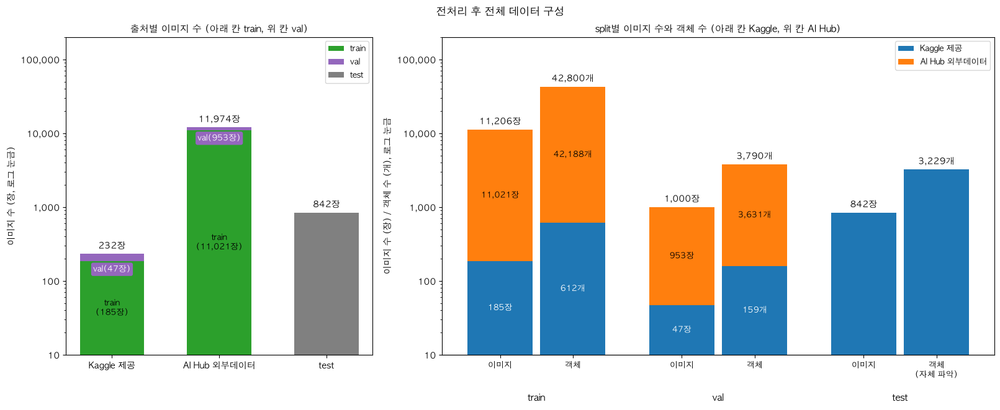

In [ ]:
LOG_BOTTOM = 10   # 로그 눈금의 바닥. 0에서 시작하는 아래 칸은 여기서 잘려 보인다
SPLIT_COLORS = {'train': 'tab:green', 'val': 'tab:purple', 'test': 'gray'}   # 2-1 아래 그림과 같은 색
SOURCE_COLORS = {'kaggle': 'tab:blue', 'aihub': 'tab:orange'}             # 2-1 위 그림과 같은 색

images_n, objects_n = collections.Counter(), collections.Counter()
for row in image_rows:
    images_n[row['source'], row['split']] += 1
    objects_n[row['source'], row['split']] += int(row['n_objects'])
test_files = sorted(TEST_IMG_DIR.glob('*.png'))
assert len(test_files) == len({c['test_file'] for c in test_crops}) == 842
images_n['kaggle', 'test'] = len(test_files)
objects_n['kaggle', 'test'] = len(test_crops)   # test는 정답이 없어 자체 파악 알약 수로 센다


def label_inside(ax, x, low, high, text, color):
    """로그 눈금 막대 칸 [low, high]의 가운데(기하 평균 높이)에 글자를 쓴다."""
    ax.text(x, np.sqrt(low * high), text, ha='center', va='center', fontsize=9, color=color)


def label_total(ax, x, total, unit):
    """막대 위에 합계를 쓴다."""
    ax.annotate(f'{total:,}{unit}', (x, total), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=10)


fig, (ax_source, ax_split) = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True, width_ratios=[1, 1.8], layout='constrained')

# 왼쪽: 출처별 이미지 수. 아래 칸 train, 위 칸 val
for x, source in enumerate(('kaggle', 'aihub')):
    train, val = images_n[source, 'train'], images_n[source, 'val']
    ax_source.bar(x, train, 0.6, color=SPLIT_COLORS['train'], label='train' if x == 0 else None)
    ax_source.bar(x, val, 0.6, bottom=train, color=SPLIT_COLORS['val'], label='val' if x == 0 else None)
    label_inside(ax_source, x, LOG_BOTTOM, train, f'train\n({train:,}장)', 'black')
    # 로그 눈금에서는 위 칸(val)이 아주 얇아 글자가 들어가지 않는다. val 색 이름표를 막대 안 맨 위에 붙인다
    ax_source.annotate(f'val({val:,}장)', (x, train), xytext=(0, -4), textcoords='offset points', ha='center', va='top', fontsize=9, color='white',
                       bbox=dict(boxstyle='round,pad=0.25', facecolor=SPLIT_COLORS['val'], edgecolor='none'))
    label_total(ax_source, x, train + val, '장')
ax_source.bar(2, images_n['kaggle', 'test'], 0.6, color=SPLIT_COLORS['test'], label='test')
label_total(ax_source, 2, images_n['kaggle', 'test'], '장')
ax_source.set_xticks(range(3), ['Kaggle 제공', 'AI Hub 외부데이터', 'test'])
ax_source.set_ylabel('이미지 수 (장, 로그 눈금)')
ax_source.set_title('출처별 이미지 수 (아래 칸 train, 위 칸 val)', fontsize=11)
ax_source.legend(loc='upper right', fontsize=9)

# 오른쪽: split별 이미지 수(왼쪽 막대)와 객체 수(오른쪽 막대). 아래 칸 Kaggle, 위 칸 AI Hub
width = 0.36
for g, split in enumerate(('train', 'val', 'test')):
    for offset, counts, unit in ((-width / 2 - 0.02, images_n, '장'), (width / 2 + 0.02, objects_n, '개')):
        x = g + offset
        kaggle, aihub = counts['kaggle', split], counts['aihub', split]
        ax_split.bar(x, kaggle, width, color=SOURCE_COLORS['kaggle'], label='Kaggle 제공' if (g, unit) == (0, '장') else None)
        if aihub:
            ax_split.bar(x, aihub, width, bottom=kaggle, color=SOURCE_COLORS['aihub'], label='AI Hub 외부데이터' if (g, unit) == (0, '장') else None)
            label_inside(ax_split, x, LOG_BOTTOM, kaggle, f'{kaggle:,}{unit}', 'white')
            label_inside(ax_split, x, kaggle, kaggle + aihub, f'{aihub:,}{unit}', 'black')
        label_total(ax_split, x, kaggle + aihub, unit)
bar_x = [g + s * (width / 2 + 0.02) for g in range(3) for s in (-1, 1)]
ax_split.set_xticks(bar_x, ['이미지', '객체'] * 2 + ['이미지', '객체\n(자체 파악)'], fontsize=9)
group_axis = ax_split.secondary_xaxis('bottom')   # 막대 이름 아래 줄에 split 이름을 쓴다
group_axis.set_xticks(range(3), ['\n\n\ntrain', '\n\n\nval', '\n\n\ntest'], fontsize=11)
group_axis.tick_params(length=0)
ax_split.set_ylabel('이미지 수 (장) / 객체 수 (개), 로그 눈금')
ax_split.tick_params(axis='y', labelleft=True)   # 두 그림이 눈금을 같이 쓰지만 오른쪽에도 숫자를 보인다
ax_split.set_title('split별 이미지 수와 객체 수 (아래 칸 Kaggle, 위 칸 AI Hub)', fontsize=11)
ax_split.legend(loc='upper right', fontsize=9)

ax_source.set_yscale('log')
ax_source.set_ylim(LOG_BOTTOM, 2e5)
ax_source.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
fig.suptitle('전처리 후 전체 데이터 구성')
save_fig(fig, '1-1a_data_composition')
plt.show()

**인사이트**
- Kaggle 제공 사진은 232장(train 185, val 47)이고, AI Hub 외부데이터는 11,974장(train 11,021, val 953)이다. train·val 사진의 98.1%가 AI Hub다.
- test 842장은 모두 Kaggle 사진이다. 같은 출처의 train 사진(185장)보다 4.6배 많다.
    - val 1,000장은 test와 장수가 비슷하지만, 그중 Kaggle 사진은 47장(4.7%)뿐이다.
- 이미지당 객체 수는 train 3.8개(42,800 ÷ 11,206), val 3.8개(3,790 ÷ 1,000), test 3.8개(3,229 ÷ 842)로 같다.
    - train·val 수에는 대회 밖 알약이 들어 있고, test 자체 파악에는 대회 클래스만 있다.

**결론**
- test와 같은 출처(Kaggle)의 평가 근거는 val-Kaggle 47장뿐이다. val 점수는 출처를 나눠 읽고(1-1b의 `kaggle` 점수, 5-2의 출처별 AP), AI Hub 953장의 점수를 test 성능으로 읽지 않는다.
- 이미지당 알약 수는 split 사이에 차이가 없다고 보고, 분포는 4-3에서 비교한다.

### 1-1b. 목록 재현과 split 구성
- `scripts/make_dataset_lists.py --check`를 실행해 지금 `src/` 코드가 `data/datasets/images.csv`, `classes.csv`를 바이트까지 그대로 만드는지 확인한다.
- 출처(Kaggle, AI Hub) × split(train, val)별로 이미지 수, 객체 수, 대회 클래스 객체 수, 방법 v1~v4의 train 포함 이미지 수를 센다.

In [ ]:
check = subprocess.run([sys.executable, 'scripts/make_dataset_lists.py', '--check'], cwd=PROJECT_ROOT, capture_output=True, text=True)
assert check.returncode == 0, check.stdout + check.stderr   # 0이면 지금 코드가 CSV 2개를 그대로 재현한다

rows = []
totals = collections.Counter()
for source in ('kaggle', 'aihub'):
    for split in ('train', 'val'):
        chosen = [row for row in image_rows if row['source'] == source and row['split'] == split]
        n_objects = sum(int(row['n_objects']) for row in chosen)
        n_competition = sum(int(row['n_competition']) for row in chosen)
        variants = [sum(row[v] == '1' for row in chosen) if split == 'train' else '-' for v in ('v1', 'v2', 'v3', 'v4')]
        rows.append([{'kaggle': 'Kaggle', 'aihub': 'AI Hub'}[source], split, f'{len(chosen):,}', f'{n_objects:,}', f'{n_competition:,}',
                     *[f'{v:,}' if v != '-' else v for v in variants]])
        totals.update({'images': len(chosen), 'objects': n_objects, 'competition': n_competition})
rows.append(['**합계**', '', f"**{totals['images']:,}**", f"**{totals['objects']:,}**", f"**{totals['competition']:,}**", '', '', '', ''])
show_table(['출처', 'split', '이미지 수', '객체 수', '대회 클래스 객체 수', 'v1 train', 'v2 train', 'v3 train', 'v4 train'], rows)

| 출처 | split | 이미지 수 | 객체 수 | 대회 클래스 객체 수 | v1 train | v2 train | v3 train | v4 train |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle | train | 185 | 612 | 612 | 185 | 185 | 185 | 185 |
| Kaggle | val | 47 | 159 | 159 | - | - | - | - |
| AI Hub | train | 11,021 | 42,188 | 25,636 | 11,021 | 6,944 | 8,789 | 11,021 |
| AI Hub | val | 953 | 3,631 | 2,894 | - | - | - | - |
| **합계** |  | **12,206** | **46,590** | **29,301** |  |  |  |  |

**인사이트**
- `--check`가 통과했다. 지금 `src/` 코드가 `images.csv`와 `classes.csv`를 그대로 다시 만든다.
- val 1,000장은 Kaggle 47장(159객체) + AI Hub 953장(3,631객체)이다. 대회 클래스 객체는 3,053개이고, 나머지 737개는 대회 밖 알약(채점에서 무시 영역)이다.
    - val 이미지의 95.3%, 대회 클래스 객체의 94.8%가 AI Hub 사진이다.
- train은 Kaggle 185장(612객체)이 네 방법에 모두 들어가고, AI Hub 11,021장 중 v2 6,944장, v3 8,789장, v1·v4 11,021장이 들어간다.

**결론**
- val 점수(`val`)는 사실상 "우리가 정제한 AI Hub 라벨 기준 점수"이고, 대회 측 라벨로 잰 점수는 Kaggle 47장의 `kaggle` 점수뿐이다. 두 점수를 늘 함께 봐야 한다. (2-3에서 클래스별로 다시 센다)
    - 만약에 Kaggle 47장의 validation 점수는 낮게 나오는데 AI Hub 953장의 점수만 높게 나온다면, 이는 라벨 정제가 잘못되었음을 시사한다. 
- 목록은 코드가 재현하므로, 이후 분석은 `images.csv`를 그대로 읽어 쓴다.

### 1-2a. 번호 묶음 규칙 검증
- 1-2c와 02 노트북은 "Kaggle train의 `images[0].id`와 test 파일 번호는 한 체계이고, `(번호-1)//3`이 같으면 같은 조합을 각도만 바꿔 찍은 사진이다"라는 규칙을 쓴다. (00 5-2에서 처음 찾음)
    - DATA.md는 train image_id가 파일명마다 겹치지 않게 순서대로 붙는다고만 적고, test 번호와의 관계는 적지 않는다. 그래서 데이터로 전수 확인한다.
- 규칙대로 3개씩 묶은 결과를, 묶음 경계를 1칸·2칸 민 대조군과 비교한다. 규칙이 맞으면 규칙 열만 0개 또는 100%가 나온다.
    - train: Kaggle 원본 JSON의 id, 파일명의 조합, 촬영 정보(`camera_la` = 카메라 위도, `camera_lo` = 카메라 경도, 배경, 조명, 앞뒷면, 크기)를 쓴다.
    - test ↔ train: test 사진의 1차 RT-DETR 원래 예측 클래스(`pred_category_id`)가 같은 묶음 train 조합의 K-코드 안에 모두 드는지 본다.
        - 자체 파악 최종 클래스는 여기서 쓰지 않는다. 02 노트북이 train과 같은 묶음인 test 사진의 클래스를 이 규칙으로 정했기 때문에(02 2-2), 검증에 쓰면 순환 논증이 된다.
    - test ↔ test: train 사진이 없고 test가 2장 이상인 묶음에서 자체 파악 클래스 집합이 같은지 본다.
- 읽는 법: `a / b`는 "b개 중 a개"이다. 마지막 열은 규칙이 맞을 때 나와야 하는 값이다.

In [ ]:
# Kaggle 원본 train JSON의 images[0] (대회 측 가공 결과 그대로): 파일명 → (id, 촬영 정보)
SHOT_KEYS = ('camera_la', 'camera_lo', 'back_color', 'light_color', 'drug_dir', 'size')
raw_shots = collections.defaultdict(set)
for path in KAGGLE_RAW_ANN.rglob('*.json'):
    image = json.loads(path.read_text(encoding='utf-8-sig'))['images'][0]
    raw_shots[image['file_name']].add((image['id'], *(image[k] for k in SHOT_KEYS)))
assert all(len(v) == 1 for v in raw_shots.values()), '한 사진의 JSON들이 서로 다른 id나 촬영 정보를 갖는다'
raw_shots = {name: next(iter(v)) for name, v in raw_shots.items()}  # (id, camera_la, camera_lo, 배경, 조명, 앞뒷면, 크기)
train_number = {name: shot[0] for name, shot in raw_shots.items()}
assert len(set(train_number.values())) == len(train_number) == 232, 'train id가 겹치거나 사진 수가 232장이 아니다'
test_numbers = sorted(int(p.stem) for p in TEST_IMG_DIR.glob('*.png'))
train_codes = {name: {int(code) for code in combo_name(name).split('-')[1:]} for name in train_number}

# test 사진별 클래스 집합: 1차 예측(규칙과 무관), 자체 파악 final_category_id, 자체 파악 corrected_category_id
pred_set, final_set, fixed_set = collections.defaultdict(set), collections.defaultdict(set), collections.defaultdict(set)
for crop in test_crops:
    n = int(Path(crop['test_file']).stem)
    if crop['pred_category_id']:  # 02 1-2에서 그려 넣은 box는 1차 예측이 없다
        pred_set[n].add(int(crop['pred_category_id']))
    final_set[n].add(int(crop['final_category_id']))
    fixed_set[n].add(crop['category_id'])


def check_grouping(offset):
    """번호를 (번호 - 1 + offset) // 3 으로 묶었을 때의 검증 수치. offset 0이 규칙이고, 1·2는 경계를 민 대조군이다."""
    def group(n):
        return (n - 1 + offset) // 3

    train_groups = collections.defaultdict(list)
    for name, n in train_number.items():
        train_groups[group(n)].append(name)
    train_multi = [names for names in train_groups.values() if len(names) > 1]
    combo_groups = collections.defaultdict(set)
    for name, n in train_number.items():
        combo_groups[combo_name(name)].add(group(n))
    group_codes = {g: set().union(*(train_codes[name] for name in names)) for g, names in train_groups.items()}
    paired = [n for n in test_numbers if group(n) in group_codes and pred_set[n]]
    test_groups = collections.defaultdict(list)  # train 사진이 없는 묶음의 test 사진
    for n in test_numbers:
        if group(n) not in train_groups:
            test_groups[group(n)].append(n)
    test_multi = [ns for ns in test_groups.values() if len(ns) > 1]

    def agree(sets):
        return sum(len({frozenset(sets[n]) for n in ns}) == 1 for ns in test_multi)

    return {'train_mixed': (sum(len({combo_name(name) for name in names}) > 1 for names in train_multi), len(train_multi)),
            'combo_split': (sum(len(gs) > 1 for gs in combo_groups.values()), len(combo_groups)),
            'pred_inside': (sum(pred_set[n] <= group_codes[group(n)] for n in paired), len(paired)),
            'final_agree': (agree(final_set), len(test_multi)), 'fixed_agree': (agree(fixed_set), len(test_multi)),
            'train_multi': train_multi, 'test_multi': test_multi}


def ratio(pair, pct=False):
    return f'{pair[0]:,} / {pair[1]:,}' + (f' ({pair[0] / pair[1]:.1%})' if pct else '')


checks = {offset: check_grouping(offset) for offset in (0, 1, 2)}
rule = checks[0]
numbers = set(train_number.values()) | set(test_numbers)
top = max(numbers)
angles = collections.Counter(shot[1] for shot in raw_shots.values())
angle_dup = sum(len({raw_shots[name][1] for name in names}) < len(names) for names in rule['train_multi'])
other_diff = sum(len({raw_shots[name][2:] for name in names}) > 1 for names in rule['train_multi'])
first_angle = min(angles)
angle_slot = collections.Counter((n - 1) % 3 for name, n in train_number.items() if raw_shots[name][1] == first_angle)
photos_per_group = collections.Counter((n - 1) // 3 for n in numbers)
disputed_groups = [ns for ns in rule['test_multi'] if len({frozenset(final_set[n]) for n in ns}) > 1]
disputed_text = ', '.join('·'.join(map(str, ns)) + ' (' + ', '.join(k_code(c) for c in sorted(set.union(*(final_set[n] for n in ns)) - set.intersection(*(final_set[n] for n in ns)))) + ')'
                          for ns in disputed_groups) or '없음'
show_table(['검증 항목', '규칙: (번호-1)//3', '대조: 경계 1칸 밈', '대조: 경계 2칸 밈', '규칙이 맞으면'], [
    ['train id와 test 번호가 겹치는 번호', f"{len(set(train_number.values()) & set(test_numbers))}개 (train {len(train_number)}장 {min(train_number.values())}~{max(train_number.values())}, test {len(test_numbers)}장 {test_numbers[0]}~{test_numbers[-1]})",
     '-', '-', f'0개. 서로 다른 체계가 1~{top}에 흩어졌다면 약 {len(train_number) * len(test_numbers) / top:.0f}개가 겹친다'],
    [f'1~{top} 중 train·test 어디에도 없는 번호', f'{top - len(numbers)}개', '-', '-', '공개되지 않은 사진의 번호'],
    ['train 2장 이상 묶음 중 조합이 섞인 묶음', ratio(rule['train_mixed']), ratio(checks[1]['train_mixed']), ratio(checks[2]['train_mixed']), '0개'],
    ['train 조합 중 두 묶음 이상에 걸친 조합', ratio(rule['combo_split']), ratio(checks[1]['combo_split']), ratio(checks[2]['combo_split']), '0개'],
    ['train 2장 이상 묶음 중 camera_la가 겹치는 묶음', f"{angle_dup} / {len(rule['train_multi'])} (값 {', '.join(f'{a}°' for a in sorted(angles))})", '-', '-', '0개. 한 묶음 = 같은 조합을 위도마다 한 장씩'],
    ['train 2장 이상 묶음 중 camera_lo·배경·조명·앞뒷면·크기가 다른 묶음', f"{other_diff} / {len(rule['train_multi'])}", '-', '-', '0개. 각도 말고는 촬영 조건이 같다'],
    [f'camera_la {first_angle}° 사진의 묶음 안 자리 (첫째 / 둘째 / 셋째)', ' / '.join(str(angle_slot[i]) for i in range(3)), '-', '-', '규칙과 무관. 각도 순서가 고정인지 본다'],
    ['test 사진 중 1차 예측 클래스가 모두 같은 묶음 train 조합 안에 드는 사진', ratio(rule['pred_inside'], True), ratio(checks[1]['pred_inside'], True), ratio(checks[2]['pred_inside'], True), '100%'],
    ['train이 없고 test가 2장 이상인 묶음 중 자체 파악 클래스 집합이 같은 묶음 (final_category_id)', ratio(rule['final_agree'], True), ratio(checks[1]['final_agree'], True), ratio(checks[2]['final_agree'], True), '100%'],
    ['같은 항목 (corrected_category_id, 1-2b에서 고친 열)', ratio(rule['fixed_agree'], True), ratio(checks[1]['fixed_agree'], True), ratio(checks[2]['fixed_agree'], True), '100%'],
    ['final_category_id 기준으로 어긋난 묶음 (test 번호, 엇갈린 클래스)', disputed_text, '-', '-', '1-2b에서 각인으로 확인'],
    ['사진이 1장뿐이라 짝으로 검증하지 못한 묶음', ratio((sum(v == 1 for v in photos_per_group.values()), len(photos_per_group))), '-', '-', ''],
])

| 검증 항목 | 규칙: (번호-1)//3 | 대조: 경계 1칸 밈 | 대조: 경계 2칸 밈 | 규칙이 맞으면 |
| --- | --- | --- | --- | --- |
| train id와 test 번호가 겹치는 번호 | 0개 (train 232장 14~1499, test 842장 1~1500) | - | - | 0개. 서로 다른 체계가 1~1500에 흩어졌다면 약 130개가 겹친다 |
| 1~1500 중 train·test 어디에도 없는 번호 | 426개 | - | - | 공개되지 않은 사진의 번호 |
| train 2장 이상 묶음 중 조합이 섞인 묶음 | 0 / 78 | 11 / 54 | 9 / 58 | 0개 |
| train 조합 중 두 묶음 이상에 걸친 조합 | 0 / 114 | 69 / 114 | 64 / 114 | 0개 |
| train 2장 이상 묶음 중 camera_la가 겹치는 묶음 | 0 / 78 (값 70°, 75°, 90°) | - | - | 0개. 한 묶음 = 같은 조합을 위도마다 한 장씩 |
| train 2장 이상 묶음 중 camera_lo·배경·조명·앞뒷면·크기가 다른 묶음 | 0 / 78 | - | - | 0개. 각도 말고는 촬영 조건이 같다 |
| camera_la 70° 사진의 묶음 안 자리 (첫째 / 둘째 / 셋째) | 60 / 9 / 3 | - | - | 규칙과 무관. 각도 순서가 고정인지 본다 |
| test 사진 중 1차 예측 클래스가 모두 같은 묶음 train 조합 안에 드는 사진 | 110 / 110 (100.0%) | 49 / 192 (25.5%) | 52 / 189 (27.5%) | 100% |
| train이 없고 test가 2장 이상인 묶음 중 자체 파악 클래스 집합이 같은 묶음 (final_category_id) | 257 / 260 (98.8%) | 49 / 244 (20.1%) | 38 / 248 (15.3%) | 100% |
| 같은 항목 (corrected_category_id, 1-2b에서 고친 열) | 260 / 260 (100.0%) | 49 / 244 (20.1%) | 38 / 248 (15.3%) | 100% |
| final_category_id 기준으로 어긋난 묶음 (test 번호, 엇갈린 클래스) | 382·384 (K-012778, K-019552), 412·413·414 (K-012778, K-019552), 1282·1284 (K-012778, K-019552) | - | - | 1-2b에서 각인으로 확인 |
| 사진이 1장뿐이라 짝으로 검증하지 못한 묶음 | 124 / 498 | - | - |  |

**인사이트**
- train id와 test 번호는 하나도 겹치지 않는다. train 232장(14~1499)과 test 842장(1~1500)이 1~1500 안에 섞여 있고, 빈 번호는 426개다.
    - 서로 다른 체계의 번호였다면 약 130개가 겹쳐야 한다. 0개이므로 두 번호는 한 체계를 나눠 가진 것이다.
- 3개씩 묶으면 train 조합과 묶음이 정확히 1:1이다. 2장 이상 묶음 78개 중 조합이 섞인 묶음이 0개, 조합 114개 중 두 묶음에 걸친 조합이 0개다.
    - 경계를 1칸·2칸 밀면 섞인 묶음이 11·9개, 걸친 조합이 69·64개로 늘어난다. 묶음 경계는 정확히 1~3, 4~6, … 자리에 있다.
- 한 묶음 안의 사진은 camera_la(카메라 위도)만 70°·75°·90°로 다르고, camera_lo·배경·조명·앞뒷면·크기는 같다. 위도가 겹치는 묶음은 0개다.
    - 70° 사진은 묶음의 첫째 자리가 60장, 둘째 9장, 셋째 3장이다. 묶음 안 순서가 각도를 정하지는 않는다.
- test 쪽에서도 규칙이 맞는다. train과 같은 묶음인 test 110장은 모두 1차 예측 클래스가 그 train 조합 안에 든다. 경계를 밀면 25.5%·27.5%로 떨어진다.
- train이 없는 test 묶음 260개 중 257개는 자체 파악(`final_category_id`) 클래스 집합이 같다. 경계를 밀면 20.1%·15.3%다.
    - 어긋난 3개(382·384, 412·413·414, 1282·1284)는 모두 K-012778과 K-019552가 엇갈린 묶음이다. 1-2b에서 고친 열로는 260개 모두 같다.
- 사진이 1장뿐인 묶음 124개(498개 중)는 짝이 없어 이 방법으로 확인하지 못한다.

**결론**
- "train id와 test 번호는 한 체계이고 `(번호-1)//3`이 같으면 같은 조합"을 사실로 보고, 1-2c의 번호 묶음 방법에 쓴다.
- test 사진의 각도는 test에 촬영 정보가 없어 직접 확인하지 못한다. train 묶음의 각도 구성과 test 묶음의 클래스 일치를 근거로 "같은 조합을 각도만 바꿔 찍은 사진"으로 본다.
- 묶음 안 클래스 일치는 자체 파악 오류를 찾는 검사로도 쓴다. 엇갈린 3개 묶음은 1-2b에서 각인으로 확인한다.

### 1-2b. 자체 파악 K-012778·K-019552 오류 확인
- 1-2a에서 자체 파악 클래스가 묶음 안에서 엇갈린 묶음은 모두 K-012778과 K-019552가 바뀐 경우였다.
    - 두 클래스는 크기가 비슷한 갈색 타원형이고, 앞면 각인도 둘 다 Y와 H이다. 그림 제목에 학습 데이터 JSON의 각인과 크기를 적는다.
- 묶음에 짝 사진이 없는 crop은 1-2a로 찾을 수 없다. 그래서 자체 파악에서 이 짝으로 적힌 crop을 모두 Kaggle train 기준 crop과 나란히 놓고 각인으로 확인한다.
    - 고친 클래스는 자체 파악 CSV의 `corrected_category_id` 열에, 고친 근거는 `note` 열에 적었다. 그림은 고친 뒤 클래스로 묶는다.
    - 빨간 테두리는 고친 crop, 파란 테두리는 Kaggle train 기준 crop(seed 고정)이다.

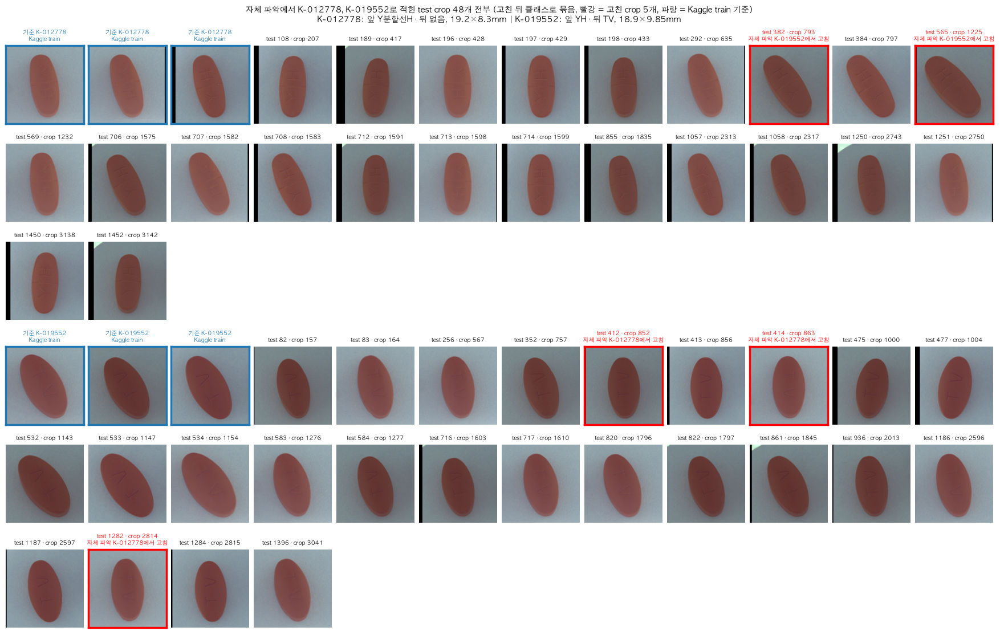

In [ ]:
PAIR = (12778, 19552)  # 1-2a에서 묶음 안에서 엇갈린 짝
COLS, N_REF = 12, 3
ref_rng = np.random.default_rng(SEED)
pill_info = {}  # 학습 데이터 JSON의 각인과 크기 (mm)
for code_ in PAIR:
    image = json.loads(next(KAGGLE_RAW_ANN.glob(f'*_json/{k_code(code_)}/*.json')).read_text(encoding='utf-8-sig'))['images'][0]
    pill_info[code_] = f"앞 {image['print_front'] or '없음'} · 뒤 {image['print_back'] or '없음'}, {image['leng_long']}×{image['leng_short']}mm"
blocks = []
for code_ in PAIR:
    objects = [(name, box) for name, im in images.items() if im['source'] == 'kaggle' for c, box, _ in im['objects'] if c == code_]
    refs = [objects[i] for i in sorted(ref_rng.choice(len(objects), min(N_REF, len(objects)), replace=False))]
    tests = sorted((c for c in test_crops if c['category_id'] == code_), key=lambda c: int(Path(c['test_file']).stem))
    blocks.append((code_, refs, tests))
n_rows = sum(int(np.ceil((len(refs) + len(tests)) / COLS)) for _, refs, tests in blocks)
fig, axes = plt.subplots(n_rows, COLS, figsize=(COLS * 1.45, n_rows * 1.85), layout='constrained', squeeze=False)
for ax in axes.flat:
    ax.axis('off')
row = 0
n_fixed = 0
for code_, refs, tests in blocks:
    tiles = [('ref', name, box) for name, box in refs] + [('test', crop, crop['bbox']) for crop in tests]
    for i, (kind, item, box) in enumerate(tiles):
        ax = axes[row + i // COLS, i % COLS]
        if kind == 'ref':
            ax.imshow(crop_square(Image.open(DATA_DIR / IMAGE_DIRS['kaggle'] / item).convert('RGB'), box, size=192))
            title, color = f'기준 {k_code(code_)}\nKaggle train', 'tab:blue'
        else:
            ax.imshow(crop_square(Image.open(TEST_IMG_DIR / item['test_file']).convert('RGB'), box, size=192))
            fixed = int(item['final_category_id']) != code_
            n_fixed += fixed
            title = f"test {Path(item['test_file']).stem} · crop {item['crop_id']}" + (f"\n자체 파악 {k_code(int(item['final_category_id']))}에서 고침" if fixed else '')
            color = 'red' if fixed else None
        ax.set_title(title, fontsize=7, color=color or 'black')
        if color:
            ax.axis('on')
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_color(color)
                spine.set_linewidth(2.5)
    row += int(np.ceil(len(tiles) / COLS))
fig.suptitle(f'자체 파악에서 K-012778, K-019552로 적힌 test crop {sum(len(t) for _, _, t in blocks)}개 전부 (고친 뒤 클래스로 묶음, 빨강 = 고친 crop {n_fixed}개, 파랑 = Kaggle train 기준)\n'
             + ' | '.join(f'{k_code(c)}: {pill_info[c]}' for c in PAIR), fontsize=10)
save_fig(fig, '1-2b_pair_crops')
plt.show()

**인사이트**
- 자체 파악에서 K-012778·K-019552로 적힌 test crop 48개를 모두 확인했고, 5개가 다른 클래스였다.
    - 1-2a의 묶음 검사로 찾은 4개: 382.png crop 793(K-019552 → K-012778), 412.png crop 852·414.png crop 863·1282.png crop 2814(셋 다 K-012778 → K-019552).
    - 묶음에 짝 사진이 없어 전수 확인으로 찾은 1개: 565.png crop 1225(K-019552 → K-012778). 2차 제출 2개도 이 알약을 K-012778로 예측했다. (5-4)
- 두 클래스는 생김새로 구분된다. K-012778은 가늘고 긴 타원(19.2×8.3mm)에 분할선을 사이에 둔 Y·H 각인이 있고, K-019552는 더 넓은 타원(18.9×9.85mm)이고 뒷면에 TV 각인이 있다.
    - 고친 뒤 test의 K-019552 25개는 모두 TV 면이 위로 보이고, K-012778 23개는 모두 분할선 있는 면이 보인다.
- 고친 5개는 모두 02 노트북에서 1차 RT-DETR 예측을 그대로 최종 클래스로 둔 crop이다. (`auto_source` = prediction)

**결론**
- 자체 파악 CSV에 `corrected_category_id` 열을 추가해 5개를 고치고, 근거를 `note` 열에 적었다. 이 노트북은 0절부터 이 열을 test 클래스로 쓴다.
- `final_category_id`는 고치지 않는다. `scripts/make_dataset_lists.py`가 이 열로 클래스별 test 객체 수를 세어 2차 val을 고르기 때문이다.
    - 이 열을 고친 값으로 바꾸고 `--check`를 돌리면 `images.csv` 139줄이 바뀐다. 2차 val이 바뀌면 이미 돌린 실험과 비교할 수 없다.
    - 02 노트북을 다시 실행하면 자체 파악 CSV를 새로 써서 `corrected_category_id` 열이 사라진다. 다시 실행해야 하면 이 열과 `note`를 먼저 옮겨 둔다.
- 자체 파악을 test 정답 대리로 쓸 때는 1-2a의 묶음 검사를 함께 돌린다. 1차 모델이 헷갈린 짝은 자체 파악에도 남을 수 있다.

### 1-2c. 조합 단위 누수
- train과 val의 조합(파일명 앞부분 `K-…-…` = 사진에 놓인 알약 묶음)이 겹치는 수를 출처별로 센다.
- test 842장이 train·val과 같은 장면(같은 조합을 각도만 바꿔 찍은 사진)인지 두 방법으로 센다.
    - 번호 묶음: test 번호와 `(번호-1)//3`이 같은 train·val 사진이 있으면 그 조합이다. (1-2a)
        - AI Hub 사진에는 이 번호가 없어서, Kaggle 조합과 같은 장면만 찾는다.
    - 자체 파악 조합: test 사진마다 자체 파악(`corrected_category_id`)의 K-코드 집합을 만들고, train·val 어느 사진 라벨의 K-코드 집합과 같은지 본다.
        - 조합 이름이 곧 K-코드 집합이므로, 자체 파악으로 test 사진의 조합 이름을 다시 만들어 맞춰 보는 셈이다. AI Hub 조합도 비교한다.

In [ ]:
combos = {(source, split): {im['combo'] for name, im in images.items() if im['source'] == source and split_of[name] == split}
          for source in ('kaggle', 'aihub') for split in ('train', 'val')}
overlap = {source: len(combos[(source, 'train')] & combos[(source, 'val')]) for source in ('kaggle', 'aihub')}
cross = len((combos[('kaggle', 'train')] | combos[('kaggle', 'val')]) & (combos[('aihub', 'train')] | combos[('aihub', 'val')]))

# 방법 1: 번호 묶음. Kaggle 이미지 번호 (n-1)//3 → split
group_split = {}
for name, im in images.items():
    if im['source'] == 'kaggle':
        group_split[(im['image_id'] - 1) // 3] = split_of[name]
test_files = sorted({c['test_file'] for c in test_crops}, key=lambda f: int(Path(f).stem))
by_number = collections.Counter(group_split.get((int(Path(f).stem) - 1) // 3, 'new') for f in test_files)

# 방법 2: 자체 파악 조합. test 사진의 클래스 집합 → train/val 조합의 클래스 집합과 비교
class_sets = {}
for name, im in images.items():
    class_sets.setdefault(frozenset(c for c, _, _ in im['objects']), set()).add((im['source'], split_of[name]))
test_class_set = {}
for crop in test_crops:
    test_class_set.setdefault(crop['test_file'], set()).add(crop['category_id'])
by_classes = collections.Counter()
for f in test_files:
    where = class_sets.get(frozenset(test_class_set[f]), set())
    key = 'new' if not where else 'train' if any(s == 'train' for _, s in where) else 'val'
    by_classes[key] += 1
label = {'train': 'train 조합과 같은 장면', 'val': 'val 조합과 같은 장면', 'new': 'train·val에 없는 새 조합'}
rows = [[label[k], f"{by_number[k]:,}", f"{by_classes[k]:,}"] for k in ('train', 'val', 'new')]
rows.append(['**test 합계**', f"**{sum(by_number.values()):,}**", f"**{sum(by_classes.values()):,}**"])
rows.append(['train∩val 조합 (Kaggle / AI Hub / 출처 간)', f"{overlap['kaggle']} / {overlap['aihub']} / {cross}", ''])
show_table(['구분', 'test 장수 (번호 묶음 기준)', 'test 장수 (자체 파악 조합 기준)'], rows)

| 구분 | test 장수 (번호 묶음 기준) | test 장수 (자체 파악 조합 기준) |
| --- | --- | --- |
| train 조합과 같은 장면 | 82 | 82 |
| val 조합과 같은 장면 | 28 | 28 |
| train·val에 없는 새 조합 | 732 | 732 |
| **test 합계** | **842** | **842** |
| train∩val 조합 (Kaggle / AI Hub / 출처 간) | 0 / 0 / 0 |  |

**인사이트**
- train과 val의 조합 겹침은 Kaggle 0, AI Hub 0, 출처 사이 0이다. 같은 장면이 양쪽에 나뉜 경우가 없다.
- test 842장 중 732장(87%)은 train·val 어디에도 없는 새 조합이고, 82장은 train 조합의 다른 각도 사진, 28장은 val 조합의 다른 각도 사진이다.
    - 자체 파악 조합으로 세도 82 / 28 / 732장으로 두 방법이 같다. 같은 장면은 모두 Kaggle 조합이고, AI Hub 조합과 클래스 집합이 같은 test 사진은 없다.
    - 고치기 전 자체 파악으로는 83 / 28 / 731장이었다. 1장 차이는 1282.png의 자체 파악 오류(1-2b)가 train 조합 K-002483-003743-012778-013395와 같은 집합을 만든 것이다.
    - test의 110장은 train·val과 같은 장면이므로 test가 train에 불리한 분할은 아니다.

**결론**
- 가설 4(train·val 누수)는 아니다. val 점수가 누수로 부풀지 않았으므로 2차 val을 그대로 쓴다.
- val 47장의 장면이 test에 28장 들어 있다. val-Kaggle 점수는 test 점수와 가장 가까운 로컬 지표다.

### 1-2d. 조합 수로 본 train·val·test 겹침
- 1-2c는 test 사진 장수로 셌다. 여기서는 조합(사진에 놓인 알약의 K-코드 집합) 하나를 한 단위로 세어, split마다 조합이 몇 개이고 split끼리 몇 개가 겹치는지 한 표로 본다.
    - train·val의 조합은 파일명의 조합 이름이다. 12,206장 모두 파일명 조합과 라벨의 클래스 집합이 같다. (코드의 assert)
    - test의 조합은 자체 파악의 `corrected_category_id` 집합이다. (1-2c와 같은 방법)
- 조합당 사진 수는 그 줄이 세는 split에서 한 조합이 찍힌 사진 수다. 1-2a에서 Kaggle 사진은 한 조합을 3장씩 찍은 묶음임을 확인했다.
    - test 아래 └ 세 줄의 사진 수와 조합당 사진 수는 test 사진 기준이다.
    - 전체 두 줄은 해당 split들의 사진을 합쳐 센다.
- 내역 열에 조합 수 덧셈을 적는다. train + val = train+val 전체, test = train과 겹침 + val과 겹침 + test에만이 되는지 표에서 바로 확인한다.

In [ ]:
# 조합 = 사진에 놓인 알약의 K-코드 집합. train·val은 파일명의 조합 이름, test는 자체 파악(corrected_category_id)으로 만든다
assert all(frozenset(c for c, _, _ in im['objects']) == frozenset(pill_codes(name)) for name, im in images.items())  # 파일명 조합 = 라벨 클래스 집합
photos_per_combo = {split: collections.Counter() for split in ('train', 'val', 'test')}   # split → {조합: 그 split의 사진 수}
combo_source = {}
for name, im in images.items():
    combo = frozenset(pill_codes(name))
    photos_per_combo[split_of[name]][combo] += 1
    combo_source[combo] = im['source']
for f in test_files:
    photos_per_combo['test'][frozenset(test_class_set[f])] += 1   # test_class_set: 1-2c에서 만든 test 사진 → 자체 파악 클래스 집합
train_combos, val_combos, test_combos = (set(photos_per_combo[split]) for split in ('train', 'val', 'test'))
test_in_train, test_in_val = test_combos & train_combos, test_combos & val_combos
test_only = test_combos - train_combos - val_combos
trainval_photos = photos_per_combo['train'] + photos_per_combo['val']
all_photos = trainval_photos + photos_per_combo['test']   # 조합 → train·val·test 사진 수 합


def combo_row(label, combos, photos, detail):
    """조합 묶음 하나를 표 한 줄로 만든다. 조합당 사진 수는 photos(조합 → 사진 수)로 센다."""
    n_photos = [photos[c] for c in combos]
    count = f'{len(combos):,}'
    if label.startswith('**'):   # 전체 줄은 조합 수도 굵게
        count = f'**{count}**'
    return [label, count, detail, f'{sum(n_photos):,}', min(n_photos), max(n_photos)]


def by_source(combos):
    """조합 수를 Kaggle + AI Hub로 나눈 글자를 만든다."""
    return ' + '.join(f"{name} {sum(combo_source[c] == source for c in combos):,}" for source, name in (('kaggle', 'Kaggle'), ('aihub', 'AI Hub')))


def split_detail(combos, split):
    """test와 겹친 조합의 다른 split 사진 수와, 조합마다 두 split 사진 수를 더한 값을 글자로 만든다."""
    totals = sorted({photos_per_combo[split][c] + photos_per_combo['test'][c] for c in combos})
    return (f"{by_source(combos)}. 같은 조합의 {split} 사진 {sum(photos_per_combo[split][c] for c in combos)}장, "
            f"조합마다 {split} + test 사진 = {'·'.join(map(str, totals))}장")


rows = [combo_row('train', train_combos, photos_per_combo['train'], by_source(train_combos)),
        combo_row('val', val_combos, photos_per_combo['val'], by_source(val_combos)),
        combo_row('**train+val 전체**', train_combos | val_combos, trainval_photos,
                  f'train {len(train_combos):,} + val {len(val_combos):,} (train·val에 함께 있는 조합 {len(train_combos & val_combos)}개)'),
        combo_row('test (자체 파악)', test_combos, photos_per_combo['test'],
                  f'train과 겹침 {len(test_in_train)} + val과 겹침 {len(test_in_val)} + test에만 {len(test_only)}'),
        combo_row('└ train과 겹치는 test 조합', test_in_train, photos_per_combo['test'], split_detail(test_in_train, 'train')),
        combo_row('└ val과 겹치는 test 조합', test_in_val, photos_per_combo['test'], split_detail(test_in_val, 'val')),
        combo_row('└ test에만 있는 조합', test_only, photos_per_combo['test'], 'train·val 사진 0장'),
        combo_row('**train·val·test 전체**', train_combos | val_combos | test_combos, all_photos,
                  f'train+val {len(train_combos | val_combos):,} + test에만 {len(test_only):,}')]
show_table(['구분', '조합 수', '내역', '사진 수 (장)', '조합당 사진 수 최소', '조합당 사진 수 최대'], rows)

| 구분 | 조합 수 | 내역 | 사진 수 (장) | 조합당 사진 수 최소 | 조합당 사진 수 최대 |
| --- | --- | --- | --- | --- | --- |
| train | 3,766 | Kaggle 89 + AI Hub 3,677 | 11,206 | 1 | 3 |
| val | 345 | Kaggle 25 + AI Hub 320 | 1,000 | 1 | 3 |
| **train+val 전체** | **4,111** | train 3,766 + val 345 (train·val에 함께 있는 조합 0개) | 12,206 | 1 | 3 |
| test (자체 파악) | 458 | train과 겹침 57 + val과 겹침 17 + test에만 384 | 842 | 1 | 3 |
| └ train과 겹치는 test 조합 | 57 | Kaggle 57 + AI Hub 0. 같은 조합의 train 사진 89장, 조합마다 train + test 사진 = 3장 | 82 | 1 | 2 |
| └ val과 겹치는 test 조합 | 17 | Kaggle 17 + AI Hub 0. 같은 조합의 val 사진 23장, 조합마다 val + test 사진 = 3장 | 28 | 1 | 2 |
| └ test에만 있는 조합 | 384 | train·val 사진 0장 | 732 | 1 | 3 |
| **train·val·test 전체** | **4,495** | train+val 4,111 + test에만 384 | 13,048 | 1 | 3 |

**인사이트**
- train 조합 3,766개 + val 조합 345개 = train+val 전체 4,111개다. 두 split에 함께 있는 조합은 0개다.
- test 사진 842장은 조합 458개다. 이 중 57개는 train에, 17개는 val에도 있고, 384개는 test에만 있다.
    - 겹치는 74개는 모두 Kaggle 조합이다. AI Hub 조합과 겹치는 test 조합은 없다.
    - 겹치는 조합은 조합마다 train(또는 val) 사진과 test 사진을 더하면 3장이다. 한 조합을 3장 찍은 묶음을 train과 test가 나눠 가진 것이다. (1-2a)
    - test에만 있는 384개 조합의 test 사진은 732장으로, 1-2c의 새 조합 732장과 같다.
- 조합당 사진 수는 모든 줄에서 최소 1장, 최대 3장이다. 한 조합이 4장 이상 찍힌 경우는 없다.
- train·val·test 전체 조합은 4,495개 = train+val 4,111 + test에만 384다.

**결론**
- train과 val은 조합을 하나도 나눠 갖지 않는다. 2차 val의 조합 345개는 모두 학습에서 본 적 없는 배치다. (가설 4 기각, 1-2c와 같은 결론)
- test 조합 458개 중 384개(84%)도 학습에서 본 적 없는 배치다. val은 100%가 처음 보는 조합이므로, 처음 보는 조합의 비율은 val 0.99와 Kaggle 0.61의 차이를 설명하지 못한다.

### 1-3. 육안 확인
- val-Kaggle, val-AI Hub, test에서 각 3장을 seed를 고정해 뽑고 box를 겹쳐 그린다. test box는 자체 파악(1차 RT-DETR 예측)이다.
    - 라벨 box가 알약을 어떤 여백으로 감싸는지, 출처마다 다른 점이 눈에 띄는지 본다.

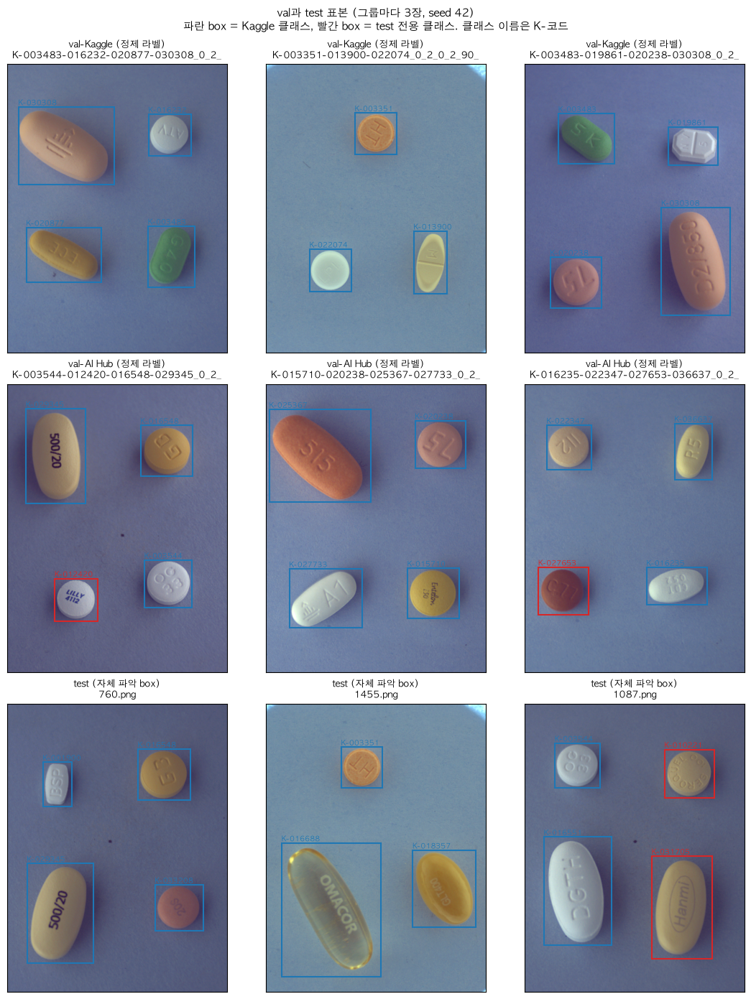

In [ ]:
N_PER_GROUP = 3
val_by_source = {s: [im for im in val_gt['images'] if im['source'] == s] for s in ('kaggle', 'aihub')}
gt_boxes = collections.defaultdict(list)
for ann in val_gt['annotations']:
    gt_boxes[ann['image_id']].append((ann['category_id'], ann['bbox']))
test_boxes = collections.defaultdict(list)
for crop in test_crops:
    test_boxes[crop['test_file']].append((crop['category_id'], crop['bbox']))

samples = []
for title, source in (('val-Kaggle (정제 라벨)', 'kaggle'), ('val-AI Hub (정제 라벨)', 'aihub')):
    for im in rng.choice(val_by_source[source], N_PER_GROUP, replace=False):
        samples.append((title, DATA_DIR / IMAGE_DIRS[source] / im['file_name'], gt_boxes[im['id']], im['file_name']))
for f in rng.choice(test_files, N_PER_GROUP, replace=False):
    samples.append(('test (자체 파악 box)', TEST_IMG_DIR / f, test_boxes[f], f))

fig, axes = plt.subplots(3, N_PER_GROUP, figsize=(N_PER_GROUP * 3.6, 3 * 4.6), layout='constrained')
for ax, (title, path, boxes, name) in zip(axes.flat, samples):
    ax.imshow(Image.open(path).convert('RGB'))
    for c, (x, y, w, h) in boxes:
        color = 'tab:red' if c in TEST_ONLY else 'tab:blue'
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1.5))
        ax.text(x, y - 8, k_code(c), color=color, fontsize=7, ha='left')
    ax.set_title(f'{title}\n{name[:34]}', fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f'val과 test 표본 (그룹마다 {N_PER_GROUP}장, seed {SEED})\n파란 box = Kaggle 클래스, 빨간 box = test 전용 클래스. 클래스 이름은 K-코드', fontsize=11)
save_fig(fig, '1-3_samples')
plt.show()

**인사이트**
- 세 그룹 모두 box가 알약 외곽에 여백 없이 붙어 있다. Kaggle 정제 라벨, AI Hub 정제 라벨, test 자체 파악 box(1차 모델 예측)의 모양이 눈으로는 구별되지 않는다.
- 배경(연보라 바닥), 조명, 알약 배치(2×2 또는 3개)가 세 그룹에서 같다. test 전용 클래스(빨간 box)도 같은 환경에서 찍혔다.

**결론**
- 눈으로 보이는 라벨 스타일 차이는 없다. 출처 간 box 여백 차이는 4-2에서 수치로 확인한다.

## 2. 클래스 분포
- 목적: val이 test의 클래스 분포를 대표하는지, 대표하지 못하는 클래스가 무엇인지 정한다. (가설 1)
    - 2차 val은 AI Hub 몫을 test 빈도 비율로 나누되, 클래스마다 최소 `VAL_CLASS_FLOOR`개, 최대 그 클래스 AI Hub 객체의 `VAL_CLASS_CAP`까지만 넣었다. (`datasets.select_val`)
    - 대회 점수는 클래스별 AP의 평균이므로, 클래스 하나가 몇 개든 비중은 1/74로 같다. 빈도보다 "val에 그 클래스가 믿을 만큼 있는가"가 중요하다.

### 2-1. 대회 클래스 74개의 split별 객체 수
- 클래스마다 train(Kaggle, AI Hub), val(Kaggle, AI Hub), test(자체 파악) 객체 수를 센다. 세 그림 모두 test 수가 많은 순서로 놓고 선형 눈금으로 그린다.
    - 위 그림은 val과 test, 가운데 그림은 train이다.
    - 아래 그림은 train과 val을 한 막대에 쌓은 train+val이다. 아래 칸이 train, 위 칸이 val이다.
    - train은 split이 train인 11,206장 전체로 센다. v1·v4는 이 사진을 모두 쓰고, v2·v3은 일부만 쓴다. (1-1b)
    - x축 이름이 빨간색이면 test 전용 클래스이다.
- 그림 아래 표에 세 그림의 클래스별 수를 그림과 같은 순서로 적는다.
    - 열은 위 그림(test, val-Kaggle, val-AI Hub), 가운데 그림(train-Kaggle, train-AI Hub), 아래 그림(train, val, train+val, val 비율) 순서다.

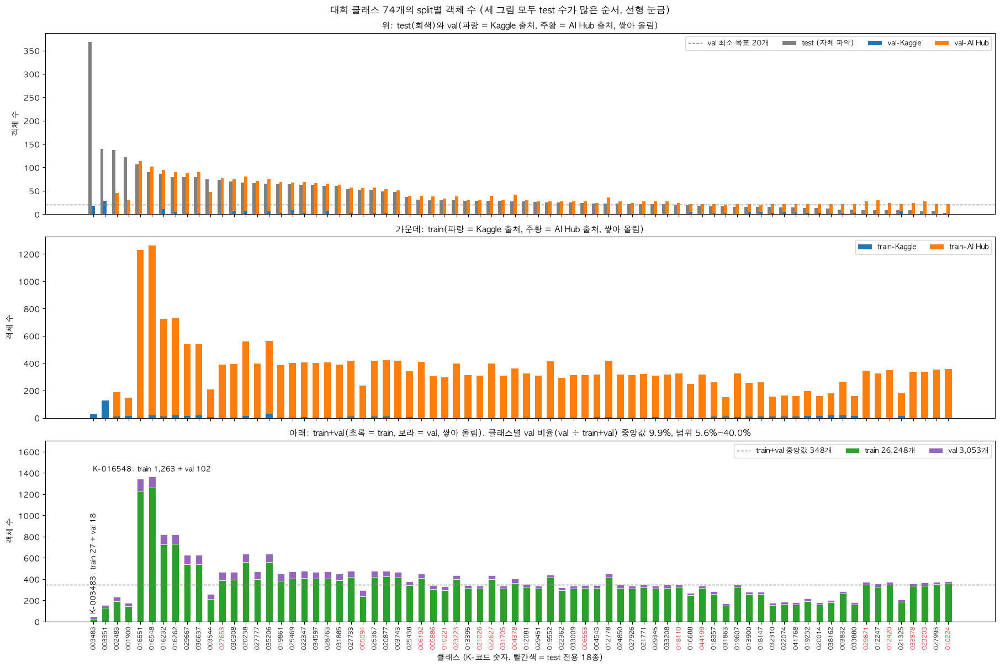

In [ ]:
counts = {key: collections.Counter() for key in ('train-kaggle', 'train-aihub', 'val-kaggle', 'val-aihub')}
for name, im in images.items():
    key = f"{split_of[name]}-{im['source']}"
    for c, _, _ in im['objects']:
        if c in COMPETITION:
            counts[key][c] += 1
counts['test'] = collections.Counter({c: n for c, n in test_counts.items() if c in COMPETITION})
order = sorted(COMPETITION, key=lambda c: (-counts['test'][c], c))
x = np.arange(len(order))
train_n = np.array([counts['train-kaggle'][c] + counts['train-aihub'][c] for c in order])
val_n = np.array([counts['val-kaggle'][c] + counts['val-aihub'][c] for c in order])
trainval_n = train_n + val_n
val_ratio = val_n / trainval_n   # 클래스별 val 비율 = val ÷ (train+val)

fig, (ax_top, ax_mid, ax_bottom) = plt.subplots(3, 1, figsize=(18, 12), sharex=True, layout='constrained')
w = 0.28
ax_top.bar(x - w, [counts['test'][c] for c in order], w, color='gray', label='test (자체 파악)')
ax_top.bar(x, [counts['val-kaggle'][c] for c in order], w, color='tab:blue', label='val-Kaggle')
ax_top.bar(x, [counts['val-aihub'][c] for c in order], w, bottom=[counts['val-kaggle'][c] for c in order], color='tab:orange', label='val-AI Hub')
ax_top.axhline(VAL_CLASS_FLOOR, color='gray', linestyle='--', linewidth=1, label=f'val 최소 목표 {VAL_CLASS_FLOOR}개')
ax_top.set_ylabel('객체 수')
ax_top.set_title('위: test(회색)와 val(파랑 = Kaggle 출처, 주황 = AI Hub 출처, 쌓아 올림)', fontsize=11)
ax_top.legend(ncol=4, fontsize=9)
ax_mid.bar(x, [counts['train-kaggle'][c] for c in order], 0.6, color='tab:blue', label='train-Kaggle')
ax_mid.bar(x, [counts['train-aihub'][c] for c in order], 0.6, bottom=[counts['train-kaggle'][c] for c in order], color='tab:orange', label='train-AI Hub')
ax_mid.set_ylabel('객체 수')
ax_mid.set_title('가운데: train(파랑 = Kaggle 출처, 주황 = AI Hub 출처, 쌓아 올림)', fontsize=11)
ax_mid.legend(ncol=2, fontsize=9)
# 위 두 그림의 파랑·주황은 출처라서 train·val은 초록·보라로 칠한다. 흰 테두리로 두 칸을 나눈다
ax_bottom.bar(x, train_n, 0.6, color='tab:green', edgecolor='white', linewidth=0.5, label=f'train {train_n.sum():,}개')
ax_bottom.bar(x, val_n, 0.6, bottom=train_n, color='tab:purple', edgecolor='white', linewidth=0.5, label=f'val {val_n.sum():,}개')
ax_bottom.axhline(np.median(trainval_n), color='gray', linestyle='--', linewidth=1, label=f'train+val 중앙값 {np.median(trainval_n):.0f}개')
# 가장 많은 클래스와 가장 적은 클래스에만 train + val 수를 적는다. 가장 적은 막대의 글자는 옆 막대와 겹치지 않게 세로로 쓴다
for i, rotation in ((trainval_n.argmax(), 0), (trainval_n.argmin(), 90)):
    ax_bottom.annotate(f'{k_code(order[i])}: train {train_n[i]:,} + val {val_n[i]}', (x[i], trainval_n[i]), xytext=(0, 4), textcoords='offset points',
                       ha='center', va='bottom', rotation=rotation, fontsize=9)
ax_bottom.set_ylim(0, trainval_n.max() * 1.25)
ax_bottom.set_ylabel('객체 수')
ax_bottom.set_title(f'아래: train+val(초록 = train, 보라 = val, 쌓아 올림). 클래스별 val 비율(val ÷ train+val) 중앙값 {np.median(val_ratio):.1%}, '
                    f'범위 {val_ratio.min():.1%}~{val_ratio.max():.1%}', fontsize=11)
ax_bottom.legend(ncol=3, fontsize=9)
ax_bottom.set_xticks(x, [k_code(c)[2:] for c in order], rotation=90, fontsize=8)
for tick, c in zip(ax_bottom.get_xticklabels(), order):
    tick.set_color('tab:red' if c in TEST_ONLY else 'black')
ax_bottom.set_xlabel('클래스 (K-코드 숫자. 빨간색 = test 전용 18종)')
fig.suptitle('대회 클래스 74개의 split별 객체 수 (세 그림 모두 test 수가 많은 순서, 선형 눈금)')
save_fig(fig, '2-1_class_counts')
plt.show()

In [ ]:
# 위 그림의 클래스별 수를 그림과 같은 순서로 적는다. 열은 위 그림, 가운데 그림, 아래 그림 순서다
COUNT_KEYS = ['test', 'val-kaggle', 'val-aihub', 'train-kaggle', 'train-aihub']
count_rows = [[rank, k_code(c), 'test 전용' if c in TEST_ONLY else 'Kaggle', *[f'{counts[key][c]:,}' for key in COUNT_KEYS],
               f'{tr:,}', f'{va:,}', f'{tv:,}', f'{ratio:.1%}']
              for rank, (c, tr, va, tv, ratio) in enumerate(zip(order, train_n, val_n, trainval_n, val_ratio), start=1)]
count_rows.append(['**합계**', '', '', *[f'**{sum(counts[key][c] for c in order):,}**' for key in COUNT_KEYS],
                   f'**{train_n.sum():,}**', f'**{val_n.sum():,}**', f'**{trainval_n.sum():,}**', f'**{val_n.sum() / trainval_n.sum():.1%}**'])
show_table(['그림 순서', '클래스', '그룹', 'test (자체 파악)', 'val-Kaggle', 'val-AI Hub', 'train-Kaggle', 'train-AI Hub',
            'train', 'val', 'train+val', 'val 비율 (val ÷ train+val)'], count_rows)

| 그림 순서 | 클래스 | 그룹 | test (자체 파악) | val-Kaggle | val-AI Hub | train-Kaggle | train-AI Hub | train | val | train+val | val 비율 (val ÷ train+val) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | K-003483 | Kaggle | 369 | 18 | 0 | 27 | 0 | 27 | 18 | 45 | 40.0% |
| 2 | K-003351 | Kaggle | 139 | 29 | 0 | 128 | 0 | 128 | 29 | 157 | 18.5% |
| 3 | K-002483 | Kaggle | 137 | 0 | 45 | 9 | 180 | 189 | 45 | 234 | 19.2% |
| 4 | K-001900 | Kaggle | 122 | 0 | 30 | 15 | 132 | 147 | 30 | 177 | 16.9% |
| 5 | K-016551 | Kaggle | 107 | 0 | 114 | 3 | 1,227 | 1,230 | 114 | 1,344 | 8.5% |
| 6 | K-016548 | Kaggle | 90 | 0 | 102 | 18 | 1,245 | 1,263 | 102 | 1,365 | 7.5% |
| 7 | K-016232 | Kaggle | 86 | 11 | 84 | 10 | 717 | 727 | 95 | 822 | 11.6% |
| 8 | K-016262 | Kaggle | 79 | 5 | 85 | 18 | 714 | 732 | 90 | 822 | 10.9% |
| 9 | K-029667 | Kaggle | 79 | 2 | 86 | 16 | 525 | 541 | 88 | 629 | 14.0% |
| 10 | K-036637 | Kaggle | 79 | 1 | 89 | 18 | 522 | 540 | 90 | 630 | 14.3% |
| 11 | K-003544 | Kaggle | 75 | 0 | 48 | 6 | 204 | 210 | 48 | 258 | 18.6% |
| 12 | K-027653 | test 전용 | 73 | 0 | 77 | 0 | 390 | 390 | 77 | 467 | 16.5% |
| 13 | K-030308 | Kaggle | 70 | 6 | 69 | 3 | 390 | 393 | 75 | 468 | 16.0% |
| 14 | K-020238 | Kaggle | 67 | 7 | 74 | 13 | 546 | 559 | 81 | 640 | 12.7% |
| 15 | K-027777 | Kaggle | 66 | 0 | 71 | 3 | 396 | 399 | 71 | 470 | 15.1% |
| 16 | K-035206 | Kaggle | 65 | 6 | 69 | 31 | 531 | 562 | 75 | 637 | 11.8% |
| 17 | K-019861 | Kaggle | 64 | 3 | 66 | 3 | 381 | 384 | 69 | 453 | 15.2% |
| 18 | K-025469 | Kaggle | 64 | 9 | 59 | 3 | 399 | 402 | 68 | 470 | 14.5% |
| 19 | K-022347 | Kaggle | 63 | 3 | 66 | 6 | 402 | 408 | 69 | 477 | 14.5% |
| 20 | K-034597 | Kaggle | 63 | 0 | 66 | 3 | 399 | 402 | 66 | 468 | 14.1% |
| 21 | K-028763 | Kaggle | 61 | 6 | 59 | 3 | 402 | 405 | 65 | 470 | 13.8% |
| 22 | K-031885 | Kaggle | 60 | 0 | 63 | 3 | 387 | 390 | 63 | 453 | 13.9% |
| 23 | K-027733 | Kaggle | 53 | 3 | 54 | 9 | 411 | 420 | 57 | 477 | 11.9% |
| 24 | K-005094 | test 전용 | 52 | 0 | 56 | 0 | 237 | 237 | 56 | 293 | 19.1% |
| 25 | K-025367 | Kaggle | 52 | 3 | 54 | 9 | 411 | 420 | 57 | 477 | 11.9% |
| 26 | K-020877 | Kaggle | 49 | 3 | 50 | 9 | 414 | 423 | 53 | 476 | 11.1% |
| 27 | K-003743 | Kaggle | 48 | 0 | 51 | 3 | 414 | 417 | 51 | 468 | 10.9% |
| 28 | K-025438 | Kaggle | 37 | 0 | 39 | 6 | 336 | 342 | 39 | 381 | 10.2% |
| 29 | K-006192 | test 전용 | 31 | 0 | 39 | 0 | 410 | 410 | 39 | 449 | 8.7% |
| 30 | K-005886 | test 전용 | 30 | 0 | 38 | 0 | 306 | 306 | 38 | 344 | 11.0% |
| 31 | K-010221 | test 전용 | 30 | 0 | 33 | 0 | 297 | 297 | 33 | 330 | 10.0% |
| 32 | K-023223 | test 전용 | 30 | 0 | 38 | 0 | 399 | 399 | 38 | 437 | 8.7% |
| 33 | K-013395 | Kaggle | 28 | 0 | 30 | 3 | 311 | 314 | 30 | 344 | 8.7% |
| 34 | K-021026 | test 전용 | 28 | 0 | 30 | 0 | 309 | 309 | 30 | 339 | 8.8% |
| 35 | K-022627 | test 전용 | 28 | 0 | 39 | 0 | 399 | 399 | 39 | 438 | 8.9% |
| 36 | K-031705 | test 전용 | 28 | 0 | 30 | 0 | 309 | 309 | 30 | 339 | 8.8% |
| 37 | K-004378 | test 전용 | 27 | 0 | 42 | 0 | 363 | 363 | 42 | 405 | 10.4% |
| 38 | K-012081 | Kaggle | 27 | 0 | 30 | 3 | 321 | 324 | 30 | 354 | 8.5% |
| 39 | K-029451 | Kaggle | 26 | 0 | 27 | 3 | 306 | 309 | 27 | 336 | 8.0% |
| 40 | K-019552 | Kaggle | 25 | 0 | 27 | 3 | 411 | 414 | 27 | 441 | 6.1% |
| 41 | K-022362 | Kaggle | 25 | 0 | 27 | 3 | 291 | 294 | 27 | 321 | 8.4% |
| 42 | K-033009 | Kaggle | 25 | 0 | 27 | 3 | 309 | 312 | 27 | 339 | 8.0% |
| 43 | K-006563 | test 전용 | 24 | 0 | 27 | 0 | 315 | 315 | 27 | 342 | 7.9% |
| 44 | K-004543 | Kaggle | 23 | 0 | 24 | 6 | 312 | 318 | 24 | 342 | 7.0% |
| 45 | K-012778 | Kaggle | 23 | 0 | 36 | 6 | 411 | 417 | 36 | 453 | 7.9% |
| 46 | K-024850 | Kaggle | 23 | 0 | 27 | 3 | 315 | 318 | 27 | 345 | 7.8% |
| 47 | K-027926 | Kaggle | 22 | 0 | 24 | 3 | 309 | 312 | 24 | 336 | 7.1% |
| 48 | K-021771 | Kaggle | 21 | 0 | 27 | 3 | 318 | 321 | 27 | 348 | 7.8% |
| 49 | K-029345 | Kaggle | 21 | 0 | 27 | 6 | 303 | 309 | 27 | 336 | 8.0% |
| 50 | K-033208 | Kaggle | 21 | 0 | 27 | 3 | 315 | 318 | 27 | 345 | 7.8% |
| 51 | K-018110 | test 전용 | 20 | 0 | 24 | 0 | 324 | 324 | 24 | 348 | 6.9% |
| 52 | K-016688 | Kaggle | 19 | 4 | 18 | 4 | 243 | 247 | 22 | 269 | 8.2% |
| 53 | K-044199 | test 전용 | 18 | 0 | 21 | 0 | 318 | 318 | 21 | 339 | 6.2% |
| 54 | K-018357 | Kaggle | 17 | 1 | 21 | 12 | 249 | 261 | 22 | 283 | 7.8% |
| 55 | K-031863 | Kaggle | 17 | 2 | 18 | 10 | 141 | 151 | 20 | 171 | 11.7% |
| 56 | K-019607 | Kaggle | 16 | 0 | 21 | 6 | 321 | 327 | 21 | 348 | 6.0% |
| 57 | K-013900 | Kaggle | 15 | 4 | 18 | 11 | 246 | 257 | 22 | 279 | 7.9% |
| 58 | K-018147 | Kaggle | 15 | 5 | 15 | 10 | 249 | 259 | 20 | 279 | 7.2% |
| 59 | K-032310 | Kaggle | 15 | 3 | 18 | 12 | 144 | 156 | 21 | 177 | 11.9% |
| 60 | K-022074 | Kaggle | 14 | 4 | 18 | 12 | 153 | 165 | 22 | 187 | 11.8% |
| 61 | K-041768 | Kaggle | 14 | 4 | 17 | 12 | 147 | 159 | 21 | 180 | 11.7% |
| 62 | K-019232 | Kaggle | 13 | 3 | 18 | 14 | 180 | 194 | 21 | 215 | 9.8% |
| 63 | K-020014 | Kaggle | 13 | 3 | 18 | 14 | 147 | 161 | 21 | 182 | 11.5% |
| 64 | K-038162 | Kaggle | 12 | 1 | 20 | 17 | 162 | 179 | 21 | 200 | 10.5% |
| 65 | K-003832 | Kaggle | 10 | 1 | 20 | 19 | 246 | 265 | 21 | 286 | 7.3% |
| 66 | K-033880 | Kaggle | 10 | 3 | 18 | 14 | 147 | 161 | 21 | 182 | 11.5% |
| 67 | K-029871 | test 전용 | 9 | 0 | 27 | 0 | 345 | 345 | 27 | 372 | 7.3% |
| 68 | K-012247 | Kaggle | 8 | 0 | 30 | 3 | 324 | 327 | 30 | 357 | 8.4% |
| 69 | K-012420 | test 전용 | 8 | 0 | 24 | 0 | 348 | 348 | 24 | 372 | 6.5% |
| 70 | K-021325 | Kaggle | 8 | 6 | 15 | 16 | 168 | 184 | 21 | 205 | 10.2% |
| 71 | K-033878 | test 전용 | 8 | 0 | 24 | 0 | 336 | 336 | 24 | 360 | 6.7% |
| 72 | K-023203 | test 전용 | 6 | 0 | 27 | 0 | 339 | 339 | 27 | 366 | 7.4% |
| 73 | K-027993 | Kaggle | 6 | 0 | 21 | 3 | 351 | 354 | 21 | 375 | 5.6% |
| 74 | K-010224 | test 전용 | 3 | 0 | 21 | 0 | 357 | 357 | 21 | 378 | 5.6% |
| **합계** |  |  | **3,229** | **159** | **2,894** | **612** | **25,636** | **26,248** | **3,053** | **29,301** | **10.4%** |

**인사이트**
- val 객체 수는 클래스당 18~114개(중앙값 30개)이다. 74종 중 73종이 최소 목표 20개 이상이고, 유일한 예외는 K-003483(18개)이다.
    - K-003483과 K-003351은 허용된 AI Hub zip에 없는 클래스라서(01 1-6) train·val 모두 Kaggle 사진에서만 나오고 val-AI Hub가 0이다.
    - val의 Kaggle 사진 47장 안에 K-003483은 18개, K-003351은 29개가 있다. 47장은 두 클래스의 객체 수가 아니라 val-Kaggle 사진 전체 수다.
- test 최빈 클래스 K-003483은 test 369개(11.4%)인데 train 27개, val 18개(합 45개, 모두 Kaggle 사진)뿐이다. 그래도 이 클래스의 val AP는 YOLO26s와 RT-DETR이 1.000이고, F-RCNN만 0.946으로 0.95 아래다. (5-3b)
- train은 AI Hub가 클래스당 132~1,245개(중앙값 322개)를 채운다. Kaggle train은 클래스당 3~31개이고, AI Hub에 없는 K-003351만 128개다.
    - 선형 눈금이라 가운데 그림의 Kaggle train(파랑)은 K-003351과 K-003483 말고는 거의 보이지 않는다. 정확한 수는 표의 train-Kaggle 열에서 본다.
- test 전용 18종(빨간 이름)은 train·val 모두 AI Hub뿐이다.
- train+val은 클래스당 45~1,365개(중앙값 348개)다. 가장 많은 K-016548(train 1,263 + val 102)이 가장 적은 K-003483(train 27 + val 18)의 약 30배다.
- test 수 상위 4종(K-003483, K-003351, K-002483, K-001900)은 train+val이 45~234개로 모두 중앙값 아래다.
    - 그다음 test 5~10위 6종은 train+val 629~1,365개로 모두 train+val 상위 8종에 든다. test 수와 학습량의 순서가 맨 앞에서 뒤집혀 있다.
- test 전용 18종은 train+val이 293~467개로 중앙값 근처에 모여 있다. 293개보다 적은 19종은 모두 Kaggle 클래스다.
- 클래스별 val 비율(val ÷ train+val)은 중앙값 9.9%, 범위 5.6~40.0%다.
    - 40.0%인 K-003483과 18.5%인 K-003351은 AI Hub 사진이 없어 Kaggle 사진만으로 train과 val을 나눈 클래스다.

**결론**
- 클래스별 val 객체 수는 설계(`select_val`: 최소 20개, AI Hub 객체의 20% 상한)대로 들어가 있다. 빈도 부족으로 val AP를 재지 못하는 클래스는 없다.
- K-003483과 K-003351은 val 근거가 val-Kaggle 사진뿐이다. 두 클래스의 val AP는 객체 18개(K-003483), 29개(K-003351)에서 나온 값으로 읽는다.
- test 전용 18종은 학습량이 부족한 클래스가 아니다. 6-4에서 test 전용 18종 AP(0.665)가 Kaggle 56종(0.599)보다 낮지 않은 것과 맞는다.
- test에 가장 많이 나오는 4종은 학습량이 적은 쪽이다. 대회 점수는 클래스별 AP의 평균이라 test 수가 점수 비중을 바꾸지는 않는다.
    - 이 중 K-002483은 5-3a에서 val AP가 가장 낮은 클래스이므로, 3차에서 모니터링 클래스로 계속 본다.

### 2-2. val 비율 vs test 비율
- 클래스별 val 객체 비율(대회 클래스 val 객체 중 그 클래스의 비율)과 test 비율을 log-log 산점도로 비교한다.
    - 스피어만 상관(순위 상관, 1이면 순서가 완전히 같음)을 제목에 적는다.
    - val 수가 상한(AI Hub 객체의 20%)에 걸린 클래스는 빨간 테두리로 표시하고, val/test 비율이 1/3 미만이거나 3배 초과인 클래스에 이름을 적는다.

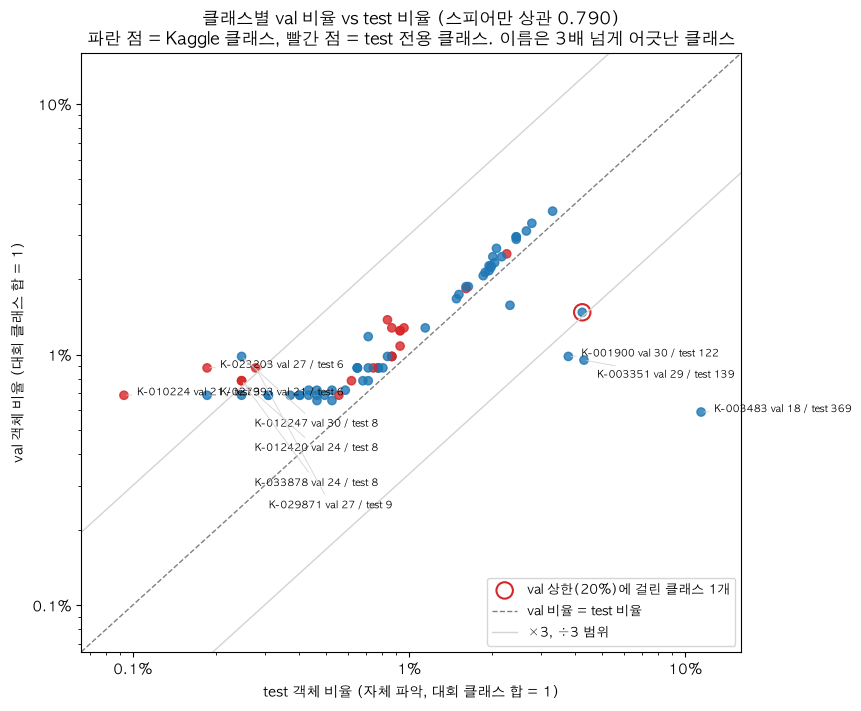

In [ ]:
RATIO_LIMIT = 3  # 이 배수를 넘게 어긋난 클래스에 이름을 적는다
val_total = sum(counts['val-kaggle'][c] + counts['val-aihub'][c] for c in order)
test_total = sum(counts['test'][c] for c in order)
aihub_total = {c: counts['train-aihub'][c] + counts['val-aihub'][c] for c in order}
val_share = np.array([(counts['val-kaggle'][c] + counts['val-aihub'][c]) / val_total for c in order])
test_share = np.array([counts['test'][c] / test_total for c in order])
capped = np.array([aihub_total[c] > 0 and counts['val-aihub'][c] >= int(aihub_total[c] * VAL_CLASS_CAP) for c in order])


def spearman(a, b):
    """스피어만 순위 상관: 두 값의 순위에 대한 피어슨 상관."""
    rank = lambda v: np.argsort(np.argsort(v))
    return np.corrcoef(rank(a), rank(b))[0, 1]


fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
colors = ['tab:red' if c in TEST_ONLY else 'tab:blue' for c in order]
ax.scatter(test_share, val_share, c=colors, s=36, alpha=0.8)
ax.scatter(test_share[capped], val_share[capped], s=140, facecolors='none', edgecolors='tab:red', linewidths=1.5, label=f'val 상한({VAL_CLASS_CAP:.0%})에 걸린 클래스 {capped.sum()}개')
lims = [min(test_share.min(), val_share.min()) * 0.7, max(test_share.max(), val_share.max()) * 1.4]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1, label='val 비율 = test 비율')
ax.plot(lims, [l * RATIO_LIMIT for l in lims], color='lightgray', linewidth=1)
ax.plot(lims, [l / RATIO_LIMIT for l in lims], color='lightgray', linewidth=1, label=f'×{RATIO_LIMIT}, ÷{RATIO_LIMIT} 범위')
placed = []   # 이미 적은 이름의 위치 (log 좌표). 겹치면 아래로 내려 적는다
for c, ts, vs in sorted(zip(order, test_share, val_share), key=lambda t: (t[1], -t[2])):
    if vs / ts > RATIO_LIMIT or ts / vs > RATIO_LIMIT:
        lx, ly = np.log10(ts), np.log10(vs)
        while any(abs(lx - px) < 0.22 and abs(ly - py) < 0.07 for px, py in placed):
            ly -= 0.07
        placed.append((lx, ly))
        ax.annotate(f'{k_code(c)} val {counts["val-kaggle"][c] + counts["val-aihub"][c]} / test {counts["test"][c]}', (ts, vs), xytext=(10 ** lx * 1.12, 10 ** ly),
                    fontsize=7, arrowprops=dict(arrowstyle='-', color='lightgray', linewidth=0.6))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(lims)
ax.set_ylim(lims)
for axis in (ax.xaxis, ax.yaxis):   # log 축 눈금을 퍼센트로 적는다 (수식 폰트의 마이너스 기호 깨짐도 피한다)
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:.1%}' if v < 0.01 else f'{v:.0%}'))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xlabel('test 객체 비율 (자체 파악, 대회 클래스 합 = 1)')
ax.set_ylabel('val 객체 비율 (대회 클래스 합 = 1)')
ax.set_title(f'클래스별 val 비율 vs test 비율 (스피어만 상관 {spearman(test_share, val_share):.3f})\n파란 점 = Kaggle 클래스, 빨간 점 = test 전용 클래스. 이름은 {RATIO_LIMIT}배 넘게 어긋난 클래스')
ax.legend(fontsize=9, loc='lower right')
save_fig(fig, '2-2_val_vs_test_share')
plt.show()

**인사이트**
- val 비율과 test 비율의 순위 상관은 0.790이다. 대체로 비슷하지만 양 끝이 어긋난다.
- val이 모자란 쪽은 3종이다: K-003483(val 18 / test 369, 비 0.05), K-003351(29 / 139, 0.22), K-001900(30 / 122, 0.26).
    - K-003483·K-003351은 AI Hub에 없어 늘릴 수 없고, K-001900은 AI Hub 객체의 20% 상한에 걸렸다(빨간 테두리).
- val이 넘치는 쪽 7종(K-010224, K-023203, K-012247, K-027993, K-033878, K-029871, K-012420)은 test에 3~9개뿐인 희소 클래스다. 최소 목표 20개 때문에 val 비율이 3~7배 높다.

**결론**
- val의 클래스 비율은 test와 다르지만, 이는 "희소 클래스도 20개 이상 넣는다"는 설계의 결과다. 대회 점수는 클래스별 AP의 단순 평균이라 비율 차이 자체는 점수를 바꾸지 않는다.
- 가설 1의 "분포가 다르다"는 사실이지만, 5-1·5-2에서 val-Kaggle 47장(대회 측 라벨, test와 같은 장면 28장 포함)도 0.99라서 분포 차이로 0.38 손실을 설명할 수 없다. val 구성은 바꾸지 않는다.

### 2-2b. 비율이 어긋난 클래스의 IoU 기준별 val AP
- 2-2에서 이름을 적은 10종(val 비율이 test 비율의 1/3 미만인 3종, 3배 초과인 7종)을 2차 모델이 val에서 얼마나 맞히는지 본다.
- 0절에서 추론한 로컬 가중치 3개(v3 e10)의 val 예측을 `evaluate_val`과 같은 규칙(무시 규칙, 대회 클래스 74개)으로 채점하고, 10종의 IoU 기준 0.75, 0.80, 0.85, 0.90, 0.95별 AP를 꺾은선으로 그린다.
    - 다섯 기준의 평균이 대회 점수 방식의 클래스별 AP@[0.75:0.95]이고, 5-3a의 클래스별 AP와 같은 값이다.
    - 0.90·0.95에서만 떨어지면 box가 조금 어긋난 것이고, 0.75부터 떨어지면 놓침이나 클래스 오류가 있다는 뜻이다. (5-2)
- 모델마다 그림 한 줄이고, x축은 val÷test 비율이 작은 순서다. 회색 점선 왼쪽이 val 부족, 오른쪽이 val 과잉이다.

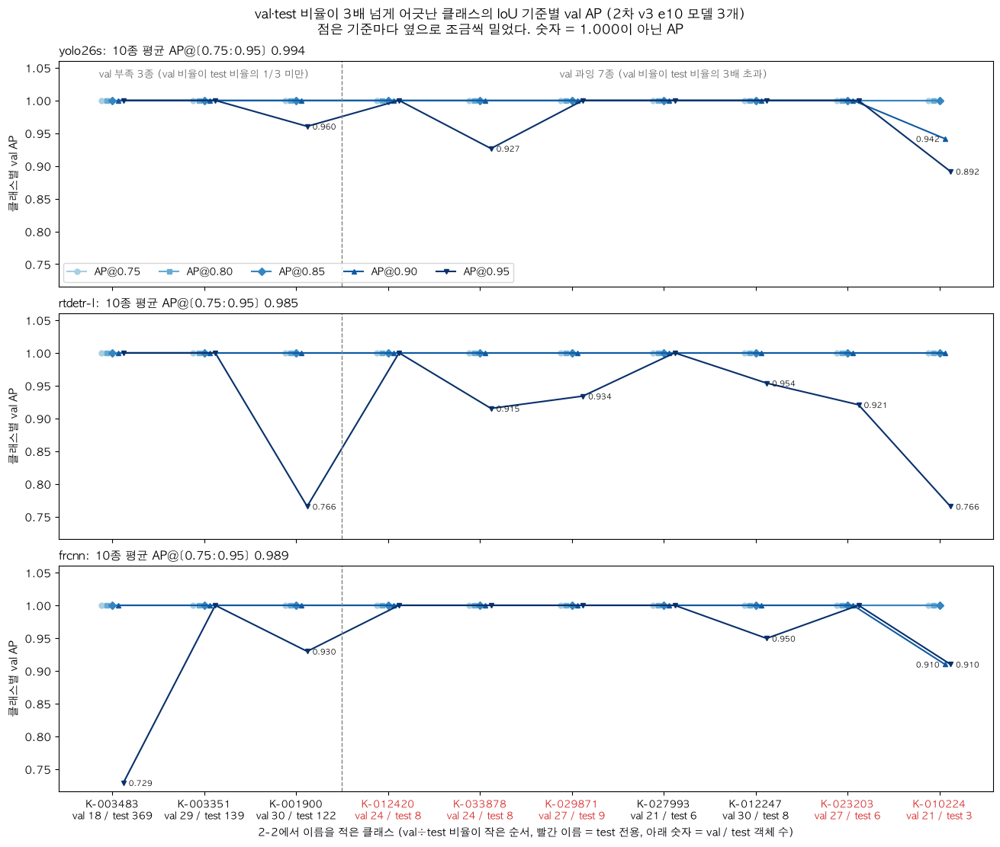

In [ ]:
# 2-2에서 이름을 적은 클래스: val 비율이 test 비율의 1/3 미만이거나 3배 초과. val÷test 비율이 작은 순서(val 부족 → val 과잉)로 놓는다
imbalance = {c: vs / ts for c, ts, vs in zip(order, test_share, val_share) if vs / ts > RATIO_LIMIT or ts / vs > RATIO_LIMIT}
named = sorted(imbalance, key=imbalance.get)
n_short = sum(imbalance[c] < 1 for c in named)
x = np.arange(len(named))
threshold_colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(IOU_THRESHOLDS)))   # IoU 기준이 엄격할수록 진한 파랑
threshold_markers = ['o', 's', 'D', '^', 'v']
DODGE = 0.06   # 같은 값이면 점이 겹치므로 IoU 기준마다 옆으로 조금씩 민다

ap_of = {}   # 모델 → AP[IoU 기준, 클래스]
fig, axes = plt.subplots(len(val_predictions), 1, figsize=(13, 11), sharex=True, sharey=True, layout='constrained')
for ax, (name, preds) in zip(axes, val_predictions.items()):
    # evaluate_val과 같은 무시 규칙과 대회 클래스 74개로 채점한 뒤 10종의 열만 꺼낸다. 클래스별 AP는 다른 클래스와 따로 계산된다
    precision, category_ids = coco_precision(val_gt, drop_ignored(preds, val_gt), category_ids=COMPETITION)
    columns = [category_ids.index(c) for c in named]
    ap = np.array([[values[values > -1].mean() for values in precision[t][:, columns].T] for t in range(len(IOU_THRESHOLDS))])   # [IoU 기준, 클래스]
    for t, (iou, color, marker) in enumerate(zip(IOU_THRESHOLDS, threshold_colors, threshold_markers)):
        ax.plot(x + (t - 2) * DODGE, ap[t], color=color, marker=marker, markersize=5, linewidth=1.5, label=f'AP@{iou:.2f}')
    # 1.000이 아닌 값만 숫자로 적는다 (1.000은 선이 맨 위에 겹친다). 0.95는 점 오른쪽, 나머지 기준은 왼쪽에 적어 겹치지 않게 한다
    for t in range(len(IOU_THRESHOLDS)):
        right = t == len(IOU_THRESHOLDS) - 1
        for i in np.where(ap[t] < 0.9995)[0]:
            ax.annotate(f'{ap[t, i]:.3f}', (x[i] + (t - 2) * DODGE, ap[t, i]), xytext=(5 if right else -5, -3), textcoords='offset points',
                        ha='left' if right else 'right', fontsize=7.5)
    ax.axvline(n_short - 0.5, color='gray', linestyle='--', linewidth=1)
    ap_of[name] = ap
    ax.set_title(f'{name}: 10종 평균 AP@[0.75:0.95] {ap.mean():.3f}', fontsize=11, loc='left')
    ax.set_ylabel('클래스별 val AP')
axes[0].text(n_short / 2 - 0.5, 1.035, f'val 부족 {n_short}종 (val 비율이 test 비율의 1/{RATIO_LIMIT} 미만)', ha='center', fontsize=9, color='dimgray')
axes[0].text((n_short + len(named)) / 2 - 0.5, 1.035, f'val 과잉 {len(named) - n_short}종 (val 비율이 test 비율의 {RATIO_LIMIT}배 초과)', ha='center', fontsize=9, color='dimgray')
axes[0].set_ylim(top=1.06)
axes[0].legend(ncol=5, fontsize=9, loc='lower left')
val_of = lambda c: counts['val-kaggle'][c] + counts['val-aihub'][c]
axes[-1].set_xticks(x, [f'{k_code(c)}\nval {val_of(c)} / test {counts["test"][c]}' for c in named], fontsize=9)
for tick, c in zip(axes[-1].get_xticklabels(), named):
    tick.set_color('tab:red' if c in TEST_ONLY else 'black')
axes[-1].set_xlabel('2-2에서 이름을 적은 클래스 (val÷test 비율이 작은 순서, 빨간 이름 = test 전용, 아래 숫자 = val / test 객체 수)')
fig.suptitle('val·test 비율이 3배 넘게 어긋난 클래스의 IoU 기준별 val AP (2차 v3 e10 모델 3개)\n'
             '점은 기준마다 옆으로 조금씩 밀었다. 숫자 = 1.000이 아닌 AP')
save_fig(fig, '2-2b_imbalanced_class_ap_by_iou')
plt.show()

**인사이트**
- 10종 모두 IoU 0.75, 0.80, 0.85에서 세 모델의 AP가 1.000이다. 비율이 어긋난 클래스도 val에서 놓침이나 클래스 오류가 없다.
- AP@0.90이 1.000 아래인 경우는 K-010224뿐이다. (YOLO26s 0.942, F-RCNN 0.910)
- 나머지 손실은 모두 AP@0.95에서 나온다.
    - YOLO26s는 3종(K-001900 0.960, K-033878 0.927, K-010224 0.892)이 1.000 아래다.
    - RT-DETR-l은 6종이 0.766~0.954다.
    - F-RCNN은 4종(K-003483 0.729, K-001900 0.930, K-012247 0.950, K-010224 0.910)이 1.000 아래다.
- val 부족 3종 중 K-003351은 세 모델 모두 다섯 기준에서 1.000이다. K-003483은 F-RCNN의 AP@0.95(0.729)만 떨어진다.
- 세 모델 모두 AP@0.95가 떨어지는 클래스는 K-001900(val 부족)과 K-010224(val 과잉, test 3개)다.
- 10종 평균 AP@[0.75:0.95]는 YOLO26s 0.994, RT-DETR-l 0.985, F-RCNN 0.989다. 74종 전체 val 점수(5-1의 0.990, 0.987, 0.995)와 0.006 안에서 같다.

**결론**
- val·test 비율이 어긋난 클래스도 val에서는 검출과 분류가 완벽하고, 손실은 IoU 0.90·0.95의 box 정밀도뿐이다. 비율 불균형이 val AP를 떨어뜨리지 않으므로 val 구성은 바꾸지 않는다. (2-2 결론 유지)
- 세 모델 모두 AP@0.95가 떨어지는 K-001900과 K-010224는, 3차 실험에서 클래스별 AP@0.95를 볼 때 5-3b의 9종과 함께 확인한다.

### 2-3. 클래스별 val 근거의 출처
- 대회 클래스 74개를 "val-Kaggle 47장에 있는 클래스"와 "val-AI Hub에만 있는 클래스"로 나누고, 그룹(Kaggle 56종, test 전용 18종)별로 센다.
    - val의 `kaggle` 점수(47장)는 대회 측 라벨로 채점한 값이라 test와 가장 가깝다. 나머지 클래스의 val AP는 우리가 정제한 AI Hub 라벨만 근거이다.

In [ ]:
in_kaggle_val = {c for c in order if counts['val-kaggle'][c] > 0}
in_aihub_val = {c for c in order if counts['val-aihub'][c] > 0}
rows = []
for group_name, group in (('Kaggle 클래스 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)):
    both = group & in_kaggle_val & in_aihub_val
    only_kaggle = group & in_kaggle_val - in_aihub_val
    only_aihub = group & in_aihub_val - in_kaggle_val
    none = group - in_kaggle_val - in_aihub_val
    rows.append([group_name, len(both), len(only_kaggle), len(only_aihub), len(none),
                 f"{sum(counts['val-kaggle'][c] for c in group):,}", f"{sum(counts['val-aihub'][c] for c in group):,}", f"{sum(counts['test'][c] for c in group):,}"])
rows.append(['**합계 74종**', *[f'**{sum(int(r[i]) for r in rows)}**' for i in range(1, 5)],
             f"**{sum(counts['val-kaggle'].values()):,}**", f"**{sum(counts['val-aihub'].values()):,}**", f"**{test_total:,}**"])
show_table(['그룹', 'val-Kaggle과 val-AI Hub 모두 있음', 'val-Kaggle에만', 'val-AI Hub에만', 'val에 없음', 'val-Kaggle 객체', 'val-AI Hub 객체', 'test 객체 (자체 파악)'], rows)

| 그룹 | val-Kaggle과 val-AI Hub 모두 있음 | val-Kaggle에만 | val-AI Hub에만 | val에 없음 | val-Kaggle 객체 | val-AI Hub 객체 | test 객체 (자체 파악) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle 클래스 56종 | 28 | 2 | 26 | 0 | 159 | 2,277 | 2,776 |
| test 전용 18종 | 0 | 0 | 18 | 0 | 0 | 617 | 453 |
| **합계 74종** | **28** | **2** | **44** | **0** | **159** | **2,894** | **3,229** |

**인사이트**
- 74종 중 44종(59%)은 val 근거가 AI Hub 정제 라벨뿐이다. Kaggle 클래스 26종 + test 전용 18종이다.
- 28종은 val-Kaggle과 val-AI Hub에 모두 있고, 2종(K-003351, K-003483)은 val-Kaggle에만 있다.
- val-Kaggle 객체는 159개로 val 대회 클래스 객체의 5%다. `kaggle` 점수는 30종 159객체로 잰 값이다.

**결론**
- val 점수의 95%는 우리가 만든 라벨 체계 안에서의 점수다. 대회 측 라벨 기준 점수(`kaggle`)는 30종에서만 측정되고 표본이 작아 ±0.01 차이는 의미가 없다.
- 3차 이후에도 `val`, `kaggle`, `test_only` 세 점수를 함께 보고하고, 모델 선택은 `val`로 하되 Kaggle 점수와의 차이는 6절의 상한으로 해석한다.

## 3. category_id 매핑
- 목적: AI Hub 라벨의 클래스를 `drug_N`(K-코드)으로 읽는 지금 방식(`data.py`)을 계속 믿을지 정한다. (가설 2)
    - 대회 측은 `category_id`를 "JSON 첫 이미지의 `dl_idx`"로 매겼다고 적었다. (DATA.md 데이터 가공 관련 참고사항)
    - 번호가 틀리면 에러 없이 그 클래스 AP만 0이 된다. test 전용 18종은 Kaggle 라벨이 없어 번호를 대회 데이터로 확인할 수 없다.

### 3-1. dl_idx, drug_N, Kaggle category_id 규칙
- AI Hub 원본 JSON에서 클래스(K-코드 폴더)마다 하나를 읽어 `dl_idx`와 `drug_N`의 관계를 세고, Kaggle 원본 JSON에서는 `category_id`와 `dl_idx`, `drug_N`의 관계를 센다.
    - 규칙은 "같음", "K-코드 − 1", "그 밖"으로 나눈다. 대회 클래스만 센다.

In [ ]:
def first_json_per_class(ann_dir):
    """annotation 폴더에서 K-코드 폴더마다 첫 JSON 하나씩 읽어 {category_id: (dl_idx, drug_N 번호, category_id 값)}을 만든다."""
    found = {}
    for folder in sorted(ann_dir.glob('*_json/K-*')):
        digits = folder.name.removeprefix('K-')
        if not digits.isdigit():   # AI Hub 원본의 "K-023319-오류" 같은 폴더는 뺀다 (01 2-4)
            continue
        code_ = int(digits)
        if code_ in found or code_ not in COMPETITION:
            continue
        for path in sorted(folder.glob('*.json')):
            try:
                data = json.loads(path.read_text(encoding='utf-8-sig'))
            except ValueError:
                continue
            image = data['images'][0]
            found[code_] = (int(image['dl_idx']), int(image['drug_N'].removeprefix('K-')), data['annotations'][0]['category_id'])
            break
    return found


def rule(value, code_):
    return '같음' if value == code_ else 'K-코드 − 1' if value == code_ - 1 else '그 밖'


aihub_ids = first_json_per_class(AIHUB_RAW_ANN)
kaggle_ids = first_json_per_class(KAGGLE_RAW_ANN)
rows = []
for source, ids, field in (('AI Hub 원본', aihub_ids, 'dl_idx'), ('AI Hub 원본', aihub_ids, 'drug_N'),
                           ('Kaggle 원본', kaggle_ids, 'dl_idx'), ('Kaggle 원본', kaggle_ids, 'drug_N'), ('Kaggle 원본', kaggle_ids, 'category_id')):
    index = {'dl_idx': 0, 'drug_N': 1, 'category_id': 2}[field]
    for group_name, group in (('Kaggle 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)):
        tally = collections.Counter(rule(ids[c][index], c) for c in group if c in ids)
        examples = [f'{k_code(c)}→{ids[c][index]}' for c in sorted(group) if c in ids and rule(ids[c][index], c) == '그 밖'][:3]
        rows.append([source, field, group_name, sum(c in ids for c in group), tally['같음'], tally['K-코드 − 1'], tally['그 밖'], ', '.join(examples)])
show_table(['출처', '번호 필드', '클래스 그룹', '찾은 클래스 수', '= K-코드', '= K-코드 − 1', '그 밖', '그 밖 예'], rows)

| 출처 | 번호 필드 | 클래스 그룹 | 찾은 클래스 수 | = K-코드 | = K-코드 − 1 | 그 밖 | 그 밖 예 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| AI Hub 원본 | dl_idx | Kaggle 56종 | 54 | 0 | 54 | 0 |  |
| AI Hub 원본 | dl_idx | test 전용 18종 | 18 | 0 | 18 | 0 |  |
| AI Hub 원본 | drug_N | Kaggle 56종 | 54 | 54 | 0 | 0 |  |
| AI Hub 원본 | drug_N | test 전용 18종 | 18 | 18 | 0 | 0 |  |
| Kaggle 원본 | dl_idx | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | dl_idx | test 전용 18종 | 0 | 0 | 0 | 0 |  |
| Kaggle 원본 | drug_N | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | drug_N | test 전용 18종 | 0 | 0 | 0 | 0 |  |
| Kaggle 원본 | category_id | Kaggle 56종 | 56 | 56 | 0 | 0 |  |
| Kaggle 원본 | category_id | test 전용 18종 | 0 | 0 | 0 | 0 |  |

**인사이트**
- AI Hub 원본의 `dl_idx`는 찾은 72종(Kaggle 54 + test 전용 18) 모두 K-코드 − 1이고, `drug_N`은 모두 K-코드와 같다. 두 그룹의 규칙이 같다.
- Kaggle 원본은 56종 모두 `dl_idx` = `drug_N` = `category_id` = K-코드다. 대회 측이 받은 AI Hub 데이터의 `dl_idx`는 우리가 받은 zip과 달리 K-코드와 같은 값이었다는 뜻이다.
- Kaggle 54종(대회 측이 K-코드로 맞춘 것이 확인된 클래스)과 test 전용 18종에서 `dl_idx` 규칙이 같으므로, 대회 측 변환을 거친 test 전용 클래스 번호도 K-코드일 가능성이 크다.

**결론**
- `data.py`의 `drug_N` → K-코드 매핑을 유지한다. 가설 2(AI Hub category_id 오류)는 아니다.
    - 이 규칙으로 만든 정제 사본의 번호가 실제로 K-코드인지는 3-2에서 전수로 확인한다.
- test 전용 18종의 번호는 6-4의 `test_only` 진단 제출(0.16171, 0이 아님)로 대회 정답과 같음이 확인됐다.

### 3-2. AI Hub 정제 사본의 번호 전수 확인
- 3-1은 원본의 번호 규칙만 본다. 여기서는 그 규칙으로 만든 정제 사본(`data/processed/ai_hub/train_annotations`)의 JSON을 모두 읽어, 번호가 실제로 K-코드로 바뀌었는지 센다.
    - 사본은 `data.py`의 `build_aihub_export`가 원본 `drug_N` 숫자로 `category_id`, `categories.id`, `dl_idx`를 새로 쓴 것이다. 정제 목록에서 클래스를 바꾼 알약(`category_id_after`)은 약 정보와 파일명도 새 클래스로 바꾼다.
    - 2차 학습 목록과 이 노트북의 `images`는 이 사본의 `annotations.category_id`를 클래스로 읽는다. (`load_images`)
- 기준 K-코드는 JSON이 들어 있는 약 폴더 이름이다. (`K-024941` → 24941) JSON마다 아래 값이 기준과 같은지 센다.
    - `images.drug_N`, `images.dl_idx`, `images.dl_mapping_code`, `annotations.category_id`, `categories.id`
    - 이미지 파일명의 조합(`K-006835-024941-038927-053384_…`)에 그 K-코드가 들어 있는지
- 번호가 아닌 약 자체가 맞는지는 약 이름(`dl_name`)과 품목기준코드(`item_seq`, 식약처가 의약품마다 매긴 번호)로 본다.
    - K-코드마다 (약 이름, 품목기준코드)가 한 가지인지, Kaggle 정제 사본의 같은 K-코드와 같은지 클래스 단위로 센다.

In [ ]:
ID_GROUPS = {'kaggle': 'Kaggle 클래스', 'test_only': 'test 전용', 'outside': '대회 밖'}
ID_CHECKS = ['`images.drug_N` = K-코드', '`images.dl_idx` = K-코드', '`images.dl_mapping_code` = K-코드',
             '`annotations.category_id` = K-코드', '`categories.id` = K-코드', '파일명 조합에 K-코드가 있음']
json_count, group_classes = collections.Counter(), collections.defaultdict(set)
id_matched = collections.Counter()   # (확인 항목, 그룹) → K-코드와 같은 JSON 수
id_examples = collections.defaultdict(list)
aihub_info = collections.defaultdict(set)   # K-코드 → {(약 이름, 품목기준코드)}
for path in sorted(AIHUB_FIXED_ANN.glob('*_json/K-*/*.json')):
    code_ = int(path.parent.name.removeprefix('K-'))   # 기준 K-코드 = 약 폴더 이름
    group = 'kaggle' if code_ in KAGGLE_CLASSES else 'test_only' if code_ in TEST_ONLY else 'outside'
    data = json.loads(path.read_text(encoding='utf-8'))
    image = data['images'][0]
    values = [int(image['drug_N'].removeprefix('K-')), int(image['dl_idx']), int(image['dl_mapping_code'].removeprefix('K-')),
              data['annotations'][0]['category_id'], data['categories'][0]['id'], code_ if code_ in pill_codes(image['file_name']) else None]
    json_count[group] += 1
    group_classes[group].add(code_)
    aihub_info[code_].add((image['dl_name'].strip(), image['item_seq']))
    for check, value in zip(ID_CHECKS, values):
        if value == code_:
            id_matched[check, group] += 1
        elif len(id_examples[check]) < 3:
            id_examples[check].append(f'{path.name}: {value}')

kaggle_info = collections.defaultdict(set)   # Kaggle 정제 사본의 K-코드 → {(약 이름, 품목기준코드)}
for path in KAGGLE_FIXED_ANN.glob('*_json/K-*/*.json'):
    image = json.loads(path.read_text(encoding='utf-8'))['images'][0]
    kaggle_info[int(path.parent.name.removeprefix('K-'))].add((image['dl_name'].strip(), image['item_seq']))
single_info = {c for c, info in aihub_info.items() if len(info) == 1}
compared = group_classes['kaggle'] & set(kaggle_info)
same_as_kaggle = {c for c in compared if aihub_info[c] == kaggle_info[c]}

total_json = sum(json_count.values())
id_rows = [['대상', 'JSON', *[f'{json_count[g]:,}' for g in ID_GROUPS], f'{total_json:,}', '', '']]
for check in ID_CHECKS:
    ok = [id_matched[check, g] for g in ID_GROUPS]
    id_rows.append([check, 'JSON', *[f'{n:,}' for n in ok], f'{sum(ok):,}', f'{total_json - sum(ok):,}', '<br>'.join(id_examples[check])])
id_rows.append(['대상', '클래스', *[len(group_classes[g]) for g in ID_GROUPS], len(aihub_info), '', ''])
ok = [len(group_classes[g] & single_info) for g in ID_GROUPS]
id_rows.append(['K-코드마다 (약 이름, 품목기준코드)가 한 가지', '클래스', *ok, sum(ok), len(aihub_info) - sum(ok),
                ', '.join(k_code(c) for c in sorted(set(aihub_info) - single_info)[:3])])
id_rows.append(['(약 이름, 품목기준코드) = Kaggle 정제 사본의 같은 K-코드', '클래스', len(same_as_kaggle), '해당 없음', '해당 없음',
                len(same_as_kaggle), len(compared - same_as_kaggle), ', '.join(k_code(c) for c in sorted(compared - same_as_kaggle)[:3])])
show_table(['확인 항목', '세는 단위', *[f'{name} {len(group_classes[g])}종' for g, name in ID_GROUPS.items()], '전체', '어긋난 수', '어긋난 예'], id_rows)

| 확인 항목 | 세는 단위 | Kaggle 클래스 54종 | test 전용 18종 | 대회 밖 44종 | 전체 | 어긋난 수 | 어긋난 예 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 대상 | JSON | 21,812 | 6,718 | 17,289 | 45,819 |  |  |
| `images.drug_N` = K-코드 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| `images.dl_idx` = K-코드 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| `images.dl_mapping_code` = K-코드 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| `annotations.category_id` = K-코드 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| `categories.id` = K-코드 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| 파일명 조합에 K-코드가 있음 | JSON | 21,812 | 6,718 | 17,289 | 45,819 | 0 |  |
| 대상 | 클래스 | 54 | 18 | 44 | 116 |  |  |
| K-코드마다 (약 이름, 품목기준코드)가 한 가지 | 클래스 | 54 | 18 | 44 | 116 | 0 |  |
| (약 이름, 품목기준코드) = Kaggle 정제 사본의 같은 K-코드 | 클래스 | 54 | 해당 없음 | 해당 없음 | 54 | 0 |  |

**인사이트**
- 정제 사본 JSON 45,819개(116종) 모두에서 `drug_N`, `dl_idx`, `dl_mapping_code`, `annotations.category_id`, `categories.id`가 약 폴더의 K-코드와 같다. 어긋난 JSON은 0개다.
    - 원본에서 K-코드 − 1이던 `dl_idx`(3-1)가 사본에서는 K-코드로 바뀌어 있다. Kaggle 원본과 같은 규칙이다.
    - 그룹별로는 Kaggle 클래스 54종 21,812개, test 전용 18종 6,718개, 대회 밖 44종 17,289개다. Kaggle 56종 중 K-003351과 K-003483은 AI Hub에 없다. (2-1)
- 모든 JSON의 파일명 조합에 자기 K-코드가 들어 있다.
    - 정제 목록에서 클래스를 바꾼 알약(`category_id_after`)도 이 전수에 들어 있으므로, 번호와 파일명이 함께 새 클래스로 바뀌었다.
- 116종 모두 K-코드마다 (약 이름, 품목기준코드)가 한 가지다.
- Kaggle과 겹치는 54종은 약 이름과 품목기준코드가 Kaggle 정제 사본의 같은 K-코드와 모두 같다.
    - 번호만 같은 것이 아니라, 같은 K-코드가 두 데이터에서 같은 약을 가리킨다.
    - test 전용 18종은 Kaggle 라벨이 없어 이 대조를 할 수 없다. 3-3에서 생김새로 본다.

**결론**
- AI Hub 정제 사본의 클래스 번호는 모두 K-코드다. 변환 결과에서 고칠 것은 없다.
- AI Hub 사본을 다시 만들면(`scripts/prepare_train_data.py`) 이 셀을 다시 실행해 어긋난 수가 모두 0인지 확인한다.

### 3-3. test 전용 18종의 외형 대조
- test 전용 클래스마다 AI Hub 학습 사진의 crop 2개(우리 라벨)와 test 자체 파악 crop 2개(사람이 확인한 클래스)를 나란히 놓는다.
    - 두 쪽 알약의 색·모양·각인이 같으면 "AI Hub 사진의 이 알약 = test의 이 알약"이고, 번호 매핑은 그림 밖의 문제(대회 정답 번호)만 남는다.

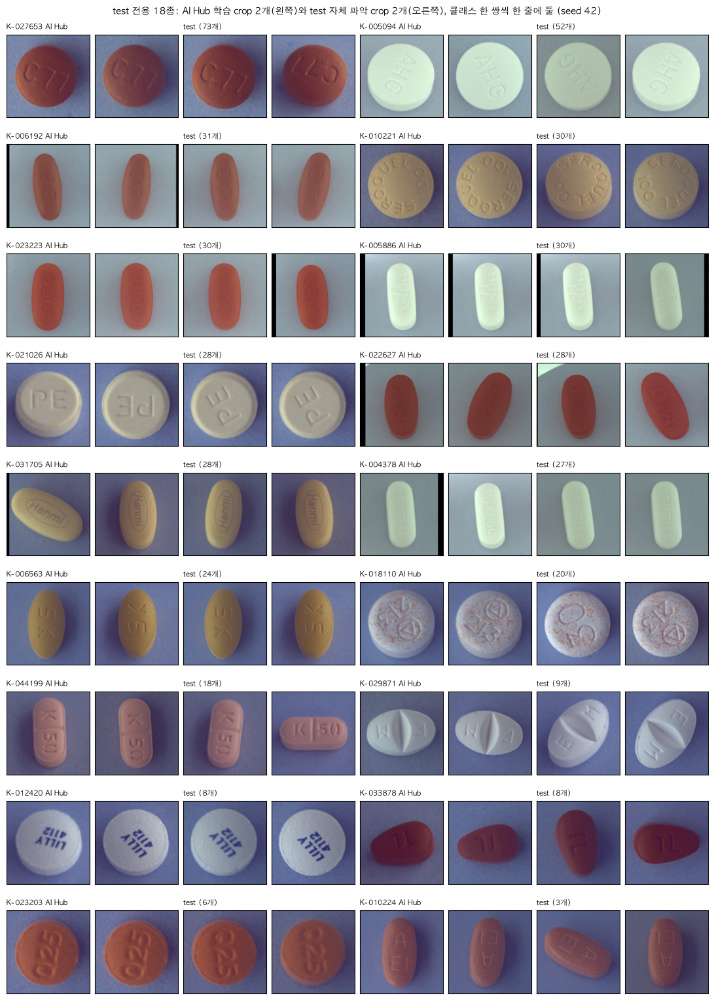

In [ ]:
N_CROPS = 2
test_image_cache = {}


def test_image(f):
    if f not in test_image_cache:
        test_image_cache[f] = Image.open(TEST_IMG_DIR / f).convert('RGB')
    return test_image_cache[f]


aihub_objects = collections.defaultdict(list)   # test 전용 클래스 → [(파일명, box)]
for name, im in images.items():
    if im['source'] == 'aihub':
        for c, box, _ in im['objects']:
            if c in TEST_ONLY:
                aihub_objects[c].append((name, box))
test_objects = collections.defaultdict(list)
for crop in test_crops:
    if crop['category_id'] in TEST_ONLY:
        test_objects[crop['category_id']].append((crop['test_file'], crop['bbox']))

classes = sorted(TEST_ONLY, key=lambda c: -counts['test'][c])
n_rows = (len(classes) + 1) // 2
fig, axes = plt.subplots(n_rows, 2 * N_CROPS * 2, figsize=(2 * N_CROPS * 2 * 1.35, n_rows * 1.7), layout='constrained')
for i, c in enumerate(classes):
    r, base = i // 2, (i % 2) * 2 * N_CROPS
    picks_a = [aihub_objects[c][j] for j in rng.choice(len(aihub_objects[c]), N_CROPS, replace=False)]
    picks_t = [test_objects[c][j] for j in rng.choice(len(test_objects[c]), N_CROPS, replace=False)]
    for j, (name, box) in enumerate(picks_a):
        ax = axes[r, base + j]
        ax.imshow(crop_square(Image.open(DATA_DIR / IMAGE_DIRS['aihub'] / name).convert('RGB'), box))
        ax.set_title(f'{k_code(c)} AI Hub' if j == 0 else '', fontsize=8, loc='left')
    for j, (f, box) in enumerate(picks_t):
        ax = axes[r, base + N_CROPS + j]
        ax.imshow(crop_square(test_image(f), box))
        ax.set_title(f'test ({counts["test"][c]}개)' if j == 0 else '', fontsize=8, loc='left')
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f'test 전용 18종: AI Hub 학습 crop {N_CROPS}개(왼쪽)와 test 자체 파악 crop {N_CROPS}개(오른쪽), 클래스 한 쌍씩 한 줄에 둘 (seed {SEED})', fontsize=10)
save_fig(fig, '3-3_test_only_gallery')
plt.show()

**인사이트**
- 18종 모두 AI Hub 학습 crop과 test 자체 파악 crop이 같은 알약이다. 색, 모양, 각인(C77, AHG, SEROQUEL 100, PE, Hanmi, SK, K|50, LILLY 4112 등)이 일치한다.
- AI Hub crop 일부에 검은 띠(사진 가장자리)가 보이는 것은 crop을 정사각형으로 자를 때 사진 밖이 포함된 것이고 라벨 문제가 아니다.

**결론**
- AI Hub 사진의 알약과 test 알약의 대응은 맞다. 번호(3-1, 3-2)와 생김새(3-3)가 모두 맞으므로 test 전용 18종의 학습 라벨은 그대로 둔다.

## 4. bbox 크기와 입력 분포
- 목적: 출처(Kaggle, AI Hub) 사이에 box 스타일 차이가 있어 보정이 필요한지(가설 3), test 입력이 val과 다른 점이 있는지 정한다.
    - 대회 지표는 IoU 0.75~0.95를 쓰므로 box 여백이 몇 픽셀만 달라도 점수가 크게 바뀐다. (00 8-2: 중앙값 크기 box를 8px 옮기면 0.64)
    - test box는 자체 파악의 1차 RT-DETR 예측이라 크기 비교에는 쓰고 여백 비교에는 쓰지 않는다.

### 4-1a. 클래스별 box 크기
- 대회 클래스 74개 모두의 box 짧은 변(너비와 높이 중 작은 값, 픽셀)을 Kaggle 라벨, AI Hub 라벨, test 자체 파악 box로 나눠 상자 그림으로 본다.
    - 같은 알약은 같은 거리에서 찍혀 크기가 비슷해야 한다. 상자가 크게 어긋나면 그 클래스의 라벨이나 매핑을 의심한다.
    - test 객체 수가 많은 순서(2-1과 같은 순서)로 놓고, 한 줄에 25종씩 세 줄로 나눈다. 세 줄은 y축을 공유한다.
    - x축 이름 아래 괄호는 Kaggle box 수다. 3개뿐인 클래스는 Kaggle 중앙값이 box 하나의 값이다.
- 아래 세 묶음을 합친 클래스에 노란 배경을 칠하고, 4-1b에서 사진으로 본다.
    - 출처별 중앙값의 최대 ÷ 최소가 1.15 이상인 클래스
    - 상위 24종만 그린 이전 그림에서 중앙값이 달라 보인 4종(K-002483, K-001900, K-016551, K-030308)
    - 74종을 모두 그린 이 그림에서 상자가 달라 보인 5종(K-020877, K-019552, K-013900, K-038162, K-018147)

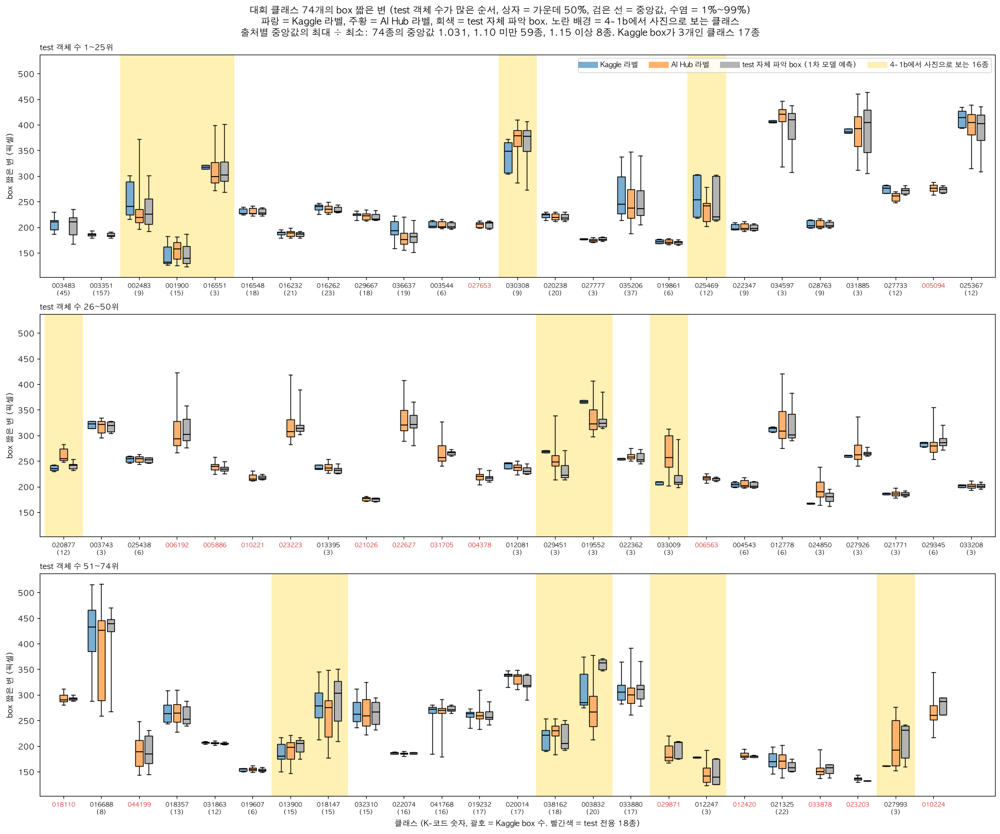

In [ ]:
BOX_SOURCES = ('kaggle', 'aihub', 'test')
short_sides = {src: collections.defaultdict(list) for src in BOX_SOURCES}
box_refs = {src: collections.defaultdict(list) for src in BOX_SOURCES}   # 클래스 → [(파일명, box)]. 4-1b에서 사진을 고를 때 쓴다
for name, im in images.items():
    for c, box, _ in im['objects']:
        if c in COMPETITION:
            short_sides[im['source']][c].append(min(box[2], box[3]))
            box_refs[im['source']][c].append((name, box))
for crop in test_crops:
    short_sides['test'][crop['category_id']].append(min(crop['bbox'][2], crop['bbox'][3]))
    box_refs['test'][crop['category_id']].append((crop['test_file'], crop['bbox']))

# 출처별 중앙값이 서로 다른 정도 = 중앙값의 최대 ÷ 최소 (box가 있는 출처끼리)
median_short = {c: {src: float(np.median(short_sides[src][c])) for src in BOX_SOURCES if short_sides[src][c]} for c in order}
median_spread = {c: max(m.values()) / min(m.values()) for c, m in median_short.items()}
SPREAD_TOL = 1.15
EYE_PICKED = [2483, 1900, 16551, 30308]   # 상위 24종만 그린 이전 그림에서 중앙값이 달라 보인 4종
EYE_PICKED_ALL = [20877, 19552, 13900, 38162, 18147]   # 74종을 모두 그린 이 그림에서 상자가 달라 보인 5종
gallery_classes = [c for c in order if c in EYE_PICKED + EYE_PICKED_ALL or median_spread[c] >= SPREAD_TOL]

N_ROWS = 3
per_row = -(-len(order) // N_ROWS)   # 한 줄에 25종
box_colors = {'kaggle': 'tab:blue', 'aihub': 'tab:orange', 'test': 'gray'}
box_labels = {'kaggle': 'Kaggle 라벨', 'aihub': 'AI Hub 라벨', 'test': 'test 자체 파악 box (1차 모델 예측)'}
box_tints = {src: 0.4 + 0.6 * np.array(matplotlib.colors.to_rgb(color)) for src, color in box_colors.items()}   # 흰 바탕에 투명도 0.6과 같은 색. 노란 배경 위에서도 색이 변하지 않게 불투명하게 칠한다
fig, axes = plt.subplots(N_ROWS, 1, figsize=(18, 15), sharey=True, layout='constrained')
for r, ax in enumerate(axes):
    classes = order[r * per_row:(r + 1) * per_row]
    pos = np.arange(len(classes)) * 4
    for p, c in zip(pos, classes):
        if c in gallery_classes:
            ax.axvspan(p - 1, p + 3, color='#fff0b3', zorder=0)
    for k, src in enumerate(BOX_SOURCES):
        parts = ax.boxplot([short_sides[src][c] or [np.nan] for c in classes], positions=pos + k, widths=0.8, whis=(1, 99),
                           showfliers=False, patch_artist=True, medianprops={'color': 'black', 'linewidth': 1.2})
        for patch in parts['boxes']:
            patch.set_facecolor(box_tints[src])
        ax.plot([], [], color=box_tints[src], linewidth=8, label=box_labels[src])
    ax.plot([], [], color='#fff0b3', linewidth=8, label=f'4-1b에서 사진으로 보는 {len(gallery_classes)}종')
    ax.set_xticks(pos + 1, [f'{k_code(c)[2:]}\n({len(short_sides["kaggle"][c])})' if short_sides['kaggle'][c] else k_code(c)[2:] for c in classes], fontsize=8)
    for tick, c in zip(ax.get_xticklabels(), classes):
        tick.set_color('tab:red' if c in TEST_ONLY else 'black')
    ax.set_xlim(-1.5, per_row * 4 - 0.5)
    ax.set_ylabel('box 짧은 변 (픽셀)')
    ax.set_title(f'test 객체 수 {r * per_row + 1}~{r * per_row + len(classes)}위', fontsize=10, loc='left')
axes[0].legend(ncol=4, fontsize=9, loc='upper right')
axes[-1].set_xlabel('클래스 (K-코드 숫자, 괄호 = Kaggle box 수. 빨간색 = test 전용 18종)')
spreads = np.array(list(median_spread.values()))
fig.suptitle('대회 클래스 74개의 box 짧은 변 (test 객체 수가 많은 순서, 상자 = 가운데 50%, 검은 선 = 중앙값, 수염 = 1%~99%)\n'
             '파랑 = Kaggle 라벨, 주황 = AI Hub 라벨, 회색 = test 자체 파악 box. 노란 배경 = 4-1b에서 사진으로 보는 클래스\n'
             f'출처별 중앙값의 최대 ÷ 최소: 74종의 중앙값 {np.median(spreads):.3f}, 1.10 미만 {np.sum(spreads < 1.10)}종, '
             f'{SPREAD_TOL} 이상 {np.sum(spreads >= SPREAD_TOL)}종. Kaggle box가 3개인 클래스 {sum(len(short_sides["kaggle"][c]) == 3 for c in order)}종')
save_fig(fig, '4-1a_box_short_side')
plt.show()

**인사이트**
- 74종 중 59종은 출처별 box 짧은 변 중앙값의 최대 ÷ 최소가 1.10 미만이다. 74종의 중앙값은 1.031이고, 대부분의 클래스는 세 출처의 상자가 겹친다.
- 1.15 이상인 클래스는 8종(K-001900, K-025469, K-029451, K-033009, K-003832, K-029871, K-012247, K-027993)이다.
    - 이 중 K-029451, K-033009, K-012247, K-027993은 Kaggle box가 3개뿐이다.
    - Kaggle 56종 중 17종이 box 3개다. 이 17종의 Kaggle 중앙값은 box 하나의 값이다.
    - K-003832, K-029871, K-012247, K-027993은 test box도 6~10개뿐이다. (2-1 표)
- 이전 그림에서 눈으로 고른 4종의 최대 ÷ 최소는 K-001900 1.19, K-002483 1.10, K-030308 1.09, K-016551 1.06이다.
- 74종 그림에서 눈으로 더 고른 5종은 K-013900 1.14, K-019552 1.14, K-038162 1.12, K-018147 1.10, K-020877 1.08이다. 모두 1.15 기준보다 작다.
- 노란 배경은 16종이다. 1.15 이상 8종에 눈으로 고른 9종을 더하고, 두 묶음에 모두 든 K-001900을 한 번만 센다.
- K-003483과 K-003351은 AI Hub에 없고, test 전용 18종은 Kaggle 라벨이 없어 상자가 두 개다.

**결론**
- 노란 배경 16종은 4-1b에서 사진으로 원인을 확인하고, 크기 보정 여부는 4-1b에서 정한다.

### 4-1b. 중앙값이 출처마다 다른 클래스의 사진
- 4-1a의 노란 배경 클래스마다, 출처(Kaggle 라벨, AI Hub 라벨, test 자체 파악 box)별로 짧은 변이 25%, 50%(중앙값), 75% 순위인 box를 하나씩 골라 사진 위에 겹쳐 그린다.
    - 4-1a 상자의 아래 끝, 검은 선, 위 끝에 해당하는 box다. 무작위가 아니라 순위로 고르므로 seed와 상관없다.
    - 한 줄(한 클래스)의 crop은 모두 같은 크기로 잘라, 출처 사이의 box 크기를 그대로 비교할 수 있게 한다.
- 중앙값 차이가 알약 자체(놓인 방향, 앞뒷면, 촬영 각도)에서 오는지, box를 그린 방식(여백, 그림자 포함)에서 오는지, 다른 알약이 섞였는지 본다.
    - test box는 1차 RT-DETR 예측이라 여백은 모델의 습관이다. 크기와 알약 종류만 본다.

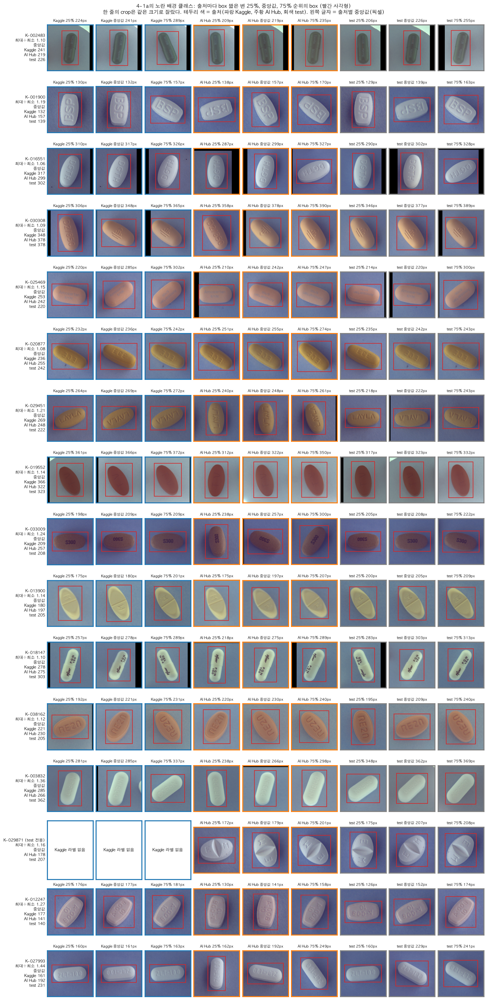

In [ ]:
QUANTILES = {0.25: '25%', 0.5: '중앙값', 0.75: '75%'}   # 상자 아래 끝, 검은 선, 위 끝에 해당하는 box
source_names = {'kaggle': 'Kaggle', 'aihub': 'AI Hub', 'test': 'test'}
image_dirs = {'kaggle': DATA_DIR / IMAGE_DIRS['kaggle'], 'aihub': DATA_DIR / IMAGE_DIRS['aihub']}


def quantile_picks(refs):
    """짧은 변 순서로 정렬해 25%, 50%, 75% 순위의 box를 고른다. box가 3개면 3개를 모두 고른다."""
    ranked = sorted(refs, key=lambda ref: (min(ref[1][2], ref[1][3]), ref[0]))
    return [ranked[round(q * (len(ranked) - 1))] for q in QUANTILES]


n_cols = len(BOX_SOURCES) * len(QUANTILES)
fig, axes = plt.subplots(len(gallery_classes), n_cols, figsize=(n_cols * 1.5, len(gallery_classes) * 1.75), layout='constrained')
for row, c in zip(axes, gallery_classes):
    picks = {src: quantile_picks(box_refs[src][c]) if box_refs[src][c] else [] for src in BOX_SOURCES}
    side = 1.25 * max(max(box[2], box[3]) for refs in picks.values() for _, box in refs)   # 한 줄의 crop은 같은 크기로 잘라 box 크기를 바로 비교한다
    for k, src in enumerate(BOX_SOURCES):
        for j, label_q in enumerate(QUANTILES.values()):
            ax = row[k * len(QUANTILES) + j]
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor(box_colors[src])
                spine.set_linewidth(2)
            if not picks[src]:
                ax.text(0.5, 0.5, f'{source_names[src]} 라벨 없음', ha='center', va='center', fontsize=8, transform=ax.transAxes)
                continue
            name, (x, y, w, h) = picks[src][j]
            image = test_image(name) if src == 'test' else Image.open(image_dirs[src] / name).convert('RGB')
            x0, y0 = x + w / 2 - side / 2, y + h / 2 - side / 2
            ax.imshow(image.crop((int(x0), int(y0), int(x0 + side), int(y0 + side))))
            ax.add_patch(plt.Rectangle((x - int(x0), y - int(y0)), w, h, fill=False, edgecolor='tab:red', linewidth=1.2))
            ax.set_title(f'{source_names[src]} {label_q} {min(w, h):.0f}px', fontsize=7)
    m = median_short[c]
    row[0].set_ylabel(f'{k_code(c)}{" (test 전용)" if c in TEST_ONLY else ""}\n최대÷최소 {median_spread[c]:.2f}\n중앙값\n'
                      + '\n'.join(f'{source_names[s]} {m[s]:.0f}' for s in BOX_SOURCES if s in m),
                      fontsize=8, rotation=0, ha='right', va='center')
fig.suptitle('4-1a의 노란 배경 클래스: 출처마다 box 짧은 변 25%, 중앙값, 75% 순위의 box (빨간 사각형)\n'
             '한 줄의 crop은 같은 크기로 잘랐다. 테두리 색 = 출처(파랑 Kaggle, 주황 AI Hub, 회색 test). 왼쪽 글자 = 출처별 중앙값(픽셀)', fontsize=10)
save_fig(fig, '4-1b_box_size_gallery')
plt.show()

**인사이트**
- 16종 모두 한 줄의 세 출처가 같은 약이다. 각인(BSP, DGTH, LAYLA, S300, ZLT-100, ECE, PGN 150 등)과 색이 같다.
- 빨간 box는 세 출처 모두 알약 가장자리에 붙어 있다. 출처 사이의 여백 차이는 보이지 않는다.
- 중앙값 차이는 긴 알약이 놓인 방향에서 온다. box는 사진 축에 맞춘 사각형이라, 긴 알약이 비스듬히 놓이면 짧은 변이 알약 폭보다 커진다.
    - K-003832: Kaggle과 AI Hub의 25%·중앙값 crop은 세로로 놓여 238~285px이고, test 세 crop은 모두 비스듬히 놓여 348~369px이다.
    - K-033009: Kaggle과 test는 가로로 놓여 198~222px이고, AI Hub 중앙값·75% crop은 비스듬히 놓여 257~300px이다.
    - K-027993: 가로·세로로 반듯하게 놓인 crop은 160~163px이고, 조금 기운 AI Hub 중앙값 crop은 192px, 비스듬한 AI Hub 75%와 test 중앙값·75% crop은 229~249px이다.
    - K-001900: 가로·세로로 놓인 crop은 129~139px이고, 비스듬한 crop은 157~170px이다.
- 새로 더한 5종도 같은 이유다.
    - K-019552: Kaggle 세 crop(361~372px)은 같은 방향으로 크게 기울어 있고, AI Hub 25%·중앙값(312~322px)과 test 세 crop(317~332px)은 세로에 가깝게 놓였다.
    - K-013900: 세로로 놓인 Kaggle 25%·중앙값과 AI Hub 25% crop은 175~180px이고, 비스듬한 crop은 197~209px이다.
    - K-038162: 가로·세로에 가깝게 놓인 Kaggle 25%, test 25%·중앙값 crop은 192~209px이고, 비스듬한 crop은 220~240px이다.
    - K-018147(캡슐): 세로로 선 AI Hub 25% crop은 218px이고, 기울어진 crop은 257~313px이다.
    - K-020877: 세 출처 모두 가로로 놓여 232~274px이다. 차이(1.08)가 가장 작고, 가장 큰 AI Hub 75% crop(274px)이 조금 더 기울었다.
- Kaggle box가 3개인 클래스(K-016551, K-029451, K-033009, K-019552, K-012247, K-027993)는 Kaggle 세 crop의 알약 방향과 주변이 같다. 한 번 놓은 알약을 각도만 바꿔 찍은 사진이라(1-2a), Kaggle 중앙값은 놓인 방향 하나의 값이다.
- K-029871(test 전용)은 타원형 알약이다. AI Hub 25% crop(172px)은 가로로, test 중앙값 crop(207px)은 비스듬히 놓였다.

**결론**
- 출처별 중앙값 차이는 알약이 놓인 방향의 차이이고, 라벨 여백이나 클래스 매핑 문제가 아니다. 출처 간 box 크기 보정은 하지 않는다.
- 클래스 하나의 중앙값 비교는 놓인 방향에 흔들리므로, 출처 간 여백은 4-2처럼 여러 클래스의 중앙값 비를 모아서 판단한다.

### 4-2. 출처 간 box 여백 차이
- Kaggle 라벨과 AI Hub 라벨이 모두 있는 클래스마다 box 너비·높이의 중앙값을 구해 산점도로 비교한다.
    - 대각선 위에 있으면 두 출처의 여백이 같다. ±5% 선 밖의 클래스에 이름을 적는다.
    - 01 3-1에서는 알약 경계와 box 사이 여백 차이의 중앙값이 0~1px였다.

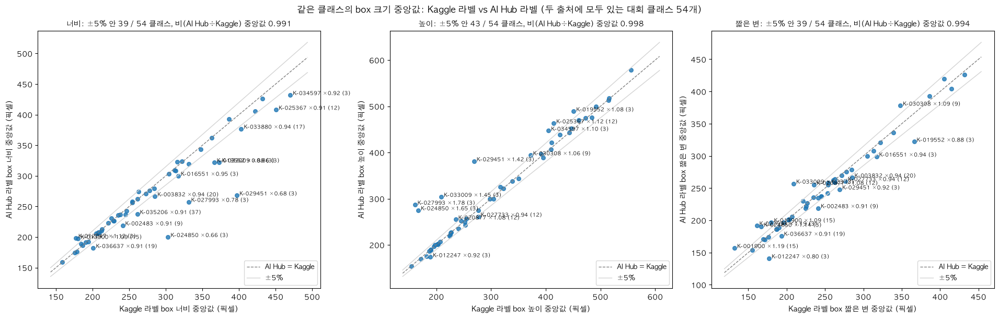

In [ ]:
TOL = 0.05  # 이 비율 밖으로 어긋난 클래스에 이름을 적는다
dims = {src: collections.defaultdict(lambda: {'w': [], 'h': [], 's': []}) for src in ('kaggle', 'aihub')}
for name, im in images.items():
    for c, (x, y, w, h), _ in im['objects']:
        if c in COMPETITION:
            dims[im['source']][c]['w'].append(w)
            dims[im['source']][c]['h'].append(h)
            dims[im['source']][c]['s'].append(min(w, h))   # 짧은 변: 알약이 가로·세로로 놓인 차이에 덜 흔들린다
shared = sorted(c for c in COMPETITION if dims['kaggle'][c]['w'] and dims['aihub'][c]['w'])

fig, axes = plt.subplots(1, 3, figsize=(19, 6), layout='constrained')
for ax, dim, dim_name in zip(axes, ('w', 'h', 's'), ('너비', '높이', '짧은 변')):
    kag = np.array([np.median(dims['kaggle'][c][dim]) for c in shared])
    aih = np.array([np.median(dims['aihub'][c][dim]) for c in shared])
    ratio = aih / kag
    ax.scatter(kag, aih, s=30, color='tab:blue', alpha=0.8)
    lims = [min(kag.min(), aih.min()) * 0.9, max(kag.max(), aih.max()) * 1.05]
    ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1, label='AI Hub = Kaggle')
    ax.plot(lims, [l * (1 + TOL) for l in lims], color='lightgray', linewidth=1)
    ax.plot(lims, [l * (1 - TOL) for l in lims], color='lightgray', linewidth=1, label=f'±{TOL:.0%}')
    for c, kx, ay, r in zip(shared, kag, aih, ratio):
        if abs(r - 1) > TOL:   # 이름 뒤 괄호는 Kaggle box 수. 3개면 중앙값이 각도 하나에 좌우된다
            ax.annotate(f'{k_code(c)} ×{r:.2f} ({len(dims["kaggle"][c][dim])})', (kx, ay), fontsize=7, textcoords='offset points', xytext=(4, 0))
    ax.set_xlabel(f'Kaggle 라벨 box {dim_name} 중앙값 (픽셀)')
    ax.set_ylabel(f'AI Hub 라벨 box {dim_name} 중앙값 (픽셀)')
    ax.set_title(f'{dim_name}: ±{TOL:.0%} 안 {np.sum(np.abs(ratio - 1) <= TOL)} / {len(shared)} 클래스, 비(AI Hub÷Kaggle) 중앙값 {np.median(ratio):.3f}', fontsize=10)
    ax.legend(fontsize=9, loc='lower right')
fig.suptitle(f'같은 클래스의 box 크기 중앙값: Kaggle 라벨 vs AI Hub 라벨 (두 출처에 모두 있는 대회 클래스 {len(shared)}개)')
save_fig(fig, '4-2_box_margin_by_source')
plt.show()

**인사이트**
- Kaggle 라벨과 AI Hub 라벨의 box 크기 중앙값 비(AI Hub ÷ Kaggle)는 너비 0.991, 높이 0.998, 짧은 변 0.994로 1에 붙어 있다. 체계적인 여백 차이는 없다.
- ±5% 밖의 클래스는 너비 15개, 높이 11개, 짧은 변 15개다. 대부분 Kaggle box가 3~9개뿐인 클래스(괄호 안 수)이거나 긴 알약이 비스듬히 놓여 축에 맞춘 box가 커진 경우다.
    - 예: K-024850은 너비 ×0.66, 높이 ×1.65로 Kaggle 사진에서 알약이 90° 돌아가 있다. 짧은 변으로 보면 ×1.14다.
- 01 3-1(알약 경계와 box 사이 여백 차이 중앙값 0~1px)과 같은 결론이다.

**결론**
- 출처 간 box 스타일 보정은 하지 않는다. 학습 라벨의 여백은 Kaggle과 AI Hub가 같다.
- 5-2에서 val-Kaggle과 val-AI Hub의 IoU 0.95 AP가 비슷하게 높은 것도 이 결과와 맞는다.

### 4-3. 이미지당 알약 수와 밝기
- 그룹(train-Kaggle, train-AI Hub, val-Kaggle, val-AI Hub, test)별로 이미지당 알약 수의 비율과 이미지 평균 밝기(회색조 0~255, 1/16로 줄인 사진의 평균)의 분포를 비교한다.
    - AI Hub와 test는 seed를 고정해 그룹당 최대 500장을 뽑는다. 밝기는 `runs/eda_raewoo/cache/03_brightness.json`에 저장해 다시 실행할 때 건너뛴다.
- 실행 시간: 처음 실행할 때 약 1분 (이미지 읽기)

밝기 계산 0초 (1,732장)


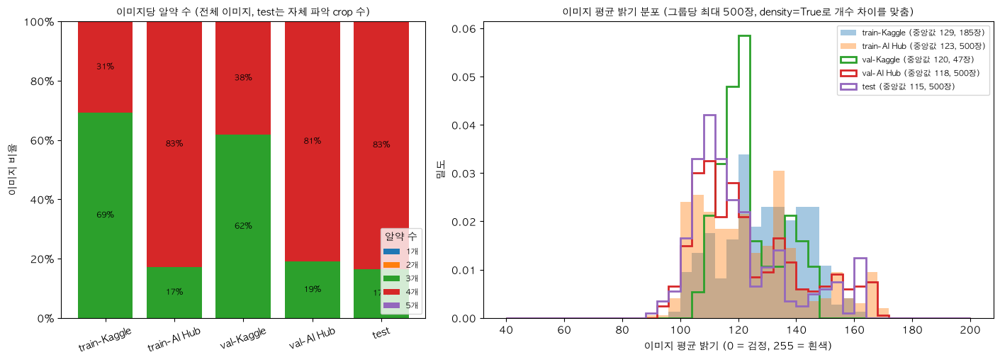

In [ ]:
N_SAMPLE = 500
BRIGHTNESS_CACHE = CACHE_DIR / '03_brightness.json'
brightness = json.loads(BRIGHTNESS_CACHE.read_text()) if BRIGHTNESS_CACHE.exists() else {}

groups = {'train-Kaggle': [], 'train-AI Hub': [], 'val-Kaggle': [], 'val-AI Hub': [], 'test': []}
for name, im in images.items():
    groups[f"{split_of[name]}-{'Kaggle' if im['source'] == 'kaggle' else 'AI Hub'}"].append((DATA_DIR / IMAGE_DIRS[im['source']] / name, len(im['objects'])))
groups['test'] = [(TEST_IMG_DIR / f, len(test_boxes[f])) for f in test_files]
sampled = {g: [items[i] for i in rng.choice(len(items), min(N_SAMPLE, len(items)), replace=False)] for g, items in groups.items()}


def mean_brightness(path):
    key = str(path.relative_to(PROJECT_ROOT))
    if key not in brightness:
        with Image.open(path) as image:
            brightness[key] = float(np.asarray(image.convert('L').resize((IMG_W // 16, IMG_H // 16))).mean())
    return brightness[key]


start = time.perf_counter()
values = {g: np.array([mean_brightness(p) for p, _ in items]) for g, items in sampled.items()}
BRIGHTNESS_CACHE.write_text(json.dumps(brightness))
print(f'밝기 계산 {time.perf_counter() - start:.0f}초 ({sum(len(v) for v in values.values()):,}장)')

fig, (ax_count, ax_bright) = plt.subplots(1, 2, figsize=(14, 5), layout='constrained', width_ratios=[1, 1.4])
pill_bins = [1, 2, 3, 4, 5]
bottom = np.zeros(len(groups))
for n in pill_bins:
    share = np.array([np.mean([k == n for _, k in items]) for items in groups.values()])
    bars = ax_count.bar(list(groups), share, bottom=bottom, label=f'{n}개')
    for b, s in zip(bars, share):
        if s >= 0.04:
            ax_count.text(b.get_x() + b.get_width() / 2, b.get_y() + s / 2, f'{s:.0%}', ha='center', va='center', fontsize=8)
    bottom += share
ax_count.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax_count.set_ylabel('이미지 비율')
ax_count.set_title('이미지당 알약 수 (전체 이미지, test는 자체 파악 crop 수)', fontsize=10)
ax_count.legend(title='알약 수', fontsize=8, loc='lower right')
ax_count.tick_params(axis='x', rotation=20)
bins = np.linspace(40, 200, 41)
for (g, v), style in zip(values.items(), ['bar', 'bar', 'step', 'step', 'step']):
    if style == 'bar':
        ax_bright.hist(v, bins=bins, density=True, alpha=0.4, label=f'{g} (중앙값 {np.median(v):.0f}, {len(v)}장)')
    else:
        ax_bright.hist(v, bins=bins, density=True, histtype='step', linewidth=2, label=f'{g} (중앙값 {np.median(v):.0f}, {len(v)}장)')
ax_bright.set_xlabel('이미지 평균 밝기 (0 = 검정, 255 = 흰색)')
ax_bright.set_ylabel('밀도')
ax_bright.set_title(f'이미지 평균 밝기 분포 (그룹당 최대 {N_SAMPLE}장, density=True로 개수 차이를 맞춤)', fontsize=10)
ax_bright.legend(fontsize=8)
save_fig(fig, '4-3_pills_and_brightness')
plt.show()

**인사이트**
- 이미지당 알약 수: Kaggle 사진은 3개가 많고(train 69%, val 62%), AI Hub와 test는 4개가 81~83%다. test는 AI Hub와 같은 구성이다.
- 평균 밝기 중앙값은 test 115 < val-AI Hub 118 < val-Kaggle 120 < train-AI Hub 123 < train-Kaggle 129다. test가 가장 어둡지만 분포(90~170)는 다섯 그룹이 겹친다.
    - test의 밝기 분포는 val-AI Hub(빨간 선)와 가장 비슷하다.

**결론**
- 입력 분포(알약 수, 밝기)에서 test는 Kaggle train보다 AI Hub 쪽에 가깝고, val-AI Hub가 test를 잘 대표한다. 밝기 보정이나 증강은 추가하지 않는다.
- test가 조금 어둡다는 점은 모델이 더 어두운 AI Hub 사진을 이미 학습했으므로 원인 후보에서 뺀다.

## 5. 2차 모델 재현
- 목적: 점수 손실이 모델 쪽에 있는지, val과 test 자체 파악으로 볼 수 있는 한계까지 확인한다.
    - 로컬 가중치는 2차 v3 e10 세 모델(`runs/models/exp2_v3_{yolo26s,rtdetr-l,frcnn}_e10_s0_best.pt`)이다. 추론 설정은 2차 노트북과 같다.
        - Ultralytics: `predict(conf=0.001, imgsz=640)`, NMS IoU 0.7, 이미지당 최대 300개
        - Faster R-CNN: 입력 640, `score_thresh 0.001`, NMS 0.5, 이미지당 최대 100개, 라벨 = `classes.csv`의 `idx_v3 + 1` (2차 F-RCNN 노트북 `class_map.csv`와 같은 규칙)
    - 예측은 `runs/eda_raewoo/cache/03_val_pred_<모델>.json`에 저장해 다시 실행할 때 건너뛴다.

### 5-1. val 점수 재현
- 0절에서 추론한 세 모델의 val 예측(`val_predictions`)을 `evaluate_val`로 채점해 점수 3개(val, kaggle 47장, test_only)를 다시 재고 기록된 값과 비교한다.
- 기록은 2차 실험에서 채점할 때 저장한 값이다.
    - F-RCNN: 체크포인트의 `scores`
    - YOLO26s, RT-DETR-l: Google Drive run 폴더의 `scores.json` (`pill data/runs/v3_yolo26s_e10_s0`, `pill data/jw_runs/v3_rtdetr-l_e10`)
- `채점한 예측 수`는 무시 규칙(`drop_ignored`)이 대회 밖 예측을 버리고 남은 수다. `scores.json`의 `n_predictions`와 같은 값이다.

In [ ]:
RECORDED = {'yolo26s': {'val': 0.9901, 'kaggle': 0.9920, 'test_only': 0.9888, 'n_predictions': 4681},      # Drive pill data/runs/v3_yolo26s_e10_s0/scores.json
            'rtdetr-l': {'val': 0.9882, 'kaggle': 0.9971, 'test_only': 0.9861, 'n_predictions': 193475},  # Drive pill data/jw_runs/v3_rtdetr-l_e10/scores.json
            'frcnn': torch.load(WEIGHTS['frcnn'], map_location='cpu', weights_only=False)['scores']}  # 체크포인트에 기록된 값
val_scores = {name: evaluate_val(preds, val_gt) for name, preds in val_predictions.items()}
SCORE_KEYS = ['val', 'kaggle', 'test_only']
rows = []
for name, s in val_scores.items():
    r = RECORDED[name]
    rows += [[name, '재현', f"{len(val_predictions[name]):,}", f"{s['n_predictions']:,}", *[f'{s[k]:.4f}' for k in SCORE_KEYS]],
             [name, '기록', '-', f"{r['n_predictions']:,}", *[f'{r[k]:.4f}' for k in SCORE_KEYS]]]
show_table(['모델 (v3 e10)', '구분', '예측 수 (conf 0.001)', '채점한 예측 수', 'val', 'kaggle 47장', 'test_only'], rows)

| 모델 (v3 e10) | 구분 | 예측 수 (conf 0.001) | 채점한 예측 수 | val | kaggle 47장 | test_only |
| --- | --- | --- | --- | --- | --- | --- |
| yolo26s | 재현 | 6,221 | 4,688 | 0.9900 | 0.9920 | 0.9894 |
| yolo26s | 기록 | - | 4,681 | 0.9901 | 0.9920 | 0.9888 |
| rtdetr-l | 재현 | 300,000 | 193,633 | 0.9872 | 0.9971 | 0.9853 |
| rtdetr-l | 기록 | - | 193,475 | 0.9882 | 0.9971 | 0.9861 |
| frcnn | 재현 | 5,602 | 4,247 | 0.9949 | 0.9969 | 0.9950 |
| frcnn | 기록 | - | 4,250 | 0.9949 | 0.9969 | 0.9950 |

**인사이트**
- 세 모델의 점수 3개가 모두 기록과 0.001 안에서 같다.
    - F-RCNN은 소수 넷째 자리까지 같다. (0.9949 / 0.9969 / 0.9950)
    - YOLO26s는 val 0.0001, test_only 0.0006 차이다. (test_only 재현 0.9894, 기록 0.9888)
    - RT-DETR-l은 val 0.0010, test_only 0.0008 낮다. (val 재현 0.9872, 기록 0.9882) kaggle은 0.9971로 같다.
- 채점한 예측 수도 기록과 0.2% 안에서 같다. (재현 / 기록: YOLO26s 4,688 / 4,681, RT-DETR-l 193,633 / 193,475, F-RCNN 4,247 / 4,250)
    - 로컬 가중치와 추론 설정이 2차 채점 때와 같다고 본다. 남은 차이는 결론을 바꿀 크기가 아니다.
- `kaggle` 47장 점수는 0.992~0.997로 `val`보다 오히려 높다. 대회 측 라벨로 채점해도 모델은 거의 완벽하다.
- RT-DETR 예측은 300,000개(이미지당 300개)다. RT-DETR은 NMS 없이 쿼리 300개를 모두 내기 때문이고, 낮은 score 예측은 AP에 영향이 없다(6-4 conf≥0.5 제출과 같은 이유).

**결론**
- 로컬 추론 파이프라인은 2차 실험과 같다. 이후 5-2~6-1의 예측을 2차 결과의 대리로 쓴다.
- val 0.99는 모델·방법에 관계없이 재현되므로, 0.61과의 차이는 모델이 아니라 val이 보지 못하는 곳에 있다.

### 5-2. IoU 기준별·출처별 AP
- 모델마다 IoU 기준 0.75, 0.80, 0.85, 0.90, 0.95 각각의 AP(대회 클래스 평균)를 val-Kaggle 47장과 val-AI Hub 953장으로 나눠 그린다.
    - 대회 점수는 이 다섯 값의 평균이다. 0.95에서만 떨어지면 box가 1~2px 수준으로만 어긋난다는 뜻이고, 0.75부터 낮으면 놓침이나 클래스 오류가 있다는 뜻이다.

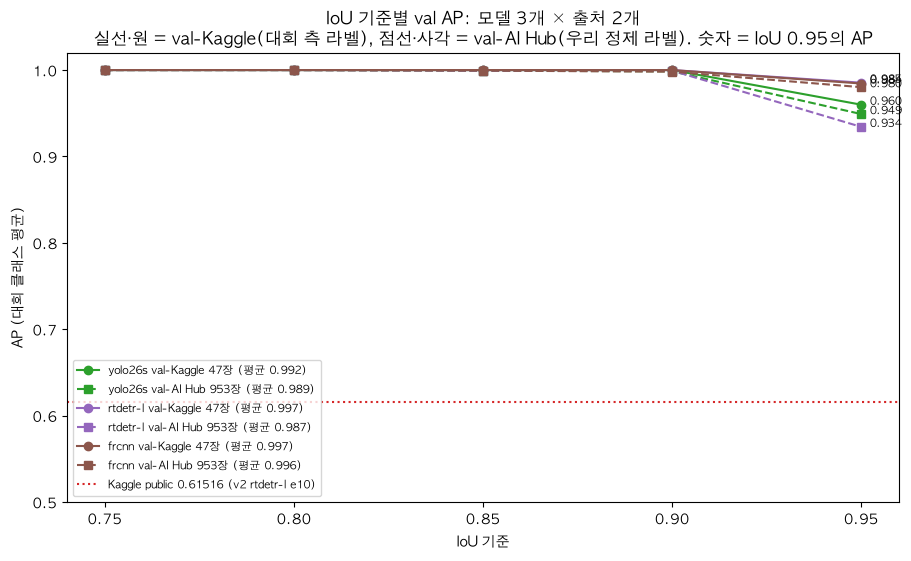

In [ ]:
source_ids = {s: {im['id'] for im in val_gt['images'] if im['source'] == s} for s in ('kaggle', 'aihub')}
kept_predictions = {name: drop_ignored(preds, val_gt) for name, preds in val_predictions.items()}   # evaluate_val과 같은 무시 규칙
curves = {}
for name, preds in kept_predictions.items():
    for s, ids in source_ids.items():
        precision, _ = coco_precision(val_gt, preds, image_ids=ids, category_ids=COMPETITION)
        curves[(name, s)] = ap_by_threshold(precision)

fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
colors = {'yolo26s': 'tab:green', 'rtdetr-l': 'tab:purple', 'frcnn': 'tab:brown'}
for (name, s), aps in curves.items():
    ax.plot(IOU_THRESHOLDS, aps, marker='o' if s == 'kaggle' else 's', linestyle='-' if s == 'kaggle' else '--', color=colors[name],
            label=f"{name} {'val-Kaggle 47장' if s == 'kaggle' else 'val-AI Hub 953장'} (평균 {aps.mean():.3f})")
    ax.annotate(f'{aps[-1]:.3f}', (IOU_THRESHOLDS[-1], aps[-1]), fontsize=8, textcoords='offset points', xytext=(6, 0))
ax.axhline(KAGGLE_SCORES['원본'], color='tab:red', linestyle=':', linewidth=1.5, label=f"Kaggle public {KAGGLE_SCORES['원본']} (v2 rtdetr-l e10)")
ax.set_xticks(IOU_THRESHOLDS)
ax.set_xlabel('IoU 기준')
ax.set_ylabel('AP (대회 클래스 평균)')
ax.set_ylim(0.5, 1.02)
ax.set_title('IoU 기준별 val AP: 모델 3개 × 출처 2개\n실선·원 = val-Kaggle(대회 측 라벨), 점선·사각 = val-AI Hub(우리 정제 라벨). 숫자 = IoU 0.95의 AP')
ax.legend(fontsize=8, loc='lower left')
save_fig(fig, '5-2_ap_by_iou_source')
plt.show()

**인사이트**
- IoU 기준 0.75, 0.80, 0.85, 0.90에서는 세 모델, 두 출처 모두 AP 1.000이다. 놓침이나 클래스 오류가 없다.
- 0.95에서만 떨어진다: val-AI Hub는 RT-DETR 0.934, YOLO26s 0.949, F-RCNN 0.980이고 val-Kaggle은 0.960~0.984다.
    - 우리 라벨 기준으로 box 오차는 1~2px 수준이다(0.95를 넘기려면 200px box에서 2~3px 안에 들어야 한다).
- 대회 측 라벨(val-Kaggle)과 우리 정제 라벨(val-AI Hub)의 곡선 모양이 같다. 라벨 출처에 따른 차이가 없다.
- Kaggle 실측 0.615(빨간 점선)는 어느 곡선과도 멀다. 0.615가 나오려면 0.90·0.95에서 거의 0이거나 0.75부터 떨어져야 한다.

**결론**
- val에서 IoU 기준별로 봐도 손실은 보이지 않는다. 점수를 잃는 곳은 val 라벨(대회 측 train 라벨 포함)과 다른 어떤 것, 즉 test 정답 자체다.
- **3차 이후 val 비교는 IoU 0.95 AP를 따로 기록한다. 나머지 기준은 모두 1.0이라 차이가 나지 않는다.**

### 5-3a. 클래스별 val AP
- 모델마다 클래스별 val AP(IoU 0.75~0.95 평균)를 val 객체 수에 대해 산점도로 그린다.
    - AP가 0.95 아래인 클래스에 이름을 적는다. val 객체가 적은 클래스의 AP는 한두 개의 오류로 크게 흔들린다.

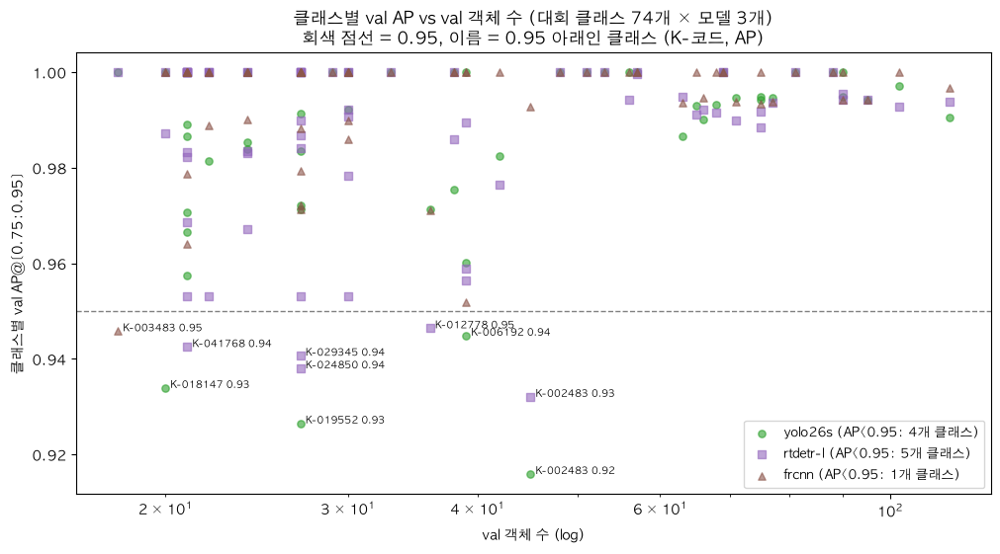

In [ ]:
AP_MARK = 0.95
val_counts = collections.Counter(a['category_id'] for a in val_gt['annotations'] if a['category_id'] in COMPETITION)
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
markers = {'yolo26s': 'o', 'rtdetr-l': 's', 'frcnn': '^'}
low = set()
for name, scores in val_scores.items():
    xs = [val_counts[c] for c in scores['per_class']]
    ys = list(scores['per_class'].values())
    ax.scatter(xs, ys, marker=markers[name], s=28, alpha=0.6, color=colors[name], label=f'{name} (AP<{AP_MARK}: {sum(y < AP_MARK for y in ys)}개 클래스)')
    for c, ap in scores['per_class'].items():
        if ap < AP_MARK:
            low.add(c)
            ax.annotate(f'{k_code(c)} {ap:.2f}', (val_counts[c], ap), fontsize=7, textcoords='offset points', xytext=(4, 0))
ax.axhline(AP_MARK, color='gray', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('val 객체 수 (log)')
ax.set_ylabel('클래스별 val AP@[0.75:0.95]')
ax.set_title(f'클래스별 val AP vs val 객체 수 (대회 클래스 74개 × 모델 3개)\n회색 점선 = {AP_MARK}, 이름 = {AP_MARK} 아래인 클래스 (K-코드, AP)')
ax.legend(fontsize=9, loc='lower right')
save_fig(fig, '5-3a_per_class_ap')
plt.show()

**인사이트**
- 클래스별 val AP는 0.92~1.00이다. 0.95 아래인 클래스는 YOLO26s 4개, RT-DETR 5개, F-RCNN 1개이고 모두 val 객체가 45개 이하인 클래스다.
    - 가장 낮은 값은 K-002483(YOLO26s 0.92, RT-DETR 0.93), K-019552(YOLO26s 0.93), K-018147(YOLO26s 0.93)이다.
- K-019552(YOLO26s 0.93)는 1차 RT-DETR이 test에서 K-012778과 헷갈렸던 클래스다. (1-2b)
    - 2차 제출 2개(RT-DETR-l)는 test에서 이 두 클래스 48개의 클래스를 모두 맞혔다. (5-4)
    - val에서 깎인 이유도 클래스 혼동이 아니라 IoU 0.95의 box 정밀도다. (5-3b)
- val 객체 60개 이상인 클래스는 세 모델 모두 0.98 이상이다.

**결론**
- val에서 특별히 못 맞히는 클래스는 없다. 클래스 불균형이 지금 점수를 막는 원인이 아니다.
- 3차에서 클래스별로 볼 때는 K-002483, K-019552, K-012778, K-018147을 모니터링 클래스로 둔다.

### 5-3b. val AP 0.95 이하 클래스의 train·val 객체 수
- 세 모델 중 하나라도 val AP가 0.95 이하인 클래스마다 약 이름, 사진, train·val 객체 수를 가로 막대로 그린다. 5-3a 그림에 이름을 적은 클래스와 같다.
    - 학습 객체가 적어서 AP가 낮은지 본다. 회색 점선은 대회 클래스 74종의 중앙값이다.
    - train 수는 2-1의 train(Kaggle + AI Hub)이다. v3는 대회 클래스가 없는 사진만 빼므로, 세 모델이 학습한 v3 train의 대회 클래스 수와 같다.
    - 사진은 val 사진에서 파일명 순서로 처음 나오는 그 약이다. 사진 가장자리에 걸린 알약은 건너뛴다.
- 이름 아래에 모델별 AP와 AP@0.95를 적는다.
    - AP는 IoU 0.75~0.95 다섯 기준의 평균(5-3a와 같은 값)이고, AP@0.95는 IoU 0.95 하나의 AP다.
    - AP@0.95만 낮고 평균 AP가 그만큼 덜 낮으면, 클래스는 맞히고 box가 1~2px 어긋나는 것이다. (5-2)
- 실행 시간: 약 10초 (모델마다 AP@0.95를 다시 계산)

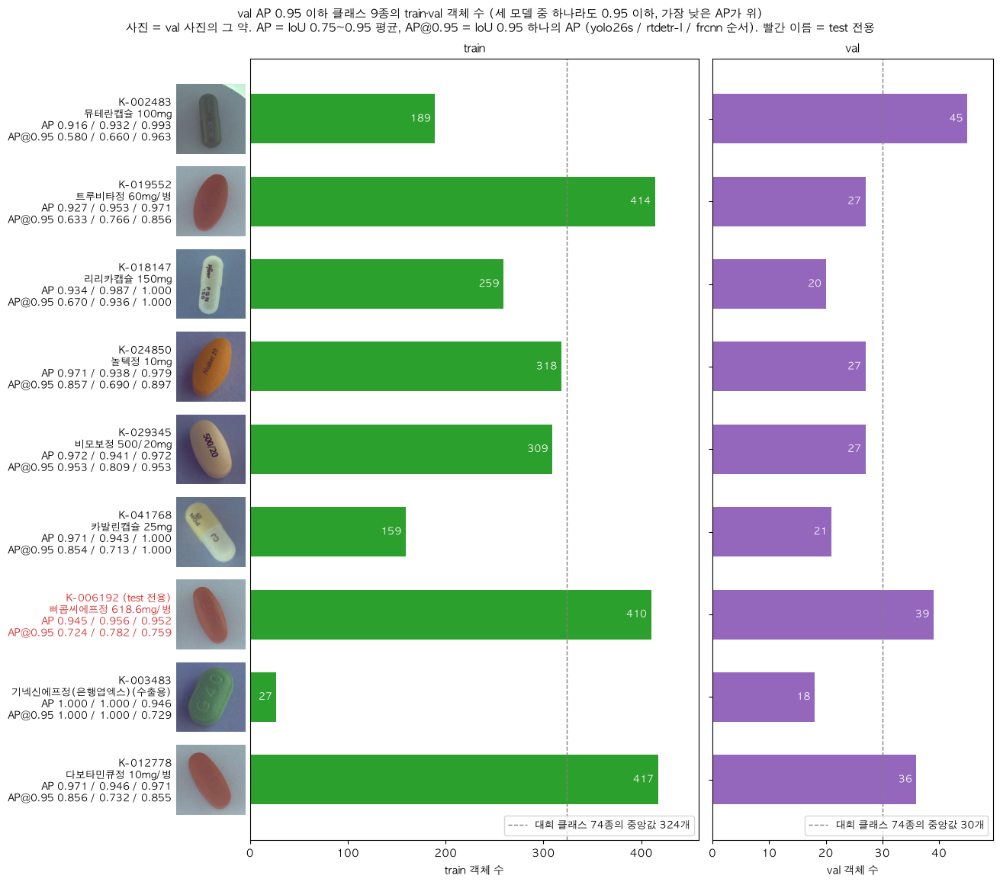

In [ ]:
LOW_CLASSES = sorted({c for s in val_scores.values() for c, ap in s['per_class'].items() if ap <= AP_MARK},
                     key=lambda c: (min(s['per_class'][c] for s in val_scores.values()), c))   # 세 모델 중 가장 낮은 AP 순서
ap_strict = {}   # 모델 → 클래스 → IoU 0.95 하나의 AP
for name, preds in kept_predictions.items():
    precision, category_order = coco_precision(val_gt, preds, category_ids=COMPETITION, iou_thresholds=[IOU_THRESHOLDS[-1]])
    ap_strict[name] = {c: precision[0, :, k][precision[0, :, k] > -1].mean() for k, c in enumerate(category_order)}
train_counts = {c: counts['train-kaggle'][c] + counts['train-aihub'][c] for c in COMPETITION}   # 2차 v3 train의 객체 수 (2-1과 같다)
file_of = {im['id']: im['file_name'] for im in val_gt['images']}
val_photo = {}   # 클래스 → val 사진에서 파일명 순서로 처음 나오는, 사진 가장자리에 걸리지 않는 그 약의 crop
for a in sorted(val_gt['annotations'], key=lambda a: (file_of[a['image_id']], a['id'])):
    x, y, w, h = a['bbox']
    half = max(w, h) * 1.1 / 2   # crop_square가 자르는 정사각형의 반 (pad 0.1)
    inside = half <= x + w / 2 <= IMG_W - half and half <= y + h / 2 <= IMG_H - half
    if a['category_id'] in LOW_CLASSES and a['category_id'] not in val_photo and inside:
        val_photo[a['category_id']] = crop_square(Image.open(VAL_IMG_DIR / file_of[a['image_id']]).convert('RGB'), a['bbox'])

PHOTO_PT = 66   # 사진 한 변 (포인트)
rows_y = np.arange(len(LOW_CLASSES))
fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(13, len(LOW_CLASSES) * 1.1 + 1.6), sharey=True, width_ratios=[1.6, 1], layout='constrained')
for ax, values, color, split in ((ax_train, train_counts, 'tab:green', 'train'), (ax_val, val_counts, 'tab:purple', 'val')):
    n = [values[c] for c in LOW_CLASSES]
    median = np.median([values[c] for c in COMPETITION])
    ax.barh(rows_y, n, 0.6, color=color)
    for yi, v in zip(rows_y, n):
        ax.annotate(f'{v:,}', (v, yi), xytext=(-4, 0), textcoords='offset points', ha='right', va='center', color='white', fontsize=9)
    ax.axvline(median, color='gray', linestyle='--', linewidth=1, label=f'대회 클래스 74종의 중앙값 {median:.0f}개')
    ax.set_xlim(0, max(*n, median) * 1.1)
    ax.set_xlabel(f'{split} 객체 수')
    ax.set_title(split, fontsize=11)
    ax.legend(fontsize=9, loc='lower right')
labels = [f"{k_code(c)}{' (test 전용)' if c in TEST_ONLY else ''}\n{names[c]}\n"
          f"AP {' / '.join(f'{s['per_class'][c]:.3f}' for s in val_scores.values())}\n"
          f"AP@0.95 {' / '.join(f'{ap_strict[m][c]:.3f}' for m in val_scores)}" for c in LOW_CLASSES]
ax_train.set_yticks(rows_y, labels, fontsize=9)
ax_train.tick_params(axis='y', length=0, pad=PHOTO_PT + 8)   # 이름과 축 사이에 사진 자리를 둔다
for tick, c in zip(ax_train.get_yticklabels(), LOW_CLASSES):
    tick.set_color('tab:red' if c in TEST_ONLY else 'black')
ax_train.invert_yaxis()
for yi, c in zip(rows_y, LOW_CLASSES):
    ax_train.add_artist(AnnotationBbox(OffsetImage(np.asarray(val_photo[c]), zoom=PHOTO_PT / val_photo[c].width), (0, yi), xycoords=ax_train.get_yaxis_transform(),
                                       xybox=(-PHOTO_PT / 2 - 4, 0), boxcoords='offset points', frameon=False, annotation_clip=False))
fig.suptitle(f'val AP {AP_MARK} 이하 클래스 {len(LOW_CLASSES)}종의 train·val 객체 수 (세 모델 중 하나라도 {AP_MARK} 이하, 가장 낮은 AP가 위)\n'
             f'사진 = val 사진의 그 약. AP = IoU 0.75~0.95 평균, AP@0.95 = IoU 0.95 하나의 AP ({" / ".join(val_scores)} 순서). 빨간 이름 = test 전용', fontsize=11)
save_fig(fig, '5-3b_low_ap_class_counts')
plt.show()

**인사이트**
- 세 모델 중 하나라도 val AP가 0.95 이하인 클래스는 9종이다. YOLO26s 4종, RT-DETR 5종, F-RCNN 1종이고, 두 모델에 겹치는 클래스는 K-002483(YOLO26s 0.916, RT-DETR 0.932)뿐이다.
- train 수는 27~417개로 넓게 퍼져 있다. 74종 중앙값 324개보다 적은 클래스가 6종, 많은 클래스가 3종이다.
    - K-012778(417개), K-019552(414개), K-006192(410개)는 중앙값보다 많이 학습했는데도 0.95 이하다.
    - train이 가장 적은 K-003483(27개)은 F-RCNN만 0.946이고 YOLO26s와 RT-DETR은 1.000이다.
- val 수는 18~45개이고, 9종 중 6종이 74종 중앙값 30개보다 적다. val 객체가 적을수록 box 몇 개의 차이로 AP가 크게 흔들린다. (5-3a)
- 0.95 이하인 AP 10개(YOLO26s 4, RT-DETR 5, F-RCNN 1)는 AP@0.95가 0.580~0.809다. 가장 낮은 값은 K-002483 YOLO26s의 0.580이다.
    - 평균 AP와 AP@0.95로 거꾸로 계산하면, 나머지 IoU 기준 4개(0.75~0.90)의 평균 AP는 K-029345 말고 모두 0.999 이상이다. (3자리 반올림 오차) 예: K-002483 YOLO26s는 (5 × 0.916 − 0.580) ÷ 4 = 1.000이다.
    - K-029345만 같은 계산이 0.974~0.977이다. 이 클래스는 IoU 0.90 이하에서도 조금 깎인다.
- 사진으로 보면 9종 중 캡슐이 3종(K-002483, K-018147, K-041768), 붉은 갈색 타원형 정제가 3종(K-019552, K-006192, K-012778)이다.
    - K-019552와 K-012778은 1차 RT-DETR이 test에서 헷갈린 짝이다. (1-2b) 하지만 두 클래스의 IoU 0.75~0.90 평균 AP가 0.999 이상이므로, val에서는 세 모델 모두 이 짝을 헷갈리지 않는다.

**결론**
- val AP가 0.95 이하인 원인은 학습 객체 수가 아니다. train이 74종 중앙값보다 많은 3종도 들어 있고, 손실은 클래스 분류가 아니라 IoU 0.95의 box 정밀도에서 나온다.
- 3차 실험(클래스 불균형 대응)으로 이 9종의 val AP가 오를 것으로 기대하지 않는다. 5-3a의 모니터링 클래스 4종은 그대로 두고, 3차에서는 이 클래스들의 변화를 평균 AP가 아니라 AP@0.95로 읽는다.

### 5-4. 제출 CSV의 자체 파악 대리 채점
- 제출 파일 2개(0.61516, 0.61558)를 test 자체 파악을 정답으로 채점한다.
    - IoU 0.5 AP: 자체 파악 box는 1차 모델 예측이라 느슨한 기준으로 검출과 분류만 본다.
    - 알약별 클래스 일치율: 자체 파악 알약마다 IoU 0.5 이상으로 겹친 예측 중 score가 가장 높은 것의 클래스가 같은 비율. 겹친 예측이 없으면 "놓침"이다.
    - IoU 중앙값: 그 가장 높은 예측과 자체 파악 box의 IoU. 1차 모델 box와 2차 모델 box가 얼마나 같은지를 뜻한다.

In [ ]:
PROXY_IOU = 0.5
test_gt = {'images': [{'id': int(Path(f).stem), 'file_name': f, 'width': IMG_W, 'height': IMG_H} for f in test_files],
           'annotations': [{'id': i + 1, 'image_id': int(Path(c['test_file']).stem), 'category_id': c['category_id'], 'bbox': c['bbox'],
                            'area': c['bbox'][2] * c['bbox'][3], 'iscrowd': 0} for i, c in enumerate(test_crops)],
           'categories': [{'id': c, 'competition': 1} for c in sorted(COMPETITION)]}
rows = []
for run, preds in submissions.items():
    by_file = collections.defaultdict(list)
    for p in preds:
        by_file[p['file_name']].append(p)
    ap = {g: ap_by_threshold(coco_precision(test_gt, preds, category_ids=group, iou_thresholds=[PROXY_IOU])[0])[0]
          for g, group in (('all', COMPETITION), ('kaggle', KAGGLE_CLASSES), ('test_only', TEST_ONLY))}
    matched, missed, ious = {'kaggle': [], 'test_only': []}, {'kaggle': 0, 'test_only': 0}, []
    for crop in test_crops:
        g = 'test_only' if crop['category_id'] in TEST_ONLY else 'kaggle'
        candidates = [p for p in by_file[crop['test_file']] if box_iou(p['bbox'], crop['bbox']) >= PROXY_IOU]
        if not candidates:
            missed[g] += 1
            continue
        best = max(candidates, key=lambda p: p['score'])
        matched[g].append(best['category_id'] == crop['category_id'])
        ious.append(box_iou(best['bbox'], crop['bbox']))
    rows.append([run, f'{SUBMISSIONS[run][1]:.5f}', f"{len(preds):,} ({len(preds) / len(test_files):.0f}/장)", f"{ap['all']:.3f}", f"{ap['kaggle']:.3f}", f"{ap['test_only']:.3f}",
                 f"{np.mean(matched['kaggle']):.1%}", f"{np.mean(matched['test_only']):.1%}", f"{missed['kaggle'] + missed['test_only']}", f'{np.median(ious):.3f}'])
show_table(['제출', 'Kaggle public', '예측 수', f'AP@{PROXY_IOU} 전체', f'AP@{PROXY_IOU} Kaggle 56종', f'AP@{PROXY_IOU} test 전용 18종', '클래스 일치 Kaggle', '클래스 일치 test 전용', '놓친 알약', '자체 파악 box와 IoU 중앙값'], rows)

| 제출 | Kaggle public | 예측 수 | AP@0.5 전체 | AP@0.5 Kaggle 56종 | AP@0.5 test 전용 18종 | 클래스 일치 Kaggle | 클래스 일치 test 전용 | 놓친 알약 | 자체 파악 box와 IoU 중앙값 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| v2 rtdetr-l e10 | 0.61516 | 90,354 (107/장) | 1.000 | 1.000 | 1.000 | 100.0% | 100.0% | 0 | 0.979 |
| v4 rtdetr-l e5 | 0.61558 | 173,409 (206/장) | 1.000 | 1.000 | 1.000 | 99.9% | 100.0% | 0 | 0.978 |

**인사이트**
- 고친 자체 파악 기준으로 두 제출 모두 AP@0.5 1.000(Kaggle 56종, test 전용 모두 1.000)이고 놓친 알약은 0개다.
- 클래스 일치는 v2 e10이 Kaggle 100.0%·test 전용 100.0%, v4 e5가 Kaggle 99.9%·test 전용 100.0%다.
    - 고치기 전 자체 파악으로는 AP@0.5 0.996, Kaggle 클래스 일치 99.7~99.8%였다. 차이는 모두 1-2b에서 고친 K-012778·K-019552 5개이고, 두 제출 모두 이 5개를 맞게 예측했다.
    - v4 e5에 남은 불일치 2개(175.png, 560.png)는 02 3-2에서 사람이 각인으로 K-030308로 고친 알약이고, v2 e10은 이 둘도 맞혔다.
- 1차 모델 box와의 IoU 중앙값은 0.978~0.979다. 대회 측 train 라벨로만 학습한 1차 모델과 2차 모델이 test에서 거의 같은 box를 그린다.
- v4 e5는 이미지당 206개, v2 e10은 107개를 냈지만 점수(0.61558 vs 0.61516)와 대리 채점이 같다.

**결론**
- 우리 라벨 기준으로 모델은 test에서도 검출·분류가 완벽하다. 손실은 IoU 0.75~0.95 구간의 box 정밀도이거나, 대회 정답이 우리 라벨과 다른 경우뿐이다.
- 자체 파악 box는 1차 예측이라 IoU 0.75 이상은 재지 못한다. 이 한계 안에서 "모델 쪽 원인"은 닫는다.

## 6. 정답 쪽 손실 추정 (평가 기준선)
- 목적: test 정답이 우리 라벨과 다를 때 점수가 얼마나 떨어지는지 상한을 잡고, 진단 제출 결과를 해석하는 기준을 만든다.
    - 5번까지의 결과가 "우리 라벨 기준으로 모델은 거의 완벽하다"라면, 남는 차이는 우리 라벨(예측)과 대회 test 정답 사이에 있다.
    - 로컬에는 test 정답이 없으므로, val 정답을 바꿔 보는 민감도와 원본·정제 라벨 차이로 상한을 추정한다.

### 6-1. 채점 코드 검증
- `evaluate.py`의 채점이 Kaggle과 같은 규칙인지 다섯 가지로 확인한다.
    - (a) val 정답을 그대로 예측(score 1)으로 넣으면 1.000이어야 한다.
    - (b) rtdetr-l val 예측을 `write_submission`으로 CSV에 쓰고 다시 읽어 채점한다. bbox 소수 둘째 자리·score 소수 넷째 자리 반올림과 열 순서가 점수를 바꾸지 않아야 한다. (val 파일명은 숫자가 아니라 image id로 바꿔 쓴다)
    - (c) 같은 예측을 pycocotools 없이 직접 구현한 AP(pycocotools와 같은 규칙: 이미지·클래스마다 score 상위 100개, 클래스·IoU 기준마다 score 순 탐욕 매칭, 101점 보간)로 계산해 `coco_map`과 비교한다.
    - (d) 무시 규칙(`drop_ignored`) 두 가지 중 ②를 끄고 채점해 val 점수 변화량을 본다. test에는 대회 클래스 밖 알약이 없어서 ②가 버릴 예측도 없다.
        - ① 대회 밖 클래스로 낸 예측을 버린다. `coco_map`이 대회 클래스만 채점하므로 켜든 끄든 점수가 같다.
        - ② 대회 클래스 밖 알약의 정답 box와 IoU 0.5 이상 겹친 예측을 클래스와 상관없이 버린다.
    - (e) val 채점(`drop_ignored`의 ①)과 test 제출(`write_submission`)은 대회 밖 클래스 예측을 똑같이 지운다. AI Hub 전용 클래스(44종, v3 모델은 22종 학습)를 따로 배운 모델에서 이 처리가 점수를 깎는지 센다.
        - 무시 규칙이 버린 예측 수를 규칙별로 센다.
        - 대회 클래스 정답 알약 중, IoU 0.5 이상 겹친 예측의 1등이 대회 밖 클래스인 수를 센다. 이 경우 1등 예측이 지워져, val과 test 모두 그 알약을 더 낮은 score의 예측으로 채점하거나 놓친다.

In [ ]:
def simple_map(gt, predictions, category_ids, iou_thresholds=IOU_THRESHOLDS, max_det=100):
    """pycocotools 없이 계산한 mAP. 클래스·IoU 기준마다 예측을 score 순으로 보며 아직 짝이 없는 정답 중 IoU가 가장 큰 것과 짝짓고, 101점 보간 AP를 평균한다."""
    image_of = {im['file_name']: im['id'] for im in gt['images']}
    gts = collections.defaultdict(list)
    for a in gt['annotations']:
        if a['category_id'] in category_ids:
            gts[(a['image_id'], a['category_id'])].append(a['bbox'])
    dts = collections.defaultdict(list)   # (이미지, 클래스) → [(score, box)]
    for p in predictions:
        if p['category_id'] in category_ids:
            dts[(image_of[p['file_name']], p['category_id'])].append((p['score'], p['bbox']))
    for key, dlist in dts.items():   # pycocotools처럼 이미지·클래스마다 score 상위 max_det개만 센다
        dts[key] = sorted(dlist, key=lambda d: -d[0])[:max_det]
    recall_points = np.linspace(0, 1, 101)
    aps = []
    for c in sorted({k[1] for k in gts}):
        n_gt = sum(len(v) for k, v in gts.items() if k[1] == c)
        for thr in iou_thresholds:
            scored = []   # (score, 맞음 여부)
            for (image_id, cat), dlist in dts.items():
                if cat != c:
                    continue
                gt_boxes = gts.get((image_id, c), [])
                used = [False] * len(gt_boxes)
                for score, box in sorted(dlist, key=lambda d: -d[0]):
                    ious = [box_iou(box, g) if not used[j] else -1 for j, g in enumerate(gt_boxes)]
                    j = int(np.argmax(ious)) if ious else -1
                    if j >= 0 and ious[j] >= thr:
                        used[j] = True
                        scored.append((score, 1))
                    else:
                        scored.append((score, 0))
            scored.sort(key=lambda s: -s[0])
            tp = np.cumsum([s[1] for s in scored])
            fp = np.cumsum([1 - s[1] for s in scored])
            recall = tp / n_gt if len(tp) else np.array([])
            precision = tp / np.maximum(tp + fp, 1e-9) if len(tp) else np.array([])
            for i in range(len(precision) - 2, -1, -1):   # 정밀도 봉투(뒤에서 앞으로 최댓값)
                precision[i] = max(precision[i], precision[i + 1])
            idx = np.searchsorted(recall, recall_points, side='left')
            aps.append(np.mean([precision[i] if i < len(precision) else 0.0 for i in idx]))
    return float(np.mean(aps))


gt_as_predictions = [{'image_id': a['image_id'], 'category_id': a['category_id'], 'bbox': a['bbox'], 'score': 1.0} for a in val_gt['annotations']]
score_a, _ = coco_map(val_gt, gt_as_predictions, category_ids=COMPETITION)

rtdetr_kept = kept_predictions['rtdetr-l']
id_of = {im['file_name']: im['id'] for im in val_gt['images']}
name_of = {f'{im["id"]}.png': im['file_name'] for im in val_gt['images']}
roundtrip_csv = CACHE_DIR / '03_roundtrip_val_submission.csv'
write_submission([{**p, 'file_name': f"{id_of[p['file_name']]}.png"} for p in rtdetr_kept], roundtrip_csv, COMPETITION)
with open(roundtrip_csv, newline='', encoding='utf-8') as f:
    reread = [{'file_name': name_of[f"{row['image_id']}.png"], 'category_id': int(row['category_id']), 'score': float(row['score']),
               'bbox': [float(row[k]) for k in ('bbox_x', 'bbox_y', 'bbox_w', 'bbox_h')]} for row in csv.DictReader(f)]
score_b, _ = coco_map(val_gt, reread, category_ids=COMPETITION)
score_b0 = val_scores['rtdetr-l']['val']
start = time.perf_counter()
score_c = simple_map(val_gt, rtdetr_kept, COMPETITION)
score_c_time = time.perf_counter() - start
# (d) ①(대회 밖 클래스 제거)만 남기고 ②(대회 밖 알약과 겹친 예측 제거)는 끈다
score_d, _ = coco_map(val_gt, [p for p in val_predictions['rtdetr-l'] if p['category_id'] in COMPETITION], category_ids=COMPETITION)

# (e) 무시 규칙이 버린 예측을 규칙별로 세고, 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수(val 채점과 test 제출 모두 그 1등 예측이 지워지는 경우)를 센다
all_rtdetr = val_predictions['rtdetr-l']
n_noncomp_class = sum(p['category_id'] not in COMPETITION for p in all_rtdetr)
n_overlap_ignore = len(all_rtdetr) - n_noncomp_class - len(rtdetr_kept)
by_image = collections.defaultdict(list)
for p in all_rtdetr:
    by_image[id_of[p['file_name']]].append(p)
top_is_noncomp = {'kaggle': 0, 'aihub': 0}
n_comp_gt = {'kaggle': 0, 'aihub': 0}
source_of_id = {im['id']: im['source'] for im in val_gt['images']}
for a in val_gt['annotations']:
    if a['category_id'] not in COMPETITION:
        continue
    s = source_of_id[a['image_id']]
    n_comp_gt[s] += 1
    overlapping = [p for p in by_image[a['image_id']] if box_iou(p['bbox'], a['bbox']) >= 0.5]
    if overlapping and max(overlapping, key=lambda p: p['score'])['category_id'] not in COMPETITION:
        top_is_noncomp[s] += 1

show_table(['검사', '결과', '비교 대상', '차이'], [
    ['(a) val 정답을 예측으로 넣은 mAP@[0.75:0.95]', f'{score_a:.4f}', '1.0000', f'{score_a - 1:+.4f}'],
    ['(b) rtdetr-l 예측 → write_submission CSV → 다시 읽어 채점', f'{score_b:.4f}', f'원본 예측 {score_b0:.4f}', f'{score_b - score_b0:+.4f}'],
    [f'(c) 직접 구현한 AP (pycocotools 없이, {score_c_time:.0f}초)', f'{score_c:.4f}', f'coco_map {score_b0:.4f}', f'{score_c - score_b0:+.4f}'],
    ['(d) 무시 규칙 ②(대회 밖 알약과 겹친 예측 제거) 끄고 채점', f'{score_d:.4f}', f'무시 규칙 적용 {score_b0:.4f}', f'{score_d - score_b0:+.4f}'],
    ['(e) rtdetr-l val 예측 중 무시 규칙이 버린 수: ① 대회 밖 클래스 / ② 대회 밖 알약과 겹침', f'{n_noncomp_class:,} / {n_overlap_ignore:,}', f'전체 예측 {len(all_rtdetr):,}개', f'{(n_noncomp_class + n_overlap_ignore) / len(all_rtdetr):.1%}'],
    ['(e) 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수 (val-Kaggle / val-AI Hub)', f"{top_is_noncomp['kaggle']} / {top_is_noncomp['aihub']}", f"정답 알약 {n_comp_gt['kaggle']:,} / {n_comp_gt['aihub']:,}개", f"{top_is_noncomp['kaggle'] / n_comp_gt['kaggle']:.2%} / {top_is_noncomp['aihub'] / n_comp_gt['aihub']:.2%}"],
])

| 검사 | 결과 | 비교 대상 | 차이 |
| --- | --- | --- | --- |
| (a) val 정답을 예측으로 넣은 mAP@[0.75:0.95] | 1.0000 | 1.0000 | +0.0000 |
| (b) rtdetr-l 예측 → write_submission CSV → 다시 읽어 채점 | 0.9872 | 원본 예측 0.9872 | -0.0000 |
| (c) 직접 구현한 AP (pycocotools 없이, 2초) | 0.9872 | coco_map 0.9872 | -0.0000 |
| (d) 무시 규칙 ②(대회 밖 알약과 겹친 예측 제거) 끄고 채점 | 0.9872 | 무시 규칙 적용 0.9872 | -0.0000 |
| (e) rtdetr-l val 예측 중 무시 규칙이 버린 수: ① 대회 밖 클래스 / ② 대회 밖 알약과 겹침 | 70,706 / 35,661 | 전체 예측 300,000개 | 35.5% |
| (e) 대회 클래스 정답 알약 중 가장 높은 예측이 대회 밖 클래스인 수 (val-Kaggle / val-AI Hub) | 0 / 0 | 정답 알약 159 / 2,894개 | 0.00% / 0.00% |

**인사이트**
- (a) 정답을 예측으로 넣으면 1.0000이다. (b) 제출 CSV 왕복(bbox 소수 둘째 자리, score 소수 넷째 자리 반올림) 뒤 점수가 0.9872로 같다. (c) pycocotools 없이 직접 구현한 AP도 0.9872로 같다. (d) 무시 규칙 ②를 꺼도 0.9872로 같다.
- (e) RT-DETR val 예측 300,000개 중 무시 규칙이 버린 것은 ① 대회 밖 클래스 70,706개, ② 대회 밖 알약과 겹친 것 35,661개로 35.5%다.
    - ①로 버린 예측은 원래 대회 클래스 채점에 들어가지 않는다. ②로 버린 예측은 (d)에서 점수를 바꾸지 않았다.
- (e) 대회 클래스 정답 알약 3,053개 중 겹친 예측의 1등이 대회 밖 클래스인 경우는 val-Kaggle 0, val-AI Hub 0이다. 대회 밖 클래스 예측을 지워서 1등 예측을 잃는 알약이 val에는 없다.
    - test에서도 대회 밖 클래스를 지운 제출 CSV가 자체 파악 알약을 하나도 놓치지 않았다. (5-4)

**결론**
- 채점 코드, 제출 변환, AI Hub 전용 클래스 처리(학습에 포함, 채점·제출에서 제외)는 val과 test 점수 차이의 원인이 아니다.
- Kaggle 채점은 74종 평균(6-4)과 score 순서 존중(conf≥0.5 제출)에서 `evaluate.py`와 같은 규칙임이 확인됐다. 남는 차이는 정답의 출처(우리 정제 라벨 vs 대회 test 라벨)뿐이다.

### 6-2a. box 오차 민감도
- val 정답 box를 세 가지로 바꿔 예측(score 1, 클래스 그대로)으로 넣고 mAP@[0.75:0.95]를 계산한다.
    - 이동: x, y를 각각 0~40px(2px 간격) 옮긴다. (00 8-2와 같은 방법, 이번에는 2차 val 3,790개)
    - 배율: 중심을 고정하고 너비·높이를 0.90~1.10배(1% 간격)로 바꾼다. (진단 제출 scale0.98·1.02와 같은 방법)
    - 흔들림: 네 꼭짓점 좌표(x1, y1, x2, y2)에 각각 평균 0, 표준편차 σ(0~16px)의 정규분포 잡음을 더한다. (seed 고정)
    - 빨간 점선은 Kaggle 실측 0.615이다. 각 요인이 단독으로 이 점수를 만드는 값을 읽는다.

민감도 계산 36초


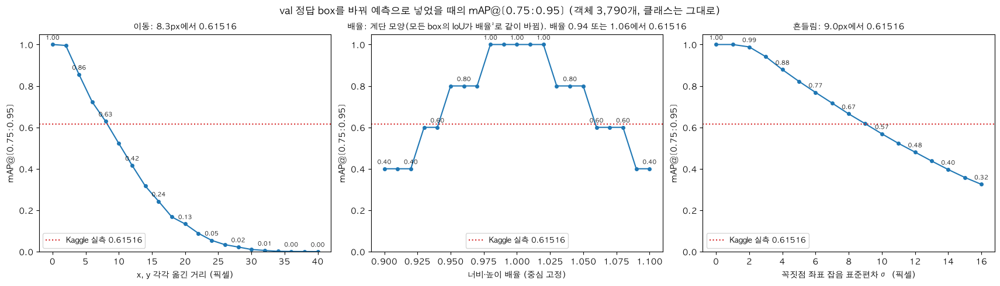

In [ ]:
SHIFTS = np.arange(0, 41, 2)
SCALES = np.round(np.arange(0.90, 1.101, 0.01), 2)
SIGMAS = np.arange(0, 17, 1)
gt_items = [(a['image_id'], a['category_id'], a['bbox']) for a in val_gt['annotations']]


def perturbed(items, shift=0.0, scale=1.0, sigma=0.0, seed=SEED):
    """정답 box를 옮기고(shift), 중심 고정으로 배율을 바꾸고(scale), 꼭짓점 좌표에 잡음(sigma)을 더한 예측 목록을 만든다."""
    noise_rng = np.random.default_rng(seed)
    out = []
    for image_id, c, (x, y, w, h) in items:
        cx, cy = x + w / 2 + shift, y + h / 2 + shift
        nw, nh = w * scale, h * scale
        x1, y1, x2, y2 = cx - nw / 2, cy - nh / 2, cx + nw / 2, cy + nh / 2
        if sigma > 0:
            x1, y1, x2, y2 = np.array([x1, y1, x2, y2]) + noise_rng.normal(0, sigma, 4)
        out.append({'image_id': image_id, 'category_id': c, 'bbox': [x1, y1, max(x2 - x1, 1e-3), max(y2 - y1, 1e-3)], 'score': 1.0})
    return out


def score_of(**kwargs):
    return coco_map(val_gt, perturbed(gt_items, **kwargs), category_ids=COMPETITION)[0]


start = time.perf_counter()
shift_map = np.array([score_of(shift=s) for s in SHIFTS])
scale_map = np.array([score_of(scale=s) for s in SCALES])
sigma_map = np.array([score_of(sigma=s) for s in SIGMAS])
print(f'민감도 계산 {time.perf_counter() - start:.0f}초')


def crossing(xs, ys, level):
    """곡선이 level을 처음 지나는 x를 선형 보간으로 구한다. (ys는 단조 감소를 가정)"""
    for i in range(1, len(xs)):
        if (ys[i - 1] - level) * (ys[i] - level) <= 0:
            return xs[i - 1] + (xs[i] - xs[i - 1]) * (ys[i - 1] - level) / (ys[i - 1] - ys[i])
    return np.nan


level = KAGGLE_SCORES['원본']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout='constrained')
for ax, xs, ys, xlabel, name in ((axes[0], SHIFTS, shift_map, 'x, y 각각 옮긴 거리 (픽셀)', '이동'),
                                 (axes[1], SCALES, scale_map, '너비·높이 배율 (중심 고정)', '배율'),
                                 (axes[2], SIGMAS, sigma_map, '꼭짓점 좌표 잡음 표준편차 σ (픽셀)', '흔들림')):
    ax.plot(xs, ys, marker='o', markersize=4)
    ax.axhline(level, color='tab:red', linestyle=':', linewidth=1.5, label=f'Kaggle 실측 {level}')
    for xi, yi in zip(xs, ys):
        if name == '이동' and xi % 4 == 0 or name == '배율' and round(xi * 100) % 2 == 0 or name == '흔들림' and xi % 2 == 0:
            ax.annotate(f'{yi:.2f}', (xi, yi), fontsize=7, textcoords='offset points', xytext=(0, 6), ha='center')
    if name == '배율':
        left, right = crossing(SCALES[SCALES <= 1][::-1], scale_map[SCALES <= 1][::-1], level), crossing(SCALES[SCALES >= 1], scale_map[SCALES >= 1], level)
        ax.set_title(f'{name}: 계단 모양(모든 box의 IoU가 배율²로 같이 바뀜). 배율 {left:.2f} 또는 {right:.2f}에서 {level}', fontsize=10)
    else:
        ax.set_title(f'{name}: {crossing(xs, ys, level):.1f}px에서 {level}', fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('mAP@[0.75:0.95]')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=9, loc='lower left' if name != '배율' else 'lower center')
fig.suptitle('val 정답 box를 바꿔 예측으로 넣었을 때의 mAP@[0.75:0.95] (객체 3,790개, 클래스는 그대로)')
save_fig(fig, '6-2a_sensitivity')
plt.show()

**인사이트**
- 이동: 2px까지는 1.00, 4px 0.86, 8px 0.63이고 8.3px에서 0.615가 된다. 00 8-2(1차 라벨)의 4px 0.87, 8px 0.64와 같다.
- 배율: 모든 box의 IoU가 배율²로 같이 바뀌므로 곡선이 계단이다. 0.98(IoU 0.960)과 1.02(IoU 0.961)는 아직 1.00이고, 0.94 또는 1.06이 되어야 0.615로 떨어진다.
    - 우리 box가 정답과 같다면 scale0.98 제출은 거의 떨어지지 않아야 한다. 실측은 −0.066이다. 많은 box가 이미 IoU 기준 근처에 걸려 있다는 뜻이고, 이는 정답과 우리 box 사이에 기하학적 불일치가 있다는 직접 증거다.
- 흔들림: 꼭짓점 좌표 잡음 σ 9px에서 0.615가 된다. σ 4px이면 0.88, 16px이면 0.32다.

**결론**
- 0.615는 정답 box가 우리 box에서 x·y로 약 8px 옮겨졌거나, 좌표마다 σ≈9px로 흔들린 것과 같은 크기다. 알약 box 중앙값 크기(약 200px)의 4% 수준이다.
- 어느 쪽인지, 그리고 정답이 조금 큰지는 6-2b에서 진단 제출 3점으로 가른다.

### 6-2b. Kaggle 실측 적합
- "대회 test 정답 = 우리 box에서 어긋난 box"라고 가정하고, 진단 제출과 같은 조작(배율 0.98, 1.00, 1.02)을 예측에 적용했을 때의 점수 3개를 어긋남 크기마다 계산한다.
    - 어긋남 모형 두 가지: 이동(x, y 각각 s px), 흔들림(꼭짓점 좌표 σ px).
    - Kaggle 실측 3점(0.549, 0.615, 0.605)과의 제곱 오차 합이 가장 작은 s와 σ를 찾고, 그 값에서 비대칭(0.98이 1.02보다 훨씬 많이 떨어짐)이 재현되는지 본다.
    - 2변수 모형: 위 어긋남에 더해 정답 box가 우리 box보다 g배(1.005~1.03) 큰 경우도 함께 적합한다. 정답이 조금 크면 1.02는 덜 떨어지고 0.98은 더 떨어진다.
    - 정답 box가 우리 box보다 체계적으로 크거나 작은 모형은 6-2a 배율 곡선이 이미 다룬다. 그 모형에서는 어느 한쪽 배율이 원본보다 올라야 하는데 실측은 둘 다 내려갔다.
- 실행 시간: 약 6분

In [ ]:
TARGET = np.array([KAGGLE_SCORES['scale0.98'], KAGGLE_SCORES['원본'], KAGGLE_SCORES['scale1.02']])
DIAG_SCALES = (0.98, 1.00, 1.02)
FIT_RANGE = np.arange(0, 17, 1)                        # 이동 s, 흔들림 σ (px)
GT_SCALES = (1.00, 1.005, 1.01, 1.015, 1.02, 1.03)     # 2변수 모형: 정답 box가 우리 box보다 g배 큰 경우까지 함께 본다
FIT_RANGE_2D = np.arange(5, 14, 1)


def fit_scores(**offset):
    """정답을 offset만큼 어긋나게 둔 뒤(= 우리 box가 정답에서 offset만큼 어긋난 것과 같다), 우리 box에 진단 배율을 적용한 점수 3개."""
    gt_shifted = {**val_gt, 'annotations': [{**a, 'bbox': p['bbox']} for a, p in zip(val_gt['annotations'], perturbed(gt_items, **offset))]}
    return np.array([coco_map(gt_shifted, perturbed(gt_items, scale=s), category_ids=COMPETITION)[0] for s in DIAG_SCALES])


start = time.perf_counter()
fits = {}   # (모형, 어긋남 크기, 정답 배율 g) → 점수 3개
for s in FIT_RANGE:
    fits[('이동', s, 1.0)] = fit_scores(shift=s)
    fits[('흔들림', s, 1.0)] = fit_scores(sigma=s)
for g in GT_SCALES[1:]:
    for s in FIT_RANGE_2D:
        fits[('이동', s, g)] = fit_scores(shift=s, scale=g)
        fits[('흔들림', s, g)] = fit_scores(sigma=s, scale=g)
print(f'적합 계산 {time.perf_counter() - start:.0f}초 ({len(fits)}개 조합)')
errors = {k: float(np.sum((v - TARGET) ** 2)) for k, v in fits.items()}


def row(label, key):
    v = fits[key]
    asym = f'{(v[0] - v[1]) / (v[2] - v[1]):.1f}' if abs(v[2] - v[1]) > 1e-6 else '-'
    return [label, f'{errors[key]:.4f}', *[f'{x:.3f}' for x in v], f'{v[0] - v[1]:+.3f}', f'{v[2] - v[1]:+.3f}', asym]


rows = [['Kaggle 실측 (v2 rtdetr-l e10)', '-', *[f'{v:.3f}' for v in TARGET], f'{TARGET[0] - TARGET[1]:+.3f}', f'{TARGET[2] - TARGET[1]:+.3f}',
         f'{(TARGET[0] - TARGET[1]) / (TARGET[2] - TARGET[1]):.1f}']]
for model_name, unit in (('이동', 's'), ('흔들림', 'σ')):
    single = {k: e for k, e in errors.items() if k[0] == model_name and k[2] == 1.0}
    best = min(single, key=single.get)
    for s in (best[1] - 1, best[1], best[1] + 1):
        rows.append(row(f'{model_name} {unit}={s}px' + (' (1변수 최적)' if s == best[1] else ''), (model_name, s, 1.0)))
    double = {k: e for k, e in errors.items() if k[0] == model_name and k[2] > 1.0}
    best2 = min(double, key=double.get)
    rows.append(row(f'{model_name} {unit}={best2[1]}px + 정답 배율 {best2[2]:.3f} (2변수 최적)', best2))
show_table(['모형 (정답 = 우리 box에 어긋남을 더한 것)', '제곱 오차 합', '배율 0.98', '배율 1.00', '배율 1.02', '0.98 − 1.00', '1.02 − 1.00', '비대칭 비 (0.98 하락 ÷ 1.02 하락)'], rows)

적합 계산 230초 (124개 조합)


| 모형 (정답 = 우리 box에 어긋남을 더한 것) | 제곱 오차 합 | 배율 0.98 | 배율 1.00 | 배율 1.02 | 0.98 − 1.00 | 1.02 − 1.00 | 비대칭 비 (0.98 하락 ÷ 1.02 하락) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kaggle 실측 (v2 rtdetr-l e10) | - | 0.549 | 0.615 | 0.605 | -0.066 | -0.010 | 6.5 |
| 이동 s=8px | 0.0068 | 0.625 | 0.629 | 0.634 | -0.004 | +0.005 | -1.0 |
| 이동 s=9px (1변수 최적) | 0.0040 | 0.558 | 0.564 | 0.568 | -0.006 | +0.004 | -1.5 |
| 이동 s=10px | 0.0161 | 0.517 | 0.522 | 0.525 | -0.005 | +0.003 | -1.9 |
| 이동 s=9px + 정답 배율 1.030 (2변수 최적) | 0.0028 | 0.543 | 0.570 | 0.577 | -0.028 | +0.007 | -4.0 |
| 흔들림 σ=8px | 0.0124 | 0.642 | 0.665 | 0.641 | -0.023 | -0.024 | 1.0 |
| 흔들림 σ=9px (1변수 최적) | 0.0025 | 0.598 | 0.617 | 0.598 | -0.019 | -0.020 | 1.0 |
| 흔들림 σ=10px | 0.0048 | 0.551 | 0.569 | 0.553 | -0.018 | -0.016 | 1.1 |
| 흔들림 σ=9px + 정답 배율 1.015 (2변수 최적) | 0.0005 | 0.564 | 0.614 | 0.623 | -0.050 | +0.009 | -5.6 |

**인사이트**
- 1변수 모형은 둘 다 비대칭을 재현하지 못한다.
    - 이동 s=9px(오차 0.0040)은 기준 0.564에 0.98이 −0.006, 1.02가 +0.004다. 실측(−0.066, −0.010)의 1/10 크기이고 1.02의 부호가 반대다.
    - 흔들림 σ=9px(오차 0.0025)은 기준 0.617을 맞추지만 0.98·1.02가 −0.019·−0.020으로 대칭이다.
- 2변수 모형 중 흔들림 σ=9px + 정답 배율 1.015가 오차 0.0005로 가장 가깝다. 점수 0.564 / 0.614 / 0.623으로 기준과 0.98의 큰 하락(−0.050, 실측 −0.066)을 재현한다.
    - 1.02는 +0.009로 실측 −0.010과 부호가 다르다. 정답 배율은 1.015보다 작은 1.00~1.01 사이가 맞다(배율 격자가 0.005 간격이라 그 사이를 못 잡았다).
    - 이동 + 정답 배율(오차 0.0028)은 흔들림보다 못하다. 정답 box가 한 방향으로 밀린 것이 아니다.

**결론**
- Kaggle 실측 3점은 "대회 test 정답 box가 우리 box에서 좌표마다 무작위로 σ≈9px 흔들리고, 평균적으로 1% 안팎 크다"로 가장 잘 설명된다.
    - 우리 box는 대회 측 train 라벨(val-Kaggle 0.99, 5-2), AI Hub 라벨(4-2), 1차 모델 box(5-4)와 모두 일치한다. test 정답만 다른 방식으로 만들어졌거나 정밀도가 낮을 가능성이 크고, 그래서 모든 팀이 0.63 아래에 걸려 있다.
- 방향 진단 제출(대각 이동)은 하지 않는다. 이동 모형이 맞지 않으므로 어느 방향으로 옮겨도 점수가 오르지 않는다.
- 배율 1.005~1.01 제출은 기대 이득이 최대 +0.01이다. 원인 분석이 아니라 리더보드용이므로, 한다면 1회만 한다.

### 6-3. 라벨 오류 상한 시뮬레이션
- 대회 측 가공 규칙을 적용한 원본 라벨을 "대회식 정답", 우리 정제 라벨을 "예측(score 1)"으로 넣어 mAP@[0.75:0.95]를 계산한다. test 정답에 원본과 같은 비율의 오류가 남아 있다면 점수가 어디까지 떨어지는지의 추정이다.
    - (a) Kaggle train 232장: `data/raw/train_annotations`(대회 측이 가공해 준 그대로) vs `data/processed/train_annotations`(라벨 누락 추가, bbox 오타 수정)
    - (b) AI Hub 11,974장: `data/external/aihub/raw` 원본에 DATA.md 규칙(bbox 키가 있고 길이 4인 annotation만 유효)을 적용한 정답 vs `data/processed/ai_hub` 정제 라벨
        - 클래스 번호는 두 쪽 모두 `drug_N`(K-코드)으로 둔다. 원본 `dl_idx`는 K-코드 − 1이라 그대로 쓰면 모든 클래스가 0점이 되는데, Kaggle train에서는 대회 측이 K-코드로 맞춰 두었기 때문이다. (3-1)
        - 정제 과정에서 이름이 바뀐 사진(파일명 클래스 오류 13장)과 제외한 사진(35장)은 원본과 이어지지 않아 뺀다.
    - 손실 = 1 − mAP. 클래스 그룹별로도 센다.
- 실행 시간: 약 1~2분 (AI Hub JSON 45,934개 읽기)

In [ ]:
def coco_from_records(records_gt, records_pred, category_ids):
    """(파일명, 클래스)별 라벨 두 묶음을 COCO 정답과 예측으로 만든다. 정답에 없는 파일의 예측은 뺀다."""
    files = sorted({r['file_name'] for r in records_gt.values()})
    image_of = {f: i + 1 for i, f in enumerate(files)}
    gt = {'images': [{'id': image_of[f], 'file_name': f, 'width': IMG_W, 'height': IMG_H} for f in files],
          'annotations': [{'id': i + 1, 'image_id': image_of[r['file_name']], 'category_id': r['category_id'], 'bbox': [float(v) for v in r['bbox']],
                           'area': float(r['bbox'][2] * r['bbox'][3]), 'iscrowd': 0} for i, r in enumerate(records_gt.values())],
          'categories': [{'id': c, 'competition': int(c in COMPETITION)} for c in sorted({r['category_id'] for r in records_gt.values()} | set(category_ids))]}
    preds = [{'image_id': image_of[r['file_name']], 'category_id': r['category_id'], 'bbox': [float(v) for v in r['bbox']], 'score': 1.0}
             for r in records_pred.values() if r['file_name'] in image_of]
    return gt, preds


def valid_by_rule(bbox):
    """DATA.md 가공 규칙: bbox 키가 있고 값이 길이 4인 리스트면 유효."""
    return isinstance(bbox, list) and len(bbox) == 4 and all(isinstance(v, (int, float)) for v in bbox)


start = time.perf_counter()
kaggle_raw = load_annotations(KAGGLE_RAW_ANN)
kaggle_fixed = load_annotations(KAGGLE_FIXED_ANN)
aihub_raw_all = load_annotations(AIHUB_RAW_ANN, aihub=True)
aihub_fixed = load_annotations(AIHUB_FIXED_ANN)
fixed_files = {r['file_name'] for r in aihub_fixed.values()}
raw_files = {r['file_name'] for r in aihub_raw_all.values()}
common_files = fixed_files & raw_files
aihub_raw = {k: r for k, r in aihub_raw_all.items() if r['file_name'] in common_files and valid_by_rule(r['bbox'])}
aihub_raw_invalid = sum(1 for r in aihub_raw_all.values() if r['file_name'] in common_files and not valid_by_rule(r['bbox']))
aihub_fixed_common = {k: r for k, r in aihub_fixed.items() if r['file_name'] in common_files}
print(f'라벨 읽기 {time.perf_counter() - start:.0f}초. AI Hub 공통 사진 {len(common_files):,}장 (정제에만 {len(fixed_files - raw_files)}장, 원본에만 {len(raw_files - fixed_files):,}장), '
      f'규칙에서 걸러진 원본 annotation {aihub_raw_invalid}개')

rows = []
for label, gt_records, pred_records, groups in (('(a) Kaggle train: 대회 측 라벨 vs 우리 정제', kaggle_raw, kaggle_fixed, (('전체', COMPETITION),)),
                                                 ('(b) AI Hub: 원본+가공 규칙 vs 우리 정제', aihub_raw, aihub_fixed_common,
                                                  (('대회 클래스 전체', COMPETITION), ('Kaggle 56종', KAGGLE_CLASSES), ('test 전용 18종', TEST_ONLY)))):
    for group_name, group in groups:
        gt, preds = coco_from_records(gt_records, pred_records, group)
        n_gt = sum(a['category_id'] in group for a in gt['annotations'])
        n_pred = sum(p['category_id'] in group for p in preds)
        if n_gt == 0:
            continue
        precision, _ = coco_precision(gt, preds, category_ids=group)
        aps = ap_by_threshold(precision)
        ap50 = ap_by_threshold(coco_precision(gt, preds, category_ids=group, iou_thresholds=[0.5])[0])[0]
        rows.append([label, group_name, f"{len(gt['images']):,}", f'{n_gt:,}', f'{n_pred:,}', f'{ap50:.4f}', f'{aps.mean():.4f}', f'{1 - aps.mean():.4f}'])
show_table(['시뮬레이션', '클래스 범위', '사진 수', '대회식 정답 객체', '우리 라벨 객체(예측)', 'AP@0.5', 'mAP@[0.75:0.95]', '손실 (1 − mAP)'], rows)

라벨 읽기 15초. AI Hub 공통 사진 11,955장 (정제에만 19장, 원본에만 48장), 규칙에서 걸러진 원본 annotation 144개


| 시뮬레이션 | 클래스 범위 | 사진 수 | 대회식 정답 객체 | 우리 라벨 객체(예측) | AP@0.5 | mAP@[0.75:0.95] | 손실 (1 − mAP) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| (a) Kaggle train: 대회 측 라벨 vs 우리 정제 | 전체 | 232 | 763 | 771 | 0.9881 | 0.9865 | 0.0135 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | 대회 클래스 전체 | 11,947 | 28,365 | 28,464 | 0.9799 | 0.9749 | 0.0251 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | Kaggle 56종 | 11,947 | 21,679 | 21,753 | 0.9803 | 0.9749 | 0.0251 |
| (b) AI Hub: 원본+가공 규칙 vs 우리 정제 | test 전용 18종 | 11,947 | 6,686 | 6,711 | 0.9787 | 0.9748 | 0.0252 |

**인사이트**
- (a) Kaggle train 232장: 대회 측 라벨(763개)을 정답으로 두면 우리 정제 라벨(771개)의 mAP@[0.75:0.95]는 0.9865다. 손실 0.0135는 라벨이 빠진 8장과 box 오타 21개(00 2-5)에서 나온다.
- (b) AI Hub 11,947장: 가공 규칙에서 걸러진 annotation 144개를 포함해도 손실은 0.0251(Kaggle 56종 0.0251, test 전용 18종 0.0252)이다. 두 그룹이 같다.
- AP@0.5도 0.980~0.988이라, 손실의 대부분은 IoU 기준이 아니라 "정답에 없거나 box가 완전히 틀린 라벨"에서 온다.

**결론**
- test 정답에 train·AI Hub 원본과 같은 비율의 라벨 오류가 있다면 상한은 0.975~0.987이다. 0.38 손실의 몇 %p만 설명한다.
- 라벨 오류 가설은 주 원인이 아니다. 대회 정답과 우리 box의 체계적 기하 차이(6-2)가 남는다.

### 6-4. 진단 제출 결과 정리
- 2026-11-02~03의 진단 제출 점수에서 클래스 그룹별 평균 AP를 역산하고, 각 제출이 어떤 가설을 판정했는지 적는다.
    - 대회 점수 = (Kaggle 56종 AP 합 + test 전용 18종 AP 합) ÷ 74. 한 그룹만 제출하면 다른 그룹은 0이므로, 그룹 평균 AP = 점수 × 74 ÷ 그룹 크기이다.

In [ ]:
N_CLASSES, N_KAGGLE, N_TEST_ONLY = 74, 56, 18
EXP1_PUBLIC = 0.41  # 1차 RT-DETR(Kaggle train만 학습, test 전용 18종은 예측 못 함)
base = KAGGLE_SCORES['원본']
kaggle_ap = KAGGLE_SCORES['kaggle_only'] * N_CLASSES / N_KAGGLE
test_only_ap = KAGGLE_SCORES['test_only'] * N_CLASSES / N_TEST_ONLY
rows = [
    ['원본 exp2_v2_rtdetr-l_e10', f'{base:.5f}', '-', '기준'],
    ['scale1.02 (너비·높이 +2%)', f"{KAGGLE_SCORES['scale1.02']:.5f}", f"{KAGGLE_SCORES['scale1.02'] - base:+.5f}", '정답 box가 우리보다 크다면 올라야 함 → 내려감. 크기 가설 기각'],
    ['scale0.98 (너비·높이 −2%)', f"{KAGGLE_SCORES['scale0.98']:.5f}", f"{KAGGLE_SCORES['scale0.98'] - base:+.5f}", f"1.02보다 {(KAGGLE_SCORES['scale0.98'] - base) / (KAGGLE_SCORES['scale1.02'] - base):.1f}배 더 내려감. 비대칭은 6-2b에서 해석"],
    ['kaggle_only (56종 예측만)', f"{KAGGLE_SCORES['kaggle_only']:.5f}", f"{KAGGLE_SCORES['kaggle_only'] - base:+.5f}", f'Kaggle 56종 평균 AP = {KAGGLE_SCORES["kaggle_only"]:.5f} × 74 ÷ 56 = {kaggle_ap:.3f}'],
    ['test_only (18종 예측만)', f"{KAGGLE_SCORES['test_only']:.5f}", f"{KAGGLE_SCORES['test_only'] - base:+.5f}", f'test 전용 18종 평균 AP = {KAGGLE_SCORES["test_only"]:.5f} × 74 ÷ 18 = {test_only_ap:.3f}. 0이 아니므로 번호 가설 기각'],
    ['kaggle_only + test_only', f"{KAGGLE_SCORES['kaggle_only'] + KAGGLE_SCORES['test_only']:.5f}", f"{KAGGLE_SCORES['kaggle_only'] + KAGGLE_SCORES['test_only'] - base:+.5f}", '원본과 같음 → Kaggle은 74종 전체 평균(예측 없는 클래스는 0). evaluate.py와 같은 규칙'],
    ['v4 rtdetr-l e5 → score≥0.5만 (팀원)', '0.61558 → 0.61545', '−0.00013', '저신뢰 예측은 점수를 깎지 않음 → 표준 COCO처럼 score 순서를 존중'],
    [f'1차 RT-DETR public (test 전용 0점)', f'{EXP1_PUBLIC:.2f}', '-', f'Kaggle 56종 평균 AP ≈ {EXP1_PUBLIC:.2f} × 74 ÷ 56 = {EXP1_PUBLIC * N_CLASSES / N_KAGGLE:.3f} (test 전용 알약에 낸 오답 포함)'],
]
show_table(['제출', 'Kaggle public', '원본 대비', '해석'], rows)

| 제출 | Kaggle public | 원본 대비 | 해석 |
| --- | --- | --- | --- |
| 원본 exp2_v2_rtdetr-l_e10 | 0.61516 | - | 기준 |
| scale1.02 (너비·높이 +2%) | 0.60500 | -0.01016 | 정답 box가 우리보다 크다면 올라야 함 → 내려감. 크기 가설 기각 |
| scale0.98 (너비·높이 −2%) | 0.54908 | -0.06608 | 1.02보다 6.5배 더 내려감. 비대칭은 6-2b에서 해석 |
| kaggle_only (56종 예측만) | 0.45344 | -0.16172 | Kaggle 56종 평균 AP = 0.45344 × 74 ÷ 56 = 0.599 |
| test_only (18종 예측만) | 0.16171 | -0.45345 | test 전용 18종 평균 AP = 0.16171 × 74 ÷ 18 = 0.665. 0이 아니므로 번호 가설 기각 |
| kaggle_only + test_only | 0.61515 | -0.00001 | 원본과 같음 → Kaggle은 74종 전체 평균(예측 없는 클래스는 0). evaluate.py와 같은 규칙 |
| v4 rtdetr-l e5 → score≥0.5만 (팀원) | 0.61558 → 0.61545 | −0.00013 | 저신뢰 예측은 점수를 깎지 않음 → 표준 COCO처럼 score 순서를 존중 |
| 1차 RT-DETR public (test 전용 0점) | 0.41 | - | Kaggle 56종 평균 AP ≈ 0.41 × 74 ÷ 56 = 0.542 (test 전용 알약에 낸 오답 포함) |

**인사이트**
- kaggle_only + test_only = 0.61515로 원본 0.61516과 같다. Kaggle은 74종 전체 평균을 내며, 예측이 없는 클래스는 0점이다.
- 역산한 그룹 평균 AP는 Kaggle 56종 0.599, test 전용 18종 0.665다. 대회 측 train 라벨로 번호를 확인한 56종과 AI Hub로만 배운 18종이 비슷하게 깎였다.
- 1차 모델(Kaggle train만 학습)의 Kaggle 56종 평균 AP는 약 0.542로, 2차의 0.599와 0.06 차이다. 학습 데이터를 AI Hub로 30배 늘려도 test 점수는 거의 그대로다.
- scale0.98은 −0.066, scale1.02는 −0.010으로 둘 다 떨어졌고 줄인 쪽이 6.5배 더 떨어졌다.

**결론**
- 번호 가설(test 전용 18종 0점), 채점 방식 가설(클래스 평균 방식, 저신뢰 예측 벌점), box 크기 가설(±2%)은 모두 기각한다.
- 손실은 클래스 그룹·모델·학습 데이터와 무관하게 모든 box에 고르게 깔려 있다. 이는 box 하나하나가 정답과 체계적으로 어긋날 때의 모양이다(6-2).

## 7. EDA 결론
- 1~6번의 결과를 항목별 결정 사항으로 정리한다. 괄호 안 번호는 근거가 된 셀의 번호이다.

| 항목 | 결정 | 근거 |
| --- | --- | --- |
| 2차 val | 그대로 쓴다. `val`, `kaggle`, `test_only` 세 점수에 IoU 0.95 AP를 더해 기록한다 | 누수 0 (1-2c), 3개 모델 val 0.987~0.995 재현 (5-1), IoU 0.75~0.90은 모두 1.000이라 0.95만 차이가 난다 (5-2) |
| val의 한계 | val 점수로 Kaggle 점수를 예측하지 않는다. val은 "우리 라벨 체계 안의 점수"로만 읽는다 | 74종 중 44종은 val 근거가 AI Hub 정제 라벨뿐이고 val-Kaggle 객체는 5% (2-3). 그 Kaggle 47장도 0.992~0.997 (5-1) |
| 가설 1: val 대표성 | 분포 차이는 있지만 원인이 아니다. val 구성은 바꾸지 않는다 | 비율 순위 상관 0.790, 어긋난 10종은 설계(최소 20개, 상한 20%)의 결과 (2-2). 이 10종도 val AP@0.75~0.85는 1.000이고 10종 평균 AP는 0.985~0.994 (2-2b). 알약 수·밝기는 val-AI Hub가 test와 가장 가깝다 (4-3) |
| 가설 2: AI Hub category_id | `drug_N` → K-코드 매핑을 유지한다 | AI Hub 원본 dl_idx는 72종 모두 K-코드 − 1, drug_N은 K-코드 (3-1). 정제 사본은 모든 JSON에서 category_id = dl_idx = drug_N = K-코드 (3-2). 18종 외형 일치 (3-3). test_only 제출 0.16171 ≠ 0 (6-4) |
| 가설 3: 클래스별 box 크기 | 출처 간 box 보정을 하지 않는다 | 74종 중 59종은 출처별 짧은 변 중앙값 차이 10% 미만 (4-1a). 차이가 큰 클래스와 눈으로 고른 클래스 16종은 긴 알약이 놓인 방향 차이이고 여백 차이는 없다 (4-1b). 중앙값 비 너비 0.991, 높이 0.998, 짧은 변 0.994 (4-2). 배율 ±2% 제출이 모두 하락 (6-4) |
| 가설 4: train·val 누수 | 없다 | train∩val 조합 Kaggle 0, AI Hub 0, 출처 간 0 (1-2c). train 조합 3,766 + val 조합 345 = 4,111이고, test 조합 458개 중 384개는 test에만 있다 (1-2d) |
| test 자체 파악 | `corrected_category_id`를 test 클래스로 쓰고, `final_category_id`는 2차 val 재현용으로 그대로 둔다 | train id와 test 번호는 한 체계이고 3장 묶음 = 한 조합 (1-2a). 묶음 검사와 전수 육안 확인으로 K-012778·K-019552 오류 5개를 고침 (1-2b). 고친 열로 번호 묶음과 자체 파악 조합이 82 / 28 / 732장으로 같다 (1-2c) |
| 채점 코드와 AI Hub 전용 클래스 처리 | 그대로 둔다 | 정답 입력 1.0000, CSV 왕복·독립 구현·무시 규칙 ② 해제 모두 0.9872로 같다. 대회 밖 클래스가 1등인 알약 0개 (6-1). Kaggle도 74종 평균·score 순서 존중 (6-4) |
| 라벨 오류 | 주 원인이 아니다. 라벨 정제는 지금 수준을 유지한다 | 대회 측 train 라벨 기준 손실 0.0135, AI Hub 원본 기준 0.0251 (6-3) |
| 손실 위치 | 대회 test 정답 box가 우리 box에서 좌표마다 무작위로 σ≈9px 흔들리고 1% 안팎 큰 것으로 본다. 모든 팀 공통 상한이다 | 흔들림 σ 9px에서 0.615 (6-2a). 흔들림 σ=9px + 정답 배율 1.015가 진단 3점에 가장 가깝다 (6-2b). Kaggle 56종 0.599, test 전용 0.665로 고르게 깎임 (6-4) |
| 3차 실험 비교 지표 | Kaggle public으로만 개선을 판단한다. 클래스별로는 K-002483, K-019552, K-012778, K-018147을 모니터링한다 | val은 포화 (5-1, 5-3a). val AP 0.95 이하 9종은 train 27~417개로 학습량과 관계없고, K-029345 말고는 IoU 0.95에서만 깎인다 (5-3b). 고친 자체 파악 대리 채점도 AP@0.5 1.000으로 포화 (5-4) |
| 추가 진단 제출 | 방향 진단(대각 이동)은 하지 않는다 | 이동 모형은 1.02의 부호가 반대 (6-2b) |

**추가 실험 후보**
- 배율 1.005~1.01 제출을 1회만 한다. 0.615보다 오르면 정답이 우리 box보다 약 1% 크다는 것이 확정되고, 기대 이득은 +0.01 이내다.
    - 6-2b의 2변수 최적(정답 배율 1.015)에서 1.02가 +0.009였으므로, 그 이상은 기대하지 않는다.
- 3차 실험(클래스 불균형)은 Kaggle public 차이가 ±0.01 이내면 "효과 없음"으로 결론을 낸다.
    - 정답이 σ≈9px로 흔들리면 box 정밀도를 올려도 점수가 오르지 않는다. 분류도 5-4에서 이미 클래스 일치 99.9~100%라 여지가 없다.
- 대회 측에 test 정답의 생성 방식(원본 AI Hub 라벨 사용 여부, 재가공 여부)을 문의할 수 있으면 한다. 답이 "원본 그대로"면 6-3의 상한(0.975)과 맞지 않으므로 test 정답이 별도로 만들어졌다는 뜻이다.